<a href="https://colab.research.google.com/github/heri-espino/analisis-textos/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# De las palabras a los temas

Análisis y clasificación de documentos de 20 Newsgroups. Esta notebook contiene todo el código y ejecuta los análisis desde cero. No requiere archivos del proyecto, repositorios, módulos propios instalados, modelos preentrenados ni resultados anteriores.

## Configuración
Selecciona CPU en Google Colab y ejecuta todas las celdas en orden. Se descargan únicamente las bibliotecas públicas necesarias y el corpus de scikit-learn. Las tablas, figuras y modelos se mantienen en memoria.

**Importante:** si la primera celda instala o cambia dependencias, detendrá la ejecución. Selecciona **Entorno de ejecución → Reiniciar sesión** (sin eliminar el entorno) y vuelve a ejecutar todas las celdas. Esto es necesario para evitar que las bibliotecas binarias antiguas de NumPy y OpenBLAS permanezcan cargadas. No reinicies con la opción de eliminar el entorno.

In [1]:
import sys, subprocess, importlib.util, os
from importlib.metadata import version, PackageNotFoundError

COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
INSTALAR = COLAB or os.environ.get("VALIDAR_NOTEBOOK") == "1"
if COLAB or INSTALAR:
    os.environ["LOKY_MAX_CPU_COUNT"] = "2"
    for variable in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMBA_NUM_THREADS"]:
        os.environ[variable] = "2"

# Conjunto compatible con Python 3.11–3.13 y NumPy 2.2.
DEPENDENCIAS = {
    "numpy": "2.2.6", "scipy": "1.15.3", "pandas": "2.2.3",
    "scikit-learn": "1.6.1", "seaborn": "0.13.2", "matplotlib": "3.10.3",
    "joblib": "1.4.2", "xgboost": "3.0.2", "statsmodels": "0.14.4",
    "umap-learn": "0.5.9.post2", "threadpoolctl": "3.6.0",
    "numba": "0.61.2", "llvmlite": "0.44.0", "pynndescent": "0.5.13"
}

def instalada(nombre):
    try:
        return version(nombre)
    except PackageNotFoundError:
        return None

MENSAJE_REINICIO = (
    "Reinicia la sesión de Colab (sin eliminar el entorno) y ejecuta todas "
    "las celdas de nuevo. No continúes con bibliotecas antiguas en memoria."
)

# Esta marca permanece en el kernel actual incluso si se vuelve a ejecutar
# la celda. Se elimina al reiniciar la sesión, no al repetir la celda.
if globals().get("_REINICIO_NECESARIO", False):
    raise RuntimeError(MENSAJE_REINICIO)

if INSTALAR:
    if not (3, 11) <= sys.version_info[:2] <= (3, 13):
        raise RuntimeError("Selecciona un entorno con Python 3.11, 3.12 o 3.13.")
    faltan = {n: v for n, v in DEPENDENCIAS.items() if instalada(n) != v}
    if faltan:
        print("Instalando versiones compatibles:", faltan, flush=True)
        subprocess.check_call([sys.executable, "-m", "pip", "install",
                               "--prefer-binary",
                               *[f"{n}=={v}" for n, v in DEPENDENCIAS.items()]])
        # Reiniciar siempre tras una instalación, incluso si NumPy parece
        # no estar importado: otras extensiones pueden mantener OpenBLAS.
        _REINICIO_NECESARIO = True
        raise RuntimeError("Dependencias instaladas correctamente. " + MENSAJE_REINICIO)
    if any(instalada(n) != v for n, v in DEPENDENCIAS.items()):
        raise RuntimeError("No se pudieron resolver las versiones compatibles.")

# Comparar la versión cargada en memoria con la instalada en disco.
nombres_import = {"scikit-learn": "sklearn", "umap-learn": "umap"}
for nombre in DEPENDENCIAS:
    modulo = sys.modules.get(nombres_import.get(nombre, nombre))
    cargada = getattr(modulo, "__version__", None)
    if cargada is not None and str(cargada) != instalada(nombre):
        _REINICIO_NECESARIO = True
        raise RuntimeError(f"{nombre}: versión en memoria {cargada}, en disco {instalada(nombre)}. " + MENSAJE_REINICIO)

# Probar primero en un intérprete limpio y después en el kernel actual.
# Así se detectan problemas binarios y de Numba antes de descargar los datos.
prueba = (
    "import numpy, scipy, pandas, sklearn, numba, llvmlite, umap, xgboost; "
    "from threadpoolctl import threadpool_info; "
    "print('NumPy', numpy.__version__, '| Numba', numba.__version__, "
    "'| UMAP', umap.__version__); threadpool_info()"
)
subprocess.check_call([sys.executable, "-c", prueba])
import numpy as np
import numba
import umap
from threadpoolctl import threadpool_info
if INSTALAR and (np.__version__ != DEPENDENCIAS["numpy"] or
                 numba.__version__ != DEPENDENCIAS["numba"]):
    _REINICIO_NECESARIO = True
    raise RuntimeError(MENSAJE_REINICIO)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__,
      "| Numba:", numba.__version__, "| UMAP:", umap.__version__)
print("Dependencias verificadas. Ya puedes ejecutar el análisis.")

Python: 3.13.18 | NumPy: 2.2.6 | Numba: 0.61.2 | UMAP: 0.5.9.post2
Dependencias verificadas. Ya puedes ejecutar el análisis.


In [2]:
import json, platform
from io import BytesIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image
from threadpoolctl import threadpool_limits

sns.set_theme(style="whitegrid", palette="dark", font="STIXGeneral")

# Los nombres identifican etapas, no carpetas ni archivos.
TABLAS = {}
FIGURAS = {}
METADATOS = {}
MODELOS_AJUSTADOS = {}

def guardar(datos, etapa, nombre):
    TABLAS[(etapa, nombre)] = datos.copy()

def leer(etapa, nombre):
    return TABLAS[(etapa, nombre)].copy()

def guardar_figura(fig, etapa, nombre, dpi=150):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=dpi, bbox_inches="tight")
    FIGURAS[(etapa, nombre)] = buffer.getvalue()

def figura(etapa, nombre, fig=None):
    fig = fig or plt.gcf()
    fig.tight_layout()
    guardar_figura(fig, etapa, nombre)
    plt.close(fig)

def json_guardar(objeto, etapa, nombre):
    METADATOS[(etapa, nombre)] = objeto

def tabla(etapa, nombre, columnas=None):
    t = leer(etapa, nombre)
    display((t[columnas] if columnas else t).round(4))

def mostrar(etapa, *nombres):
    for nombre in nombres:
        display(Image(data=FIGURAS[(etapa, nombre)]))

def ejecutar_etapa(funcion):
    with threadpool_limits(limits=1):
        funcion(datos)

## 1. Preparación y representación de textos
Se conservan las particiones oficiales: 400 textos de entrenamiento y 150 de prueba por categoría. Se eliminan encabezados, citas, duplicados y documentos demasiado cortos.

### Corpus y funciones comunes
Definimos la limpieza, el muestreo, los vectorizadores y la validación estratificada.

In [3]:
import json
import re
import hashlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import StratifiedKFold

SEMILLA = 42
CATEGORIAS = {
    "comp.graphics": "Gráficos", "rec.autos": "Automóviles",
    "rec.sport.hockey": "Hockey", "sci.med": "Medicina",
    "sci.space": "Espacio", "talk.politics.mideast": "Oriente Medio",
}
sns.set_theme(style="whitegrid", palette="dark")

In [4]:
def limpiar(texto):
    """Quitar URL, correos y espacios; conservar letras y contexto inglés."""
    texto = re.sub(r"https?://\S+|www\.\S+|\b\S+@\S+\b", " ", texto.lower())
    return " ".join(re.findall(r"[a-z]+(?:'[a-z]+)?", texto))

In [5]:
def cargar():
    """Muestreo por categoría en las particiones originales, sin duplicados."""
    filas, vistos = [], set()
    for parte, cantidad in [("train", 400), ("test", 150)]:
        datos = fetch_20newsgroups(subset=parte, categories=list(CATEGORIAS),
                                  remove=("headers", "footers", "quotes"),
                                  random_state=SEMILLA, download_if_missing=True)
        grupos = {c: [] for c in CATEGORIAS}
        for texto, etiqueta in zip(datos.data, datos.target):
            texto = limpiar(texto)
            huella = hashlib.sha256(texto.encode()).hexdigest()
            if len(texto.split()) < 5 or huella in vistos:
                continue
            vistos.add(huella)
            categoria = datos.target_names[etiqueta]
            grupos[categoria].append((texto, huella))
        for categoria, documentos in grupos.items():
            if len(documentos) < cantidad:
                raise ValueError(f"Documentos insuficientes: {categoria}, {parte}: {len(documentos)}")
            rng = np.random.default_rng(SEMILLA)
            for i in rng.choice(len(documentos), cantidad, replace=False):
                texto, huella = documentos[i]
                filas.append((texto, CATEGORIAS[categoria], parte, huella))
    return pd.DataFrame(filas, columns=["texto", "categoria", "particion", "huella"]).sample(
        frac=1, random_state=SEMILLA).reset_index(drop=True)

In [6]:
def vectorizador(tipo="TF-IDF", max_features=10000):
    clase = TfidfVectorizer if tipo == "TF-IDF" else CountVectorizer
    return clase(stop_words="english", min_df=2, max_features=max_features,
                 token_pattern=r"(?u)\b[a-z]{2,}\b")

In [7]:
def cv():
    return StratifiedKFold(5, shuffle=True, random_state=SEMILLA)

In [8]:
def entrenamiento(datos):
    return datos.loc[datos.particion.eq("train")]

### Análisis exploratorio
Distribución, longitud, vocabulario, dispersión y varianza acumulada.

In [9]:
"""EDA y comparación de representaciones; vocabulario ajustado solo en entrenamiento."""
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import TruncatedSVD

In [10]:
def ejecutar_preparacion(datos):
    etapa = "eda"
    train = entrenamiento(datos).copy()
    guardar(datos.drop(columns="texto"), etapa, "particiones")
    train["palabras"] = train.texto.str.split().str.len()
    train["caracteres"] = train.texto.str.len()
    resumen = train.groupby("categoria").agg(
        documentos=("texto", "size"), mediana_palabras=("palabras", "median"),
        media_palabras=("palabras", "mean"), mediana_caracteres=("caracteres", "median")).reset_index()
    guardar(resumen, etapa, "eda")
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.countplot(data=train, y="categoria", ax=ax)
    ax.set(title="Documentos de entrenamiento por categoría", xlabel="Documentos", ylabel="")
    figura(etapa, "01_categorias", fig)
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.boxplot(data=train, y="categoria", x="palabras", showfliers=False, ax=ax)
    ax.set(title="Longitud de los documentos (sin extremos visibles)", xlabel="Palabras", ylabel="")
    figura(etapa, "02_longitudes", fig)
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.histplot(np.log1p(train.palabras), bins=35, ax=ax)
    ax.set(title="Distribución de longitud", xlabel="log(1 + palabras)", ylabel="Documentos")
    figura(etapa, "03_histograma", fig)
    filas = []
    for tipo in ["BoW", "TF-IDF"]:
        v = vectorizador(tipo)
        X = v.fit_transform(train.texto)
        pesos = np.asarray(X.sum(axis=0)).ravel()
        terminos = pd.DataFrame({"palabra": v.get_feature_names_out(), "peso": pesos})
        terminos = terminos.nlargest(20, "peso")
        guardar(terminos, etapa, f"terminos_{tipo}")
        fig, ax = plt.subplots(figsize=(8, 5))
        sns.barplot(data=terminos, y="palabra", x="peso", ax=ax)
        ax.set(title=f"20 palabras con mayor peso: {tipo}", xlabel="Peso acumulado", ylabel="")
        figura(etapa, f"04_terminos_{tipo}", fig)
        filas.append({"representacion": tipo, "documentos": X.shape[0],
                      "caracteristicas": X.shape[1], "no_ceros": X.nnz,
                      "esparsidad": 1-X.nnz/(X.shape[0]*X.shape[1])})
        if tipo == "TF-IDF":
            svd = TruncatedSVD(100, random_state=SEMILLA).fit(X)
            var = pd.DataFrame({"componentes": np.arange(1, 101),
                                "varianza_acumulada": svd.explained_variance_ratio_.cumsum()})
            guardar(var, etapa, "varianza_svd")
            fig, ax = plt.subplots(figsize=(8, 4))
            sns.lineplot(data=var, x="componentes", y="varianza_acumulada", ax=ax)
            ax.set(title="Varianza explicada acumulada por SVD", ylabel="Proporción acumulada")
            figura(etapa, "05_varianza_svd", fig)
    tabla = pd.DataFrame(filas)
    guardar(tabla, etapa, "representaciones")
    fig, ax = plt.subplots(figsize=(7, 3))
    sns.barplot(data=tabla, x="representacion", y="esparsidad", ax=ax)
    ax.set(title="Esparsidad de las matrices", ylim=(0, 1), xlabel="", ylabel="Proporción de ceros")
    figura(etapa, "06_esparsidad", fig)

### Carga de los documentos
La descarga se realiza mediante scikit-learn; no se requiere indicar una carpeta.

In [11]:
datos = cargar()
assert len(datos) == 3300 and datos.huella.is_unique
assert set(datos.particion)=={"train","test"}
assert datos.loc[datos.particion.eq("train"),"categoria"].value_counts().eq(400).all()
assert datos.loc[datos.particion.eq("test"),"categoria"].value_counts().eq(150).all()
display(pd.crosstab(datos.categoria, datos.particion))
# Registrar versiones efectivamente utilizadas en esta ejecución.
import json, platform
json_guardar({
    "python":sys.version, "plataforma":platform.platform(),
    "dependencias":{n: instalada(n) for n in DEPENDENCIAS},
    "semilla":SEMILLA, "documentos":len(datos),
    "origen":"sklearn.datasets.fetch_20newsgroups"
}, "entorno", "versiones")

particion,test,train
categoria,,
Automóviles,150,400
Espacio,150,400
Gráficos,150,400
Hockey,150,400
Medicina,150,400
Oriente Medio,150,400


In [12]:
ejecutar_etapa(ejecutar_preparacion)

,categoria,documentos,mediana_palabras,media_palabras,mediana_caracteres
0,Automóviles,400,71.0,129.7300,365.0
1,Espacio,400,86.0,184.6675,473.0
2,Gráficos,400,63.5,141.4600,338.5
3,Hockey,400,85.0,182.9600,456.5
4,Medicina,400,91.0,222.1700,507.5
5,Oriente Medio,400,138.0,340.4400,769.0


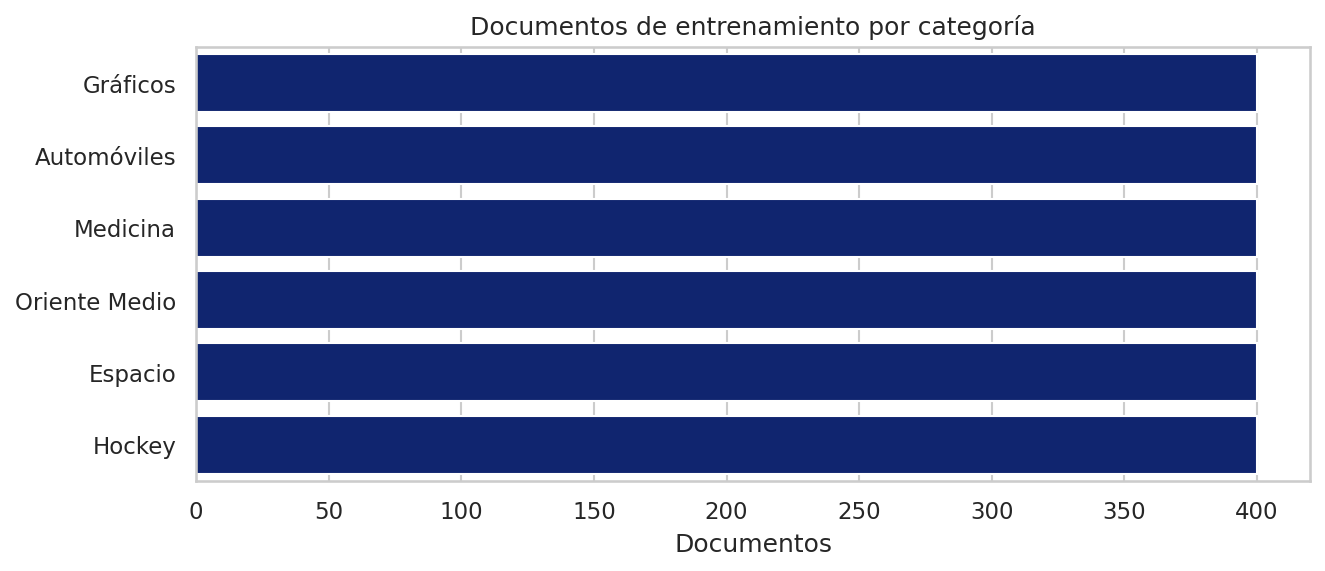

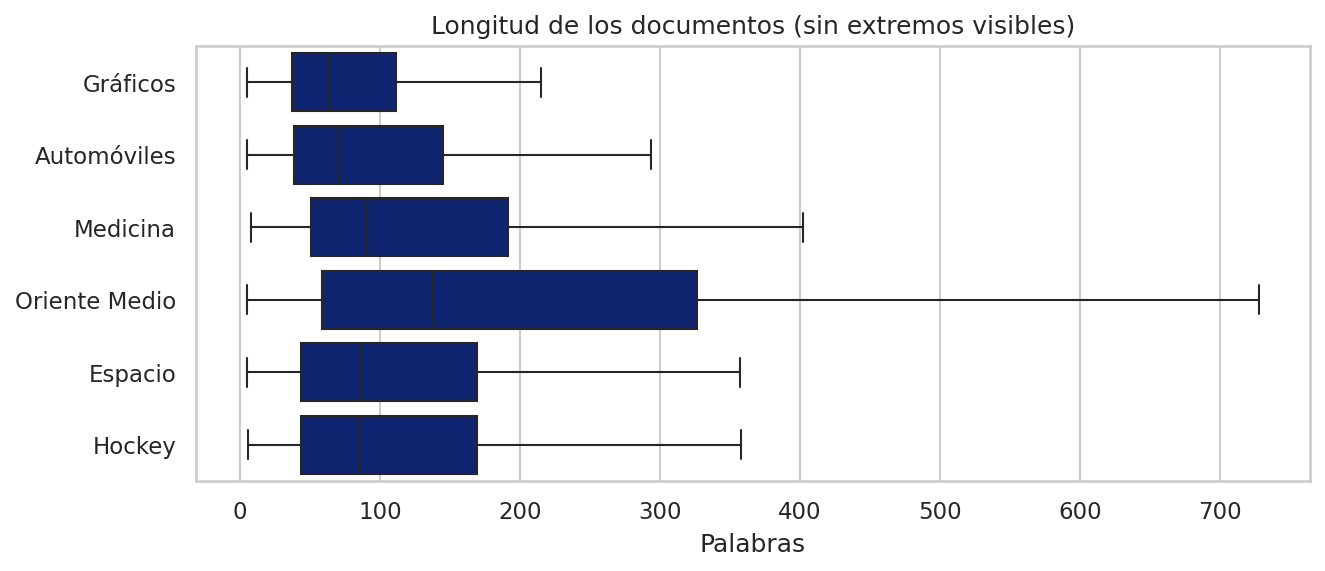

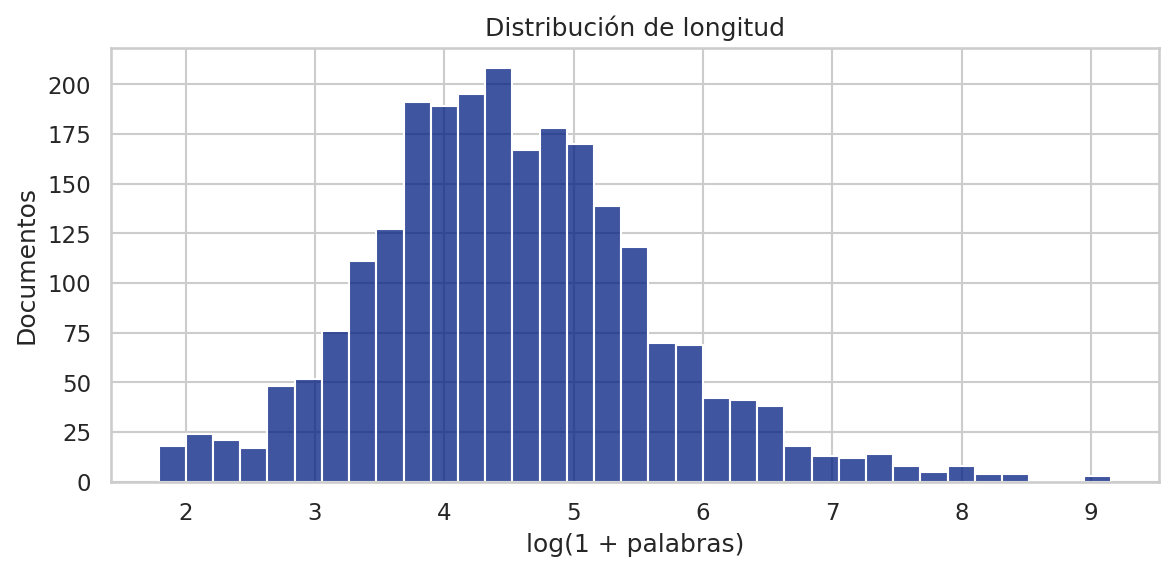

In [13]:
tabla("eda", "eda")
mostrar("eda", "01_categorias", "02_longitudes", "03_histograma")

### BoW, TF-IDF y SVD
Comparamos las representaciones dispersas y la varianza retenida por la reducción dimensional.

,representacion,documentos,caracteristicas,no_ceros,esparsidad
0,BoW,2400,10000,138733,0.9942
1,TF-IDF,2400,10000,138733,0.9942


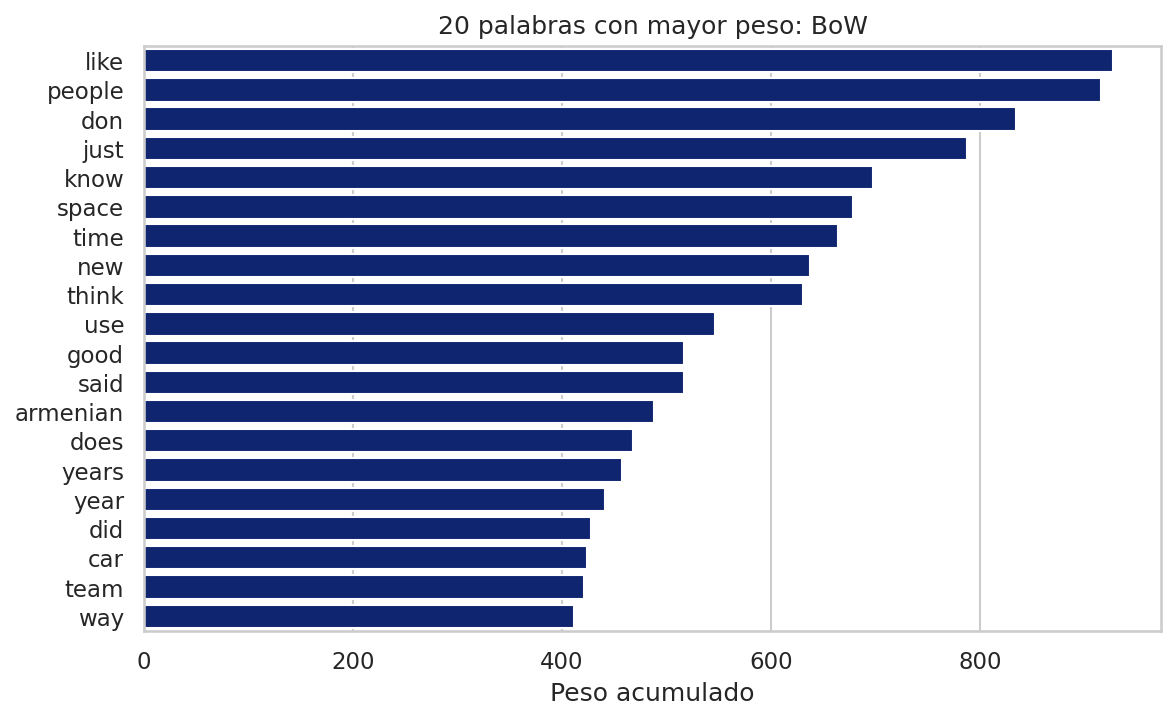

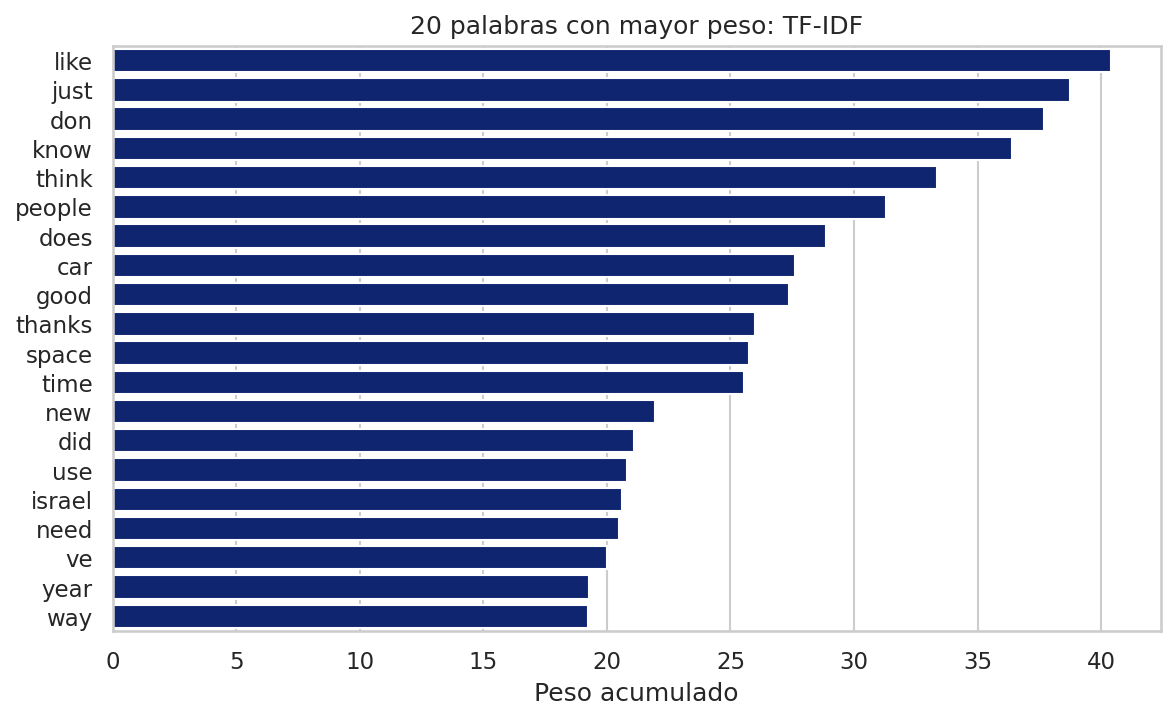

In [14]:
tabla("eda", "representaciones")
mostrar("eda", "04_terminos_BoW", "04_terminos_TF-IDF")

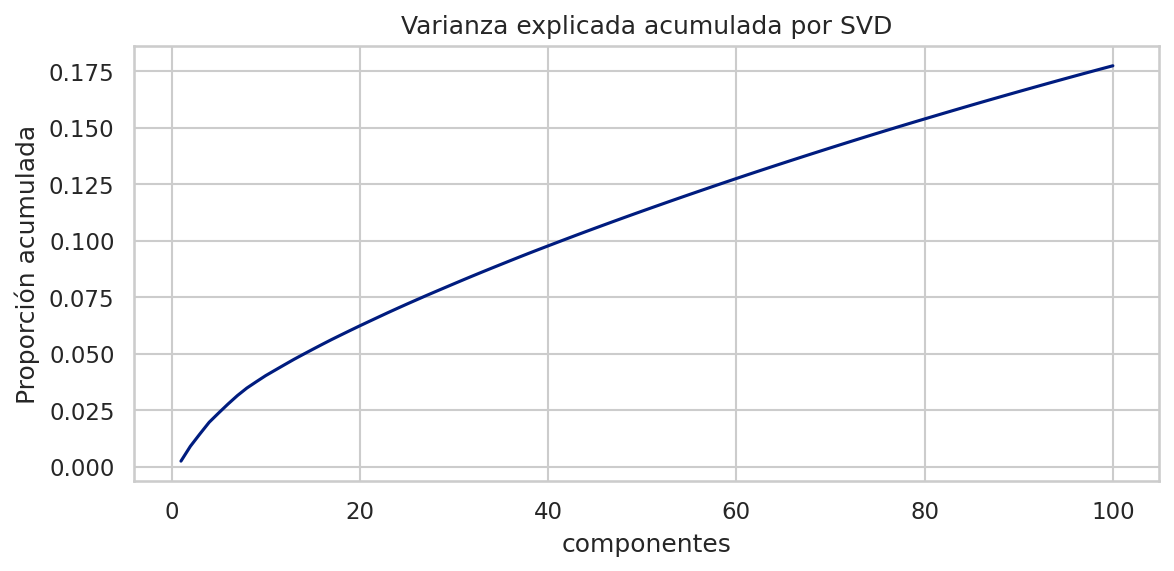

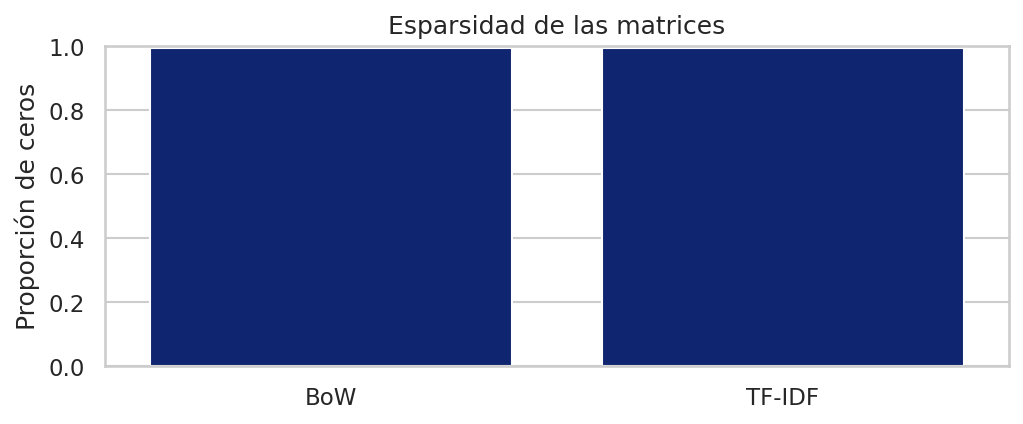

In [15]:
mostrar("eda", "05_varianza_svd", "06_esparsidad")

## 2. Aprendizaje no supervisado
Los agrupamientos se ajustan sin etiquetas. La silueta coseno y la cobertura permiten seleccionar configuraciones; la NMI evalúa posteriormente su concordancia con las categorías.

### K-means, aglomerativo, DBSCAN y mezcla gaussiana
Se comparan las configuraciones en TF-IDF y SVD-50.

In [16]:
"""Agrupamiento independiente del clasificador, sin acceso a etiquetas durante el ajuste."""
from itertools import product
from time import perf_counter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from joblib import Parallel, delayed
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.metrics.pairwise import cosine_distances
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import normalize

In [17]:
def configuraciones(reducida):
    for k in [3, 4, 6, 8, 10]:
        yield "K-means", f"k={k}", KMeans(k, n_init=10, random_state=SEMILLA), False
        yield "Aglomerativo", f"k={k}", AgglomerativeClustering(n_clusters=k, metric="precomputed", linkage="average"), True
        if reducida:
            yield "Mezcla gaussiana EM", f"k={k}", GaussianMixture(k, covariance_type="diag", n_init=2, random_state=SEMILLA), False
    for eps, minimo in product([.2, .35, .5, .65, .8], [5, 10]):
        yield "DBSCAN", f"eps={eps}, min={minimo}", DBSCAN(eps=eps, min_samples=minimo, metric="precomputed", n_jobs=1), True

In [18]:
def ajustar(nombre, parametros, modelo, precomputado, X, D, representacion):
    inicio = perf_counter()
    etiquetas = modelo.fit_predict(D if precomputado else X)
    tiempo_ajuste = perf_counter()-inicio
    inicio = perf_counter()
    valido = etiquetas != -1
    grupos = len(np.unique(etiquetas[valido]))
    cobertura = valido.mean()
    sil = (silhouette_score(D[np.ix_(valido, valido)], etiquetas[valido], metric="precomputed")
           if 2 <= grupos < valido.sum() else np.nan)
    # Penalización explícita por descartar documentos como ruido.
    criterio = cobertura * (1 + sil) / 2 if np.isfinite(sil) else np.nan
    return {"algoritmo": nombre, "parametros": parametros, "representacion": representacion,
            "grupos": grupos, "cobertura": cobertura, "silhouette": sil, "criterio": criterio,
            "segundos_ajuste": tiempo_ajuste, "segundos_silhouette": perf_counter()-inicio}, etiquetas

In [19]:
def ejecutar_agrupamiento(datos):
    etapa = "agrupamiento"
    # Las etiquetas reales no se consultan hasta terminar todas las configuraciones.
    v = vectorizador()
    X = v.fit_transform(datos.texto).astype(np.float32)
    svd = TruncatedSVD(50, random_state=SEMILLA)
    Z = normalize(svd.fit_transform(X))
    resultados = []
    for nombre, matriz in [("TF-IDF", X), ("SVD-50", Z)]:
        D = cosine_distances(matriz)
        np.clip(D, 0, 2, out=D)
        np.fill_diagonal(D, 0)
        resultados.extend(Parallel(n_jobs=-1, prefer="threads")(
            delayed(ajustar)(a, p, m, pre, matriz, D, nombre)
            for a, p, m, pre in configuraciones(nombre == "SVD-50")))
    tabla = pd.DataFrame([fila for fila, _ in resultados])
    ganador = tabla.criterio.idxmax()
    # Evaluación externa exclusivamente posterior a la selección interna.
    y = datos.categoria
    tabla["ARI"] = [adjusted_rand_score(y, lab) for _, lab in resultados]
    tabla["NMI"] = [normalized_mutual_info_score(y, lab) for _, lab in resultados]
    tabla["seleccionado"] = tabla.index == ganador
    guardar(tabla, etapa, "configuraciones")
    seleccion = tabla.dropna(subset=["criterio"]).sort_values("criterio", ascending=False)
    mejores = seleccion.groupby(["algoritmo", "representacion"], sort=False).head(1)
    guardar(mejores, etapa, "mejores")
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.barplot(data=mejores, y="algoritmo", x="silhouette", hue="representacion", ax=ax)
    ax.set(title="Mejores configuraciones por criterio interno", ylabel="")
    figura(etapa, "01_silhouette", fig)
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.barplot(data=mejores, y="algoritmo", x="ARI", hue="representacion", ax=ax)
    ax.set(title="Concordancia externa posterior: ARI", ylabel="")
    figura(etapa, "02_ari", fig)
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.scatterplot(data=tabla, x="silhouette", y="NMI", hue="algoritmo", style="representacion", size="cobertura", ax=ax)
    ax.set(title="Calidad geométrica frente a concordancia temática")
    figura(etapa, "03_concordancia", fig)
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.scatterplot(data=tabla, x="grupos", y="criterio", hue="algoritmo", style="representacion", ax=ax)
    ax.set(title="Número de grupos y criterio interno")
    figura(etapa, "04_numero_grupos", fig)
    lab = resultados[ganador][1]
    guardar(pd.DataFrame({"huella": datos.huella, "categoria": y, "grupo": lab}), etapa, "asignaciones")
    # Conservar también el corte K-means de diez grupos en SVD-50, para
    # comparar geometrías y medoides sin asumir que siempre gana internamente.
    i_km = tabla.index[(tabla.algoritmo=="K-means") & (tabla.representacion=="SVD-50")
                       & (tabla.parametros=="k=10")][0]
    guardar(pd.DataFrame({"huella":datos.huella,"categoria":y,
                         "grupo":resultados[i_km][1]}),etapa,"asignaciones_kmeans10")
    mapa = pd.DataFrame({"Componente 1": Z[:, 0], "Componente 2": Z[:, 1],
                         "Categoría": y, "Grupo": lab.astype(str)})
    fig, axs = plt.subplots(1, 2, figsize=(13, 5))
    for ax, hue in zip(axs, ["Grupo", "Categoría"]):
        sns.scatterplot(data=mapa, x="Componente 1", y="Componente 2", hue=hue, s=12, alpha=.65, ax=ax)
        ax.set_title(hue)
    figura(etapa, "05_proyeccion", fig)
    cruzada = pd.crosstab(y, lab, normalize="index")
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.heatmap(cruzada, annot=True, fmt=".2f", cmap="Blues", ax=ax)
    ax.set(title="Categorías originales frente al agrupamiento seleccionado", xlabel="Grupo", ylabel="Categoría")
    figura(etapa, "06_cruzada", fig)
    filas = []
    for grupo in np.unique(lab):
        indices = np.flatnonzero(lab == grupo)
        centro = np.asarray(X[indices].mean(axis=0)).ravel()
        palabras = v.get_feature_names_out()[centro.argsort()[-12:][::-1]]
        # Ejemplos cercanos al centro temático, sin cabeceras ni correos.
        cercanos = np.asarray(X[indices] @ centro).ravel().argsort()[-2:][::-1]
        ejemplos = [" ".join(datos.texto.iloc[indices[i]].split()[:30]) for i in cercanos]
        filas.append({"grupo": int(grupo), "documentos": len(indices), "palabras": ", ".join(palabras),
                      "ejemplo_1": ejemplos[0], "ejemplo_2": ejemplos[-1]})
    guardar(pd.DataFrame(filas), etapa, "interpretacion")

    fig, ax = plt.subplots(figsize=(10,5))
    sns.boxplot(data=tabla, y="algoritmo", x="segundos_ajuste", hue="representacion", ax=ax)
    ax.set(title="Costo de ajuste por configuración (con ejecución paralela)", xlabel="Segundos de pared", ylabel="", xscale="log")
    figura(etapa, "07_tiempos", fig)
    fig, axs = plt.subplots(1,2,figsize=(12,5))
    for ax, (rep, sub) in zip(axs, tabla.loc[tabla.algoritmo.eq("DBSCAN")].groupby("representacion")):
        sub = sub.assign(eps=sub.parametros.str.extract(r"eps=([^,]+)")[0].astype(float),
                         minimo=sub.parametros.str.extract(r"min=(\d+)")[0].astype(int))
        sns.heatmap(sub.pivot(index="minimo", columns="eps", values="cobertura"), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
        ax.set_title(rep)
    fig.suptitle("DBSCAN: proporción de documentos no clasificados como ruido")
    figura(etapa, "08_cobertura_dbscan", fig)

In [20]:
ejecutar_etapa(ejecutar_agrupamiento)

In [21]:
tabla("agrupamiento", "mejores", ["algoritmo","representacion","parametros","grupos","cobertura","silhouette","NMI"])

,algoritmo,representacion,parametros,grupos,cobertura,silhouette,NMI
32,K-means,SVD-50,k=10,10,1.0000,0.1534,0.5417
34,Mezcla gaussiana EM,SVD-50,k=10,10,1.0000,0.1102,0.5436
21,Aglomerativo,SVD-50,k=3,3,1.0000,0.0871,0.0275
6,K-means,TF-IDF,k=8,8,1.0000,0.0150,0.4746
1,Aglomerativo,TF-IDF,k=3,3,1.0000,0.0109,0.0012
18,DBSCAN,TF-IDF,"eps=0.8, min=5",24,0.6418,-0.0084,0.0662
35,DBSCAN,SVD-50,"eps=0.2, min=5",40,0.4197,0.2172,0.3582


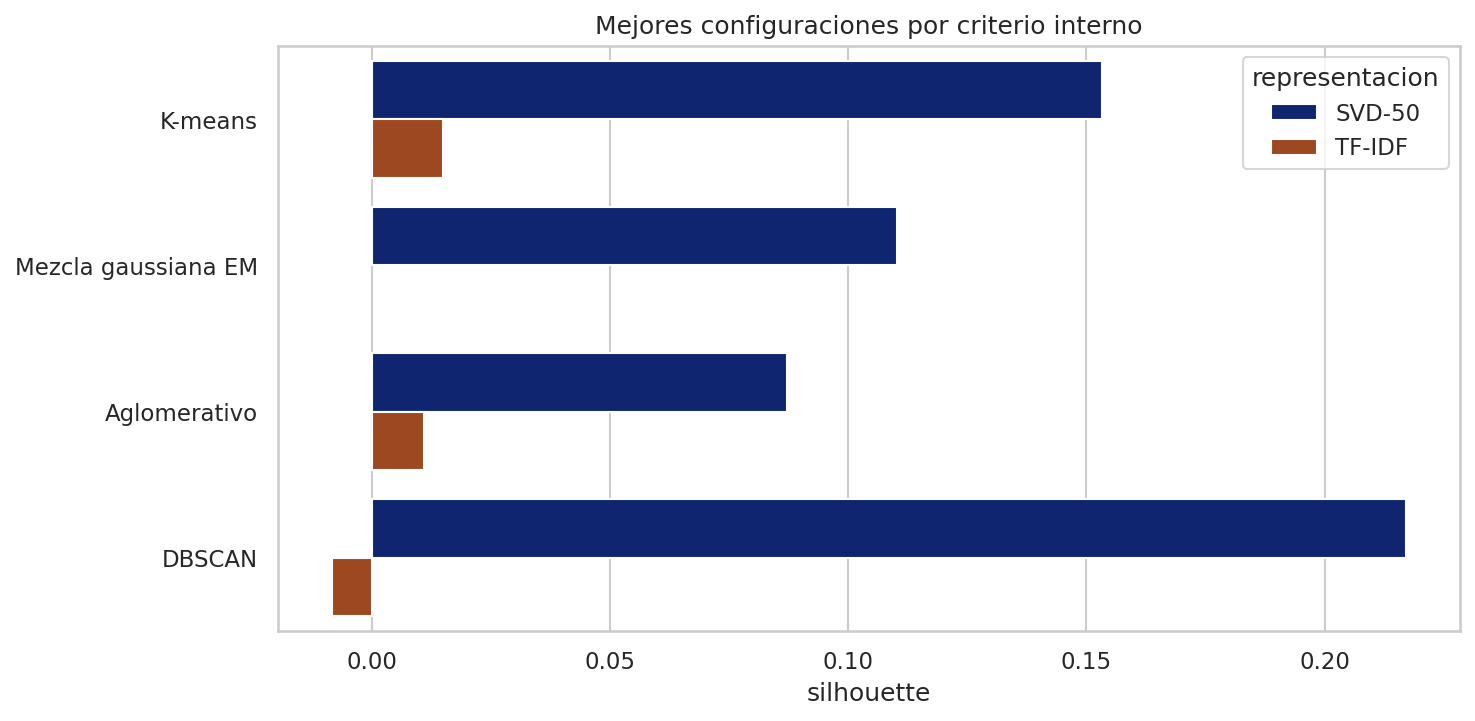

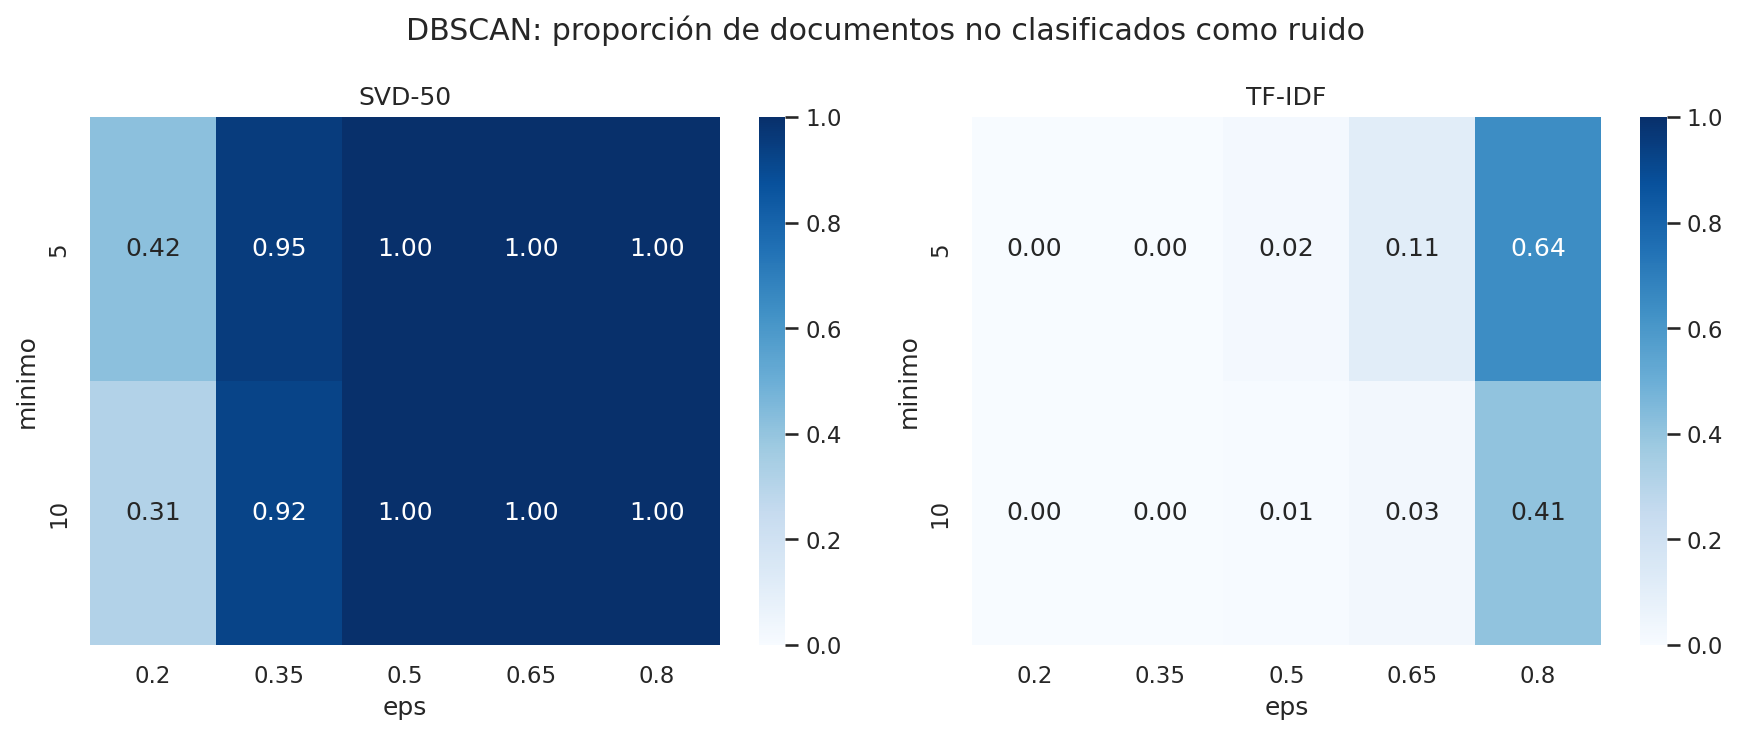

In [22]:
mostrar("agrupamiento", "01_silhouette", "08_cobertura_dbscan")

### Seis proyecciones bidimensionales
Todos los métodos reciben la misma representación SVD-100. Se mide fidelidad de vecindad con 15 vecinos.

In [23]:
"""análisis anterior: seis vistas bidimensionales de una misma representación."""
from time import perf_counter
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA, FastICA, TruncatedSVD
from sklearn.manifold import TSNE, Isomap, SpectralEmbedding, trustworthiness
from sklearn.neighbors import kneighbors_graph
from scipy.sparse.csgraph import connected_components

METODOS = ["PCA", "ICA", "t-SNE", "UMAP", "Isomap", "Spectral Embedding"]

In [24]:
def proyectar(X):
    from umap import UMAP
    # Entrada idéntica para los seis métodos; nunca se entregan etiquetas.
    inicio = perf_counter()
    Z = TruncatedSVD(100, random_state=SEMILLA).fit_transform(X)
    tiempo_svd = perf_counter() - inicio
    grafo = kneighbors_graph(Z, 15, mode="connectivity", n_jobs=-1)
    componentes = connected_components(grafo, directed=False, return_labels=False)
    modelos = {
        "PCA": PCA(n_components=2, svd_solver="full"),
        "ICA": FastICA(n_components=2, random_state=SEMILLA, max_iter=2000,
                       tol=1e-3, whiten="unit-variance"),
        "t-SNE": TSNE(n_components=2, random_state=SEMILLA, init="pca",
                      learning_rate="auto", perplexity=30, n_jobs=-1),
        "UMAP": UMAP(n_components=2, random_state=SEMILLA, n_neighbors=15,
                     min_dist=.1, metric="euclidean", n_jobs=1),
        "Isomap": Isomap(n_components=2, n_neighbors=15, n_jobs=-1),
        "Spectral Embedding": SpectralEmbedding(n_components=2,
                      random_state=SEMILLA, n_neighbors=15, n_jobs=-1),
    }
    coordenadas, filas, avisos = {}, [], {}
    for nombre, modelo in modelos.items():
        print(f"Proyectando {nombre}", flush=True)
        inicio = perf_counter()
        with warnings.catch_warnings(record=True) as registrados:
            warnings.simplefilter("always")
            Y = modelo.fit_transform(Z)
        tiempo = perf_counter()-inicio
        if Y.shape != (len(Z), 2) or not np.isfinite(Y).all():
            raise ValueError(f"Coordenadas inválidas: {nombre}")
        coordenadas[nombre] = Y
        avisos[nombre] = list(dict.fromkeys(str(a.message) for a in registrados))
        filas.append({"metodo": nombre, "documentos": len(Z),
                      "segundos_proyeccion": tiempo,
                      "trustworthiness_15": trustworthiness(Z, Y, n_neighbors=15)})
    metadata = {"componentes_svd": 100, "segundos_svd": tiempo_svd,
                "componentes_grafo_15": int(componentes),
                "semilla": SEMILLA, "avisos": avisos,
                "varianza_pca_2d": float(modelos["PCA"].explained_variance_ratio_.sum()),
                "parametros": {n: m.get_params() for n,m in modelos.items()}}
    return coordenadas, pd.DataFrame(filas), metadata

In [25]:
def alinear_grupos(datos, asignaciones):
    """Recuperar el agrupamiento ya seleccionado por huella, no por orden de filas."""
    if not datos.huella.is_unique or not asignaciones.huella.is_unique:
        raise ValueError("Huellas duplicadas")
    if set(datos.huella) != set(asignaciones.huella):
        raise ValueError("La muestra no coincide con análisis anterior")
    grupos = asignaciones.set_index("huella").loc[datos.huella]
    if not np.array_equal(grupos.categoria.to_numpy(), datos.categoria.to_numpy()):
        raise ValueError("Las categorías no coinciden")
    return grupos.grupo.to_numpy()

In [26]:
def tabla_coordenadas(coordenadas, datos, grupos):
    return pd.concat([
        pd.DataFrame({"metodo": nombre, "huella": datos.huella.to_numpy(),
                      "x": Y[:,0], "y": Y[:,1],
                      "categoria": datos.categoria.to_numpy(), "grupo": grupos})
        for nombre, Y in coordenadas.items()
    ], ignore_index=True)

In [27]:
def dashboard(tabla, etapa, variable, nombre, titulo):
    # Colores y orden de puntos idénticos en los seis paneles.
    tabla = tabla.copy()
    if variable == "grupo":
        tabla[variable] = tabla[variable].map(lambda g: "Ruido" if g == -1 else f"Grupo {g}")
        orden = [f"Grupo {g}" for g in sorted(tabla.grupo.str.replace("Grupo ", "", regex=False)
                    .loc[tabla.grupo.ne("Ruido")].astype(int).unique())]
        if "Ruido" in tabla.grupo.values:
            orden.append("Ruido")
    else:
        orden = sorted(tabla[variable].unique())
    paleta = dict(zip(orden, sns.color_palette("dark", n_colors=len(orden))))
    if "Ruido" in paleta:
        paleta["Ruido"] = (.55,.55,.55)
    fig, axs = plt.subplots(2,3,figsize=(15,9))
    for ax, metodo in zip(axs.flat, METODOS):
        sub = tabla.loc[tabla.metodo.eq(metodo)]
        sns.scatterplot(data=sub, x="x", y="y", hue=variable, hue_order=orden,
                        palette=paleta, s=11, alpha=.64, linewidth=0,
                        legend=False, ax=ax)
        ax.set(title=metodo, xlabel="", ylabel="", xticks=[], yticks=[])
        ax.set_aspect("equal", adjustable="datalim")
    from matplotlib.lines import Line2D
    handles = [Line2D([], [], marker="o", linestyle="none", color=paleta[g],
                      markersize=6, label=g) for g in orden]
    fig.legend(handles=handles, loc="lower center", ncol=min(6,len(orden)),
               frameon=False, title="Categoría real" if variable=="categoria" else "Grupo descubierto")
    fig.suptitle(titulo, fontsize=17, y=.98)
    fig.tight_layout(rect=(0,.10,1,.94))
    guardar_figura(fig, etapa, nombre, dpi=220)
    plt.close(fig)

In [28]:
def ejecutar_proyecciones(datos):
    etapa = "proyecciones"
    asignaciones = leer("agrupamiento", "asignaciones")
    grupos = alinear_grupos(datos, asignaciones)
    X = vectorizador().fit_transform(datos.texto).astype(np.float32)
    coords, metricas, metadata = proyectar(X)
    tabla = tabla_coordenadas(coords, datos, grupos)
    guardar(tabla, etapa, "proyecciones_2d")
    guardar(metricas, etapa, "metricas_proyecciones")
    # Parámetros simples, serializables; no almacenar objetos de Python.
    metadata["parametros"] = {n: {k: str(v) for k,v in p.items()}
                              for n,p in metadata["parametros"].items()}
    json_guardar(metadata, etapa, "metadatos")
    dashboard(tabla, etapa, "categoria", "01_dashboard_categorias",
              "Seis proyecciones del corpus por categoría real")
    dashboard(tabla, etapa, "grupo", "02_dashboard_grupos",
              "Seis proyecciones del corpus por grupo descubierto")

In [29]:
ejecutar_etapa(ejecutar_proyecciones)

Proyectando PCA
Proyectando ICA
Proyectando t-SNE
Proyectando UMAP
Proyectando Isomap
Proyectando Spectral Embedding


In [30]:
tabla("proyecciones", "metricas_proyecciones")

,metodo,documentos,segundos_proyeccion,trustworthiness_15
0,PCA,3300,0.0164,0.6197
1,ICA,3300,0.0547,0.6194
2,t-SNE,3300,38.8022,0.8782
3,UMAP,3300,23.9793,0.8377
4,Isomap,3300,7.9712,0.6194
5,Spectral Embedding,3300,2.1189,0.6113


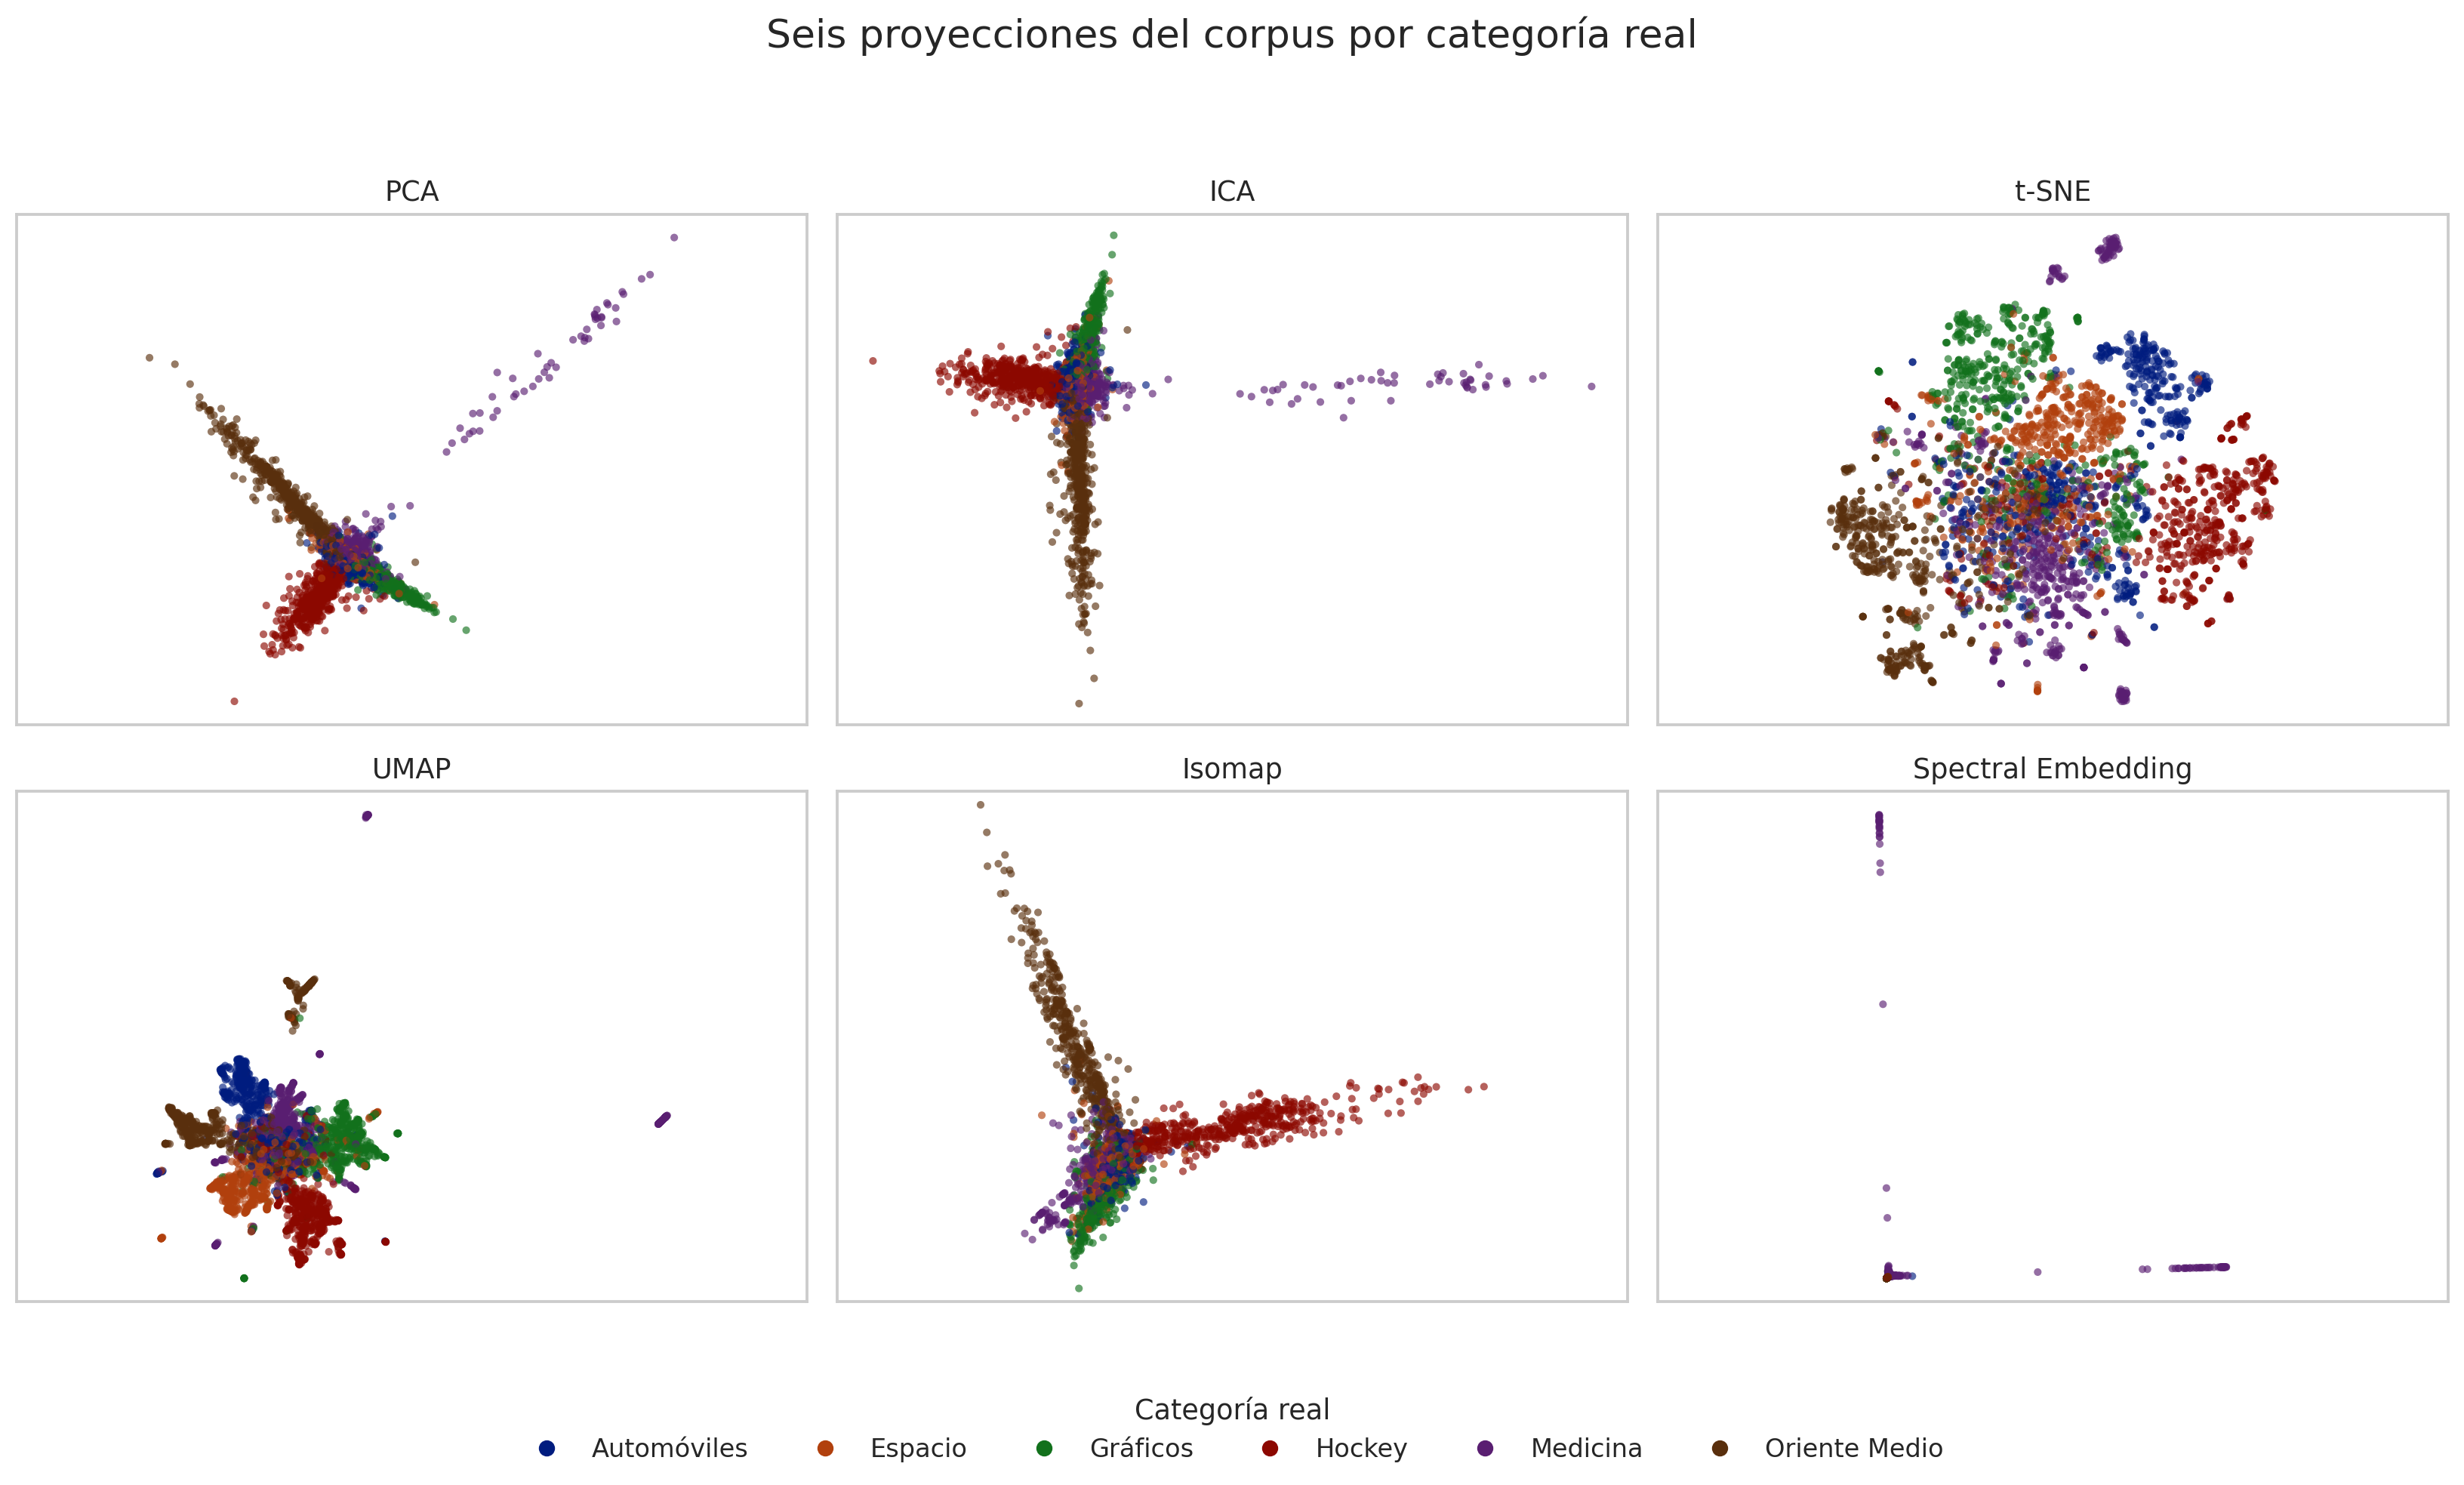

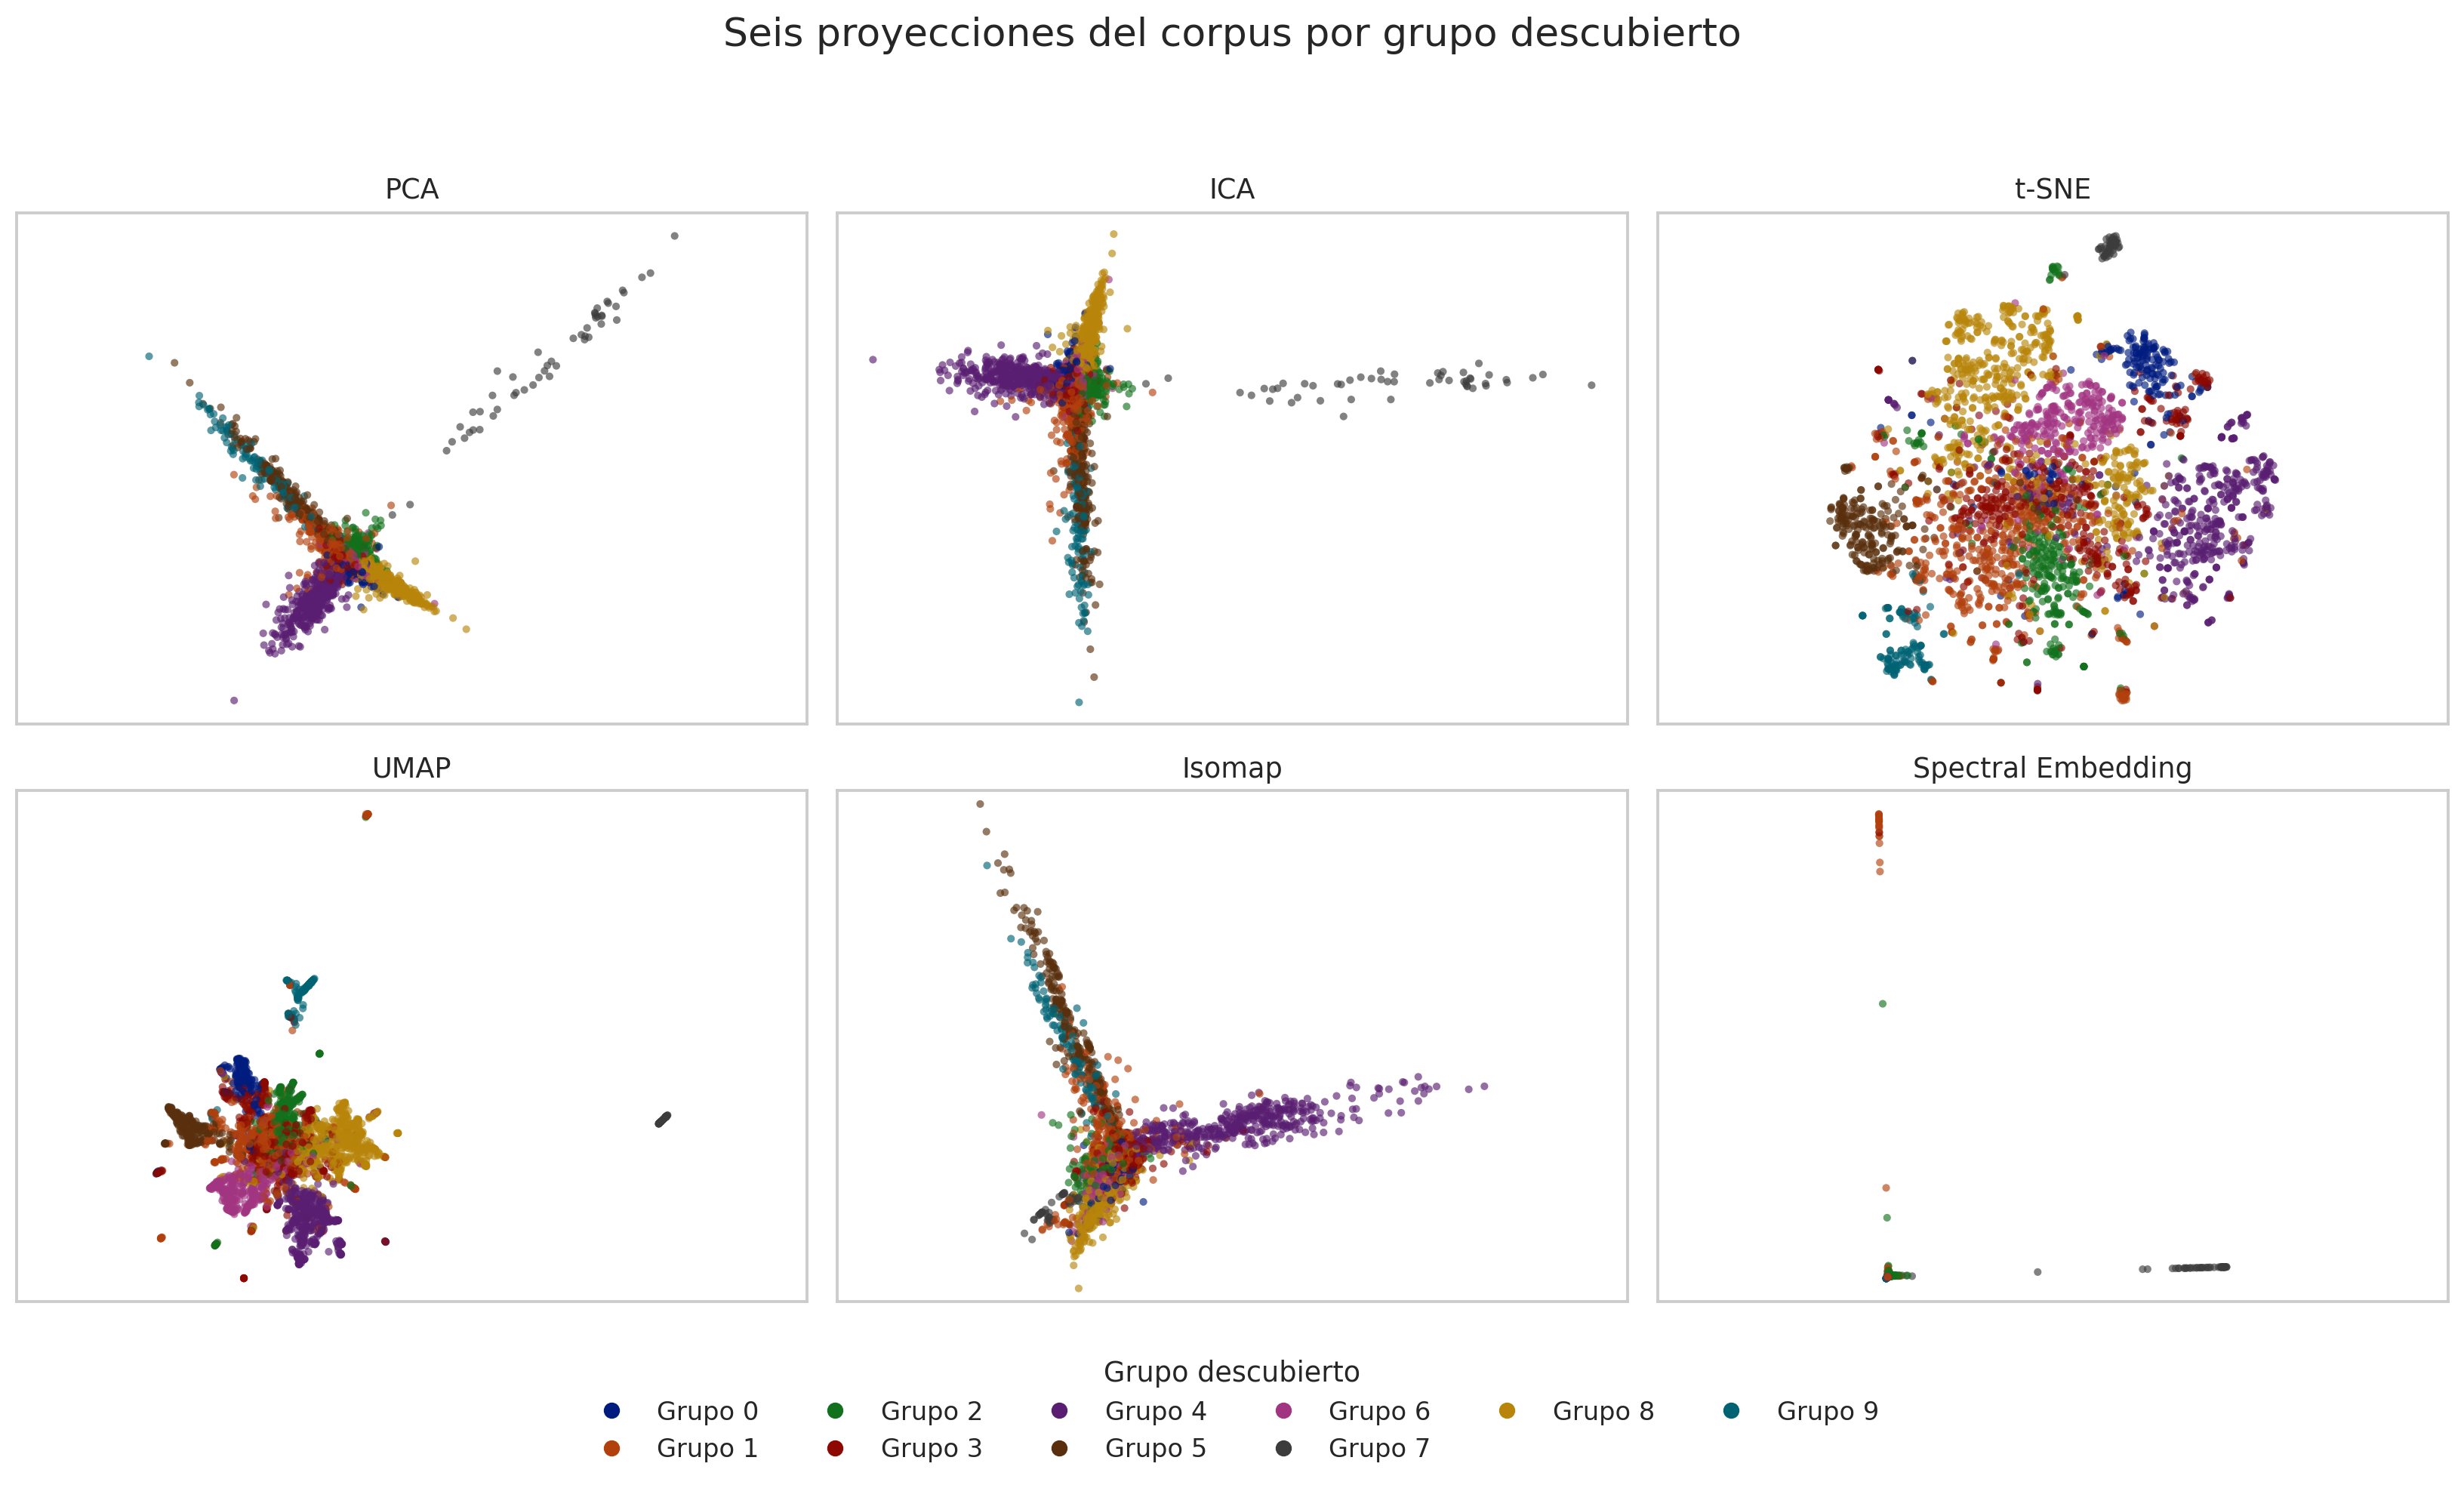

In [31]:
mostrar("proyecciones", "01_dashboard_categorias", "02_dashboard_grupos")

### Función común de validación
Se utilizará también para ampliar el estudio de dimensionalidad hasta 1,000 componentes.

In [32]:
"""Tres estudios controlados mediante los mismos pliegues de entrenamiento."""
from time import perf_counter
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from joblib import parallel_config
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

In [33]:
def evaluar(datos, grid):
    train = entrenamiento(datos)
    pipe = Pipeline([("texto", vectorizador()), ("svd", "passthrough"),
                     ("modelo", LogisticRegression(max_iter=1000, random_state=SEMILLA))])
    busqueda = GridSearchCV(pipe, grid, cv=cv(), scoring="f1_macro", n_jobs=-1,
                            refit=False, return_train_score=True, error_score="raise")
    inicio = perf_counter()
    with parallel_config(backend="loky", inner_max_num_threads=1):
        busqueda.fit(train.texto, train.categoria)
    r = pd.DataFrame(busqueda.cv_results_)
    return r.assign(segundos_busqueda=perf_counter()-inicio, error_entrenamiento=1-r.mean_train_score,
                    error_validacion=1-r.mean_test_score)

In [34]:
def ejecutar_generalizacion(datos):
    etapa = "generalizacion"
    r = evaluar(datos, {"texto": [vectorizador("BoW"), vectorizador("TF-IDF")]})
    r["representacion"] = ["BoW", "TF-IDF"]
    guardar(r, etapa, "representacion")
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.barplot(data=r, x="representacion", y="mean_test_score", ax=ax)
    ax.set(title="Efecto de la representación (C=1)", ylabel="F1 macro de CV", ylim=(0, 1))
    figura(etapa, "01_representacion", fig)
    r = evaluar(datos, {"texto__max_features": [1000, 3000, 10000, 20000]})
    r["caracteristicas_max"] = r.param_texto__max_features.astype(int)
    guardar(r, etapa, "dimensionalidad")
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.lineplot(data=r, x="caracteristicas_max", y="mean_test_score", marker="o", ax=ax)
    ax.set(title="Efecto del máximo de características", ylabel="F1 macro de CV", xlabel="Máximo de características")
    figura(etapa, "02_dimensionalidad", fig)
    r = evaluar(datos, {"svd": [TruncatedSVD(k, random_state=SEMILLA) for k in [25, 50, 100, 200]]})
    r["componentes"] = [25, 50, 100, 200]
    guardar(r, etapa, "componentes_svd")
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.lineplot(data=r, x="componentes", y="mean_test_score", marker="o", ax=ax)
    ax.set(title="Efecto de la dimensión latente SVD", ylabel="F1 macro de CV")
    figura(etapa, "03_componentes_svd", fig)
    r = evaluar(datos, {"modelo__C": [.001, .01, .1, 1, 10, 100, 1000]})
    r["C"] = r.param_modelo__C.astype(float)
    guardar(r, etapa, "complejidad")
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.lineplot(data=r.melt("C", ["error_entrenamiento", "error_validacion"], var_name="particion", value_name="error"),
                 x="C", y="error", hue="particion", marker="o", ax=ax)
    ax.set(xscale="log", title="Regularización y brecha de generalización", ylabel="Error = 1 − F1 macro")
    figura(etapa, "04_complejidad", fig)

### Inercia, dendrogramas y pesos TF-IDF
Se estudian los resultados de agrupamiento y se amplía el estudio SVD con los mismos cinco pliegues.

In [35]:
"""Diagnósticos complementarios: conservar protocolos y resultados originales."""
from time import perf_counter
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from scipy.spatial.distance import squareform
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.metrics.pairwise import cosine_distances
from sklearn.preprocessing import normalize
import matplotlib.pyplot as plt
import seaborn as sns

In [36]:
def ejecutar_diagnostico_ampliado(datos):
    etapa = "diagnosticos"
    previo = leer("agrupamiento", "asignaciones_kmeans10")
    assert datos.huella.is_unique and previo.huella.is_unique
    lab = datos[["huella"]].merge(previo[["huella", "grupo"]], on="huella",
                                    how="left", validate="one_to_one").grupo
    assert lab.notna().all() and len(lab) == len(previo) == 3300
    v = vectorizador()
    X = v.fit_transform(datos.texto).astype(np.float32)
    Z = normalize(TruncatedSVD(50, random_state=SEMILLA).fit_transform(X))
    filas, arboles = [], {}
    for rep, A in [("TF-IDF", X), ("SVD-50", Z)]:
        D = cosine_distances(A)
        np.clip(D, 0, 2, out=D)
        D = (D + D.T) / 2
        np.fill_diagonal(D, 0)
        for k in [3, 4, 6, 8, 10]:
            inicio = perf_counter()
            modelo = KMeans(k, n_init=10, random_state=SEMILLA).fit(A)
            filas.append({"representacion": rep, "k": k, "inercia": modelo.inertia_,
                          "silhouette": silhouette_score(D, modelo.labels_, metric="precomputed"),
                          "segundos": perf_counter()-inicio,
                          "ARI_grupos_guardados": adjusted_rand_score(lab, modelo.labels_)})
        # Enlace promedio con exactamente las distancias coseno del análisis original.
        L = linkage(squareform(D, checks=False), method="average")
        arboles[rep] = L
        guardar(pd.DataFrame(L, columns=["izquierda","derecha","distancia","n"]),
                etapa, "enlace_" + rep)
        corte = cut_tree(L, n_clusters=3).ravel()
        guardar(pd.DataFrame({"huella": datos.huella, "grupo": corte}),
                etapa, "aglomerativo_" + rep)
    tabla = pd.DataFrame(filas)
    guardar(tabla, etapa, "kmeans")
    fig, axs = plt.subplots(1,2,figsize=(10,4))
    for ax, y in zip(axs, ["inercia", "silhouette"]):
        sns.lineplot(data=tabla, x="k", y=y, hue="representacion", marker="o", ax=ax)
    figura(etapa, "01_kmeans", fig)
    for rep, L in arboles.items():
        fig, ax = plt.subplots(figsize=(10,4))
        dendrogram(L, truncate_mode="lastp", p=25, show_leaf_counts=True,
                   color_threshold=0, above_threshold_color="#203e51", ax=ax)
        ax.set(xlabel="Subárboles terminales (tamaño entre paréntesis)",
               ylabel="Distancia coseno media", title=rep)
        figura(etapa, "02_dendrograma_" + rep, fig)
    # Los términos se ordenan por peso medio TF-IDF, NO por frecuencia ni por un peso simulado.
    palabras = v.get_feature_names_out()
    pesos = []
    for g in sorted(lab.unique()):
        centro = np.asarray(X[lab.to_numpy() == g].mean(axis=0)).ravel()
        for rango, j in enumerate(centro.argsort()[-12:][::-1], 1):
            pesos.append({"grupo": int(g), "rango": rango, "palabra": palabras[j],
                          "peso_medio_tfidf": float(centro[j])})
    guardar(pd.DataFrame(pesos), etapa, "pesos_terminos")
    # Repetir el estudio SVD en los mismos cinco pliegues; ni ajuste ni selección en prueba.
    ks = [25,50,100,200,300,400,500,750,1000]
    scores = evaluar(datos, {"svd": [TruncatedSVD(k, random_state=SEMILLA) for k in ks]})
    scores["componentes"] = ks
    guardar(scores, etapa, "componentes_svd")
    fig, ax = plt.subplots(figsize=(7,4))
    sns.lineplot(data=scores, x="componentes", y="mean_test_score", marker="o", ax=ax)
    ax.set(ylabel="F1 macro CV", xlabel="Componentes SVD")
    figura(etapa, "03_svd", fig)

In [37]:
ejecutar_etapa(ejecutar_diagnostico_ampliado)

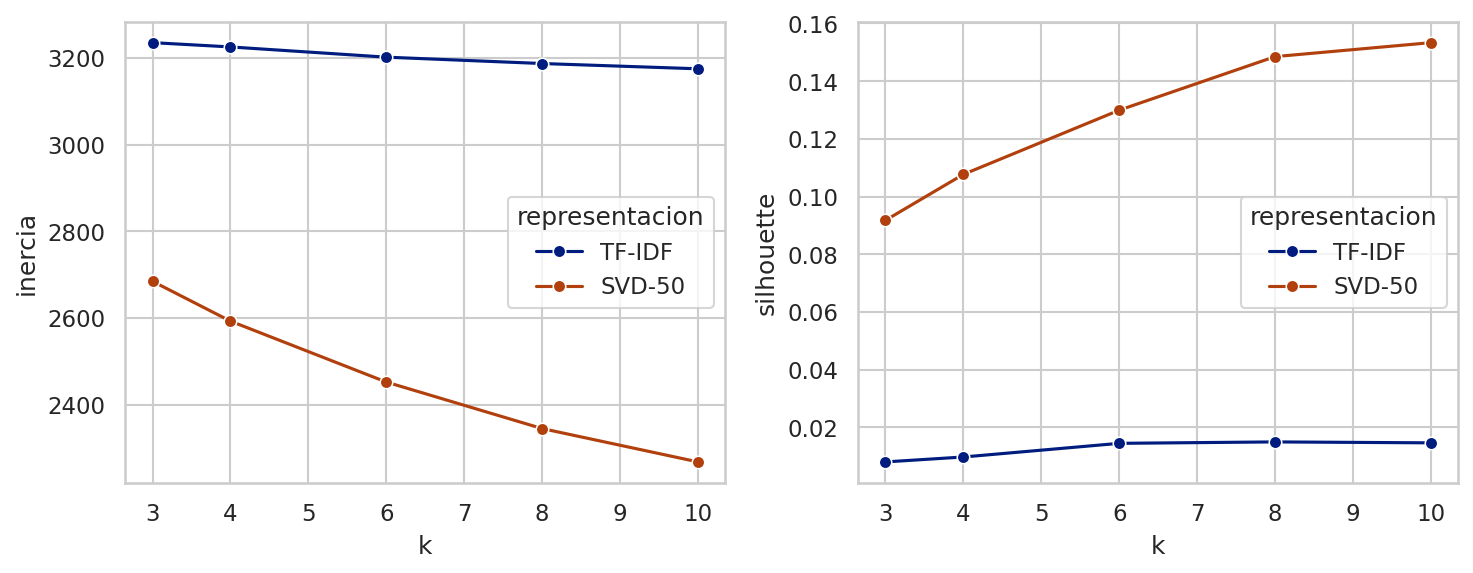

In [38]:
mostrar("diagnosticos", "01_kmeans")

### Medoides y DBSCAN
Se ordenan los documentos por distancia coseno media al resto de su grupo y se recuperan las asignaciones de DBSCAN.

In [39]:
"""Representantes reales de K-means y etiquetas de DBSCAN en SVD-50."""
import re
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.metrics import adjusted_rand_score, silhouette_score, normalized_mutual_info_score
from sklearn.metrics.pairwise import cosine_distances

In [40]:
def ejecutar_representantes(datos):
    etapa = "representantes"
    original = leer("agrupamiento", "asignaciones_kmeans10")
    alineado = datos[["huella"]].merge(original[["huella", "grupo"]], on="huella", validate="one_to_one")
    assert len(alineado) == len(datos) == len(original) == 3300
    v = vectorizador()
    X = v.fit_transform(datos.texto).astype(np.float32)
    Z = normalize(TruncatedSVD(50, random_state=SEMILLA).fit_transform(X))
    labels = alineado.grupo.to_numpy()
    assert len(np.unique(labels)) == 10
    D = cosine_distances(Z)
    np.clip(D, 0, 2, out=D)
    np.fill_diagonal(D, 0)
    filas = []
    vocab = v.get_feature_names_out()
    for g in sorted(np.unique(labels)):
        indices = np.flatnonzero(labels == g)
        # Medoide coseno = observación que minimiza la suma de distancias
        # a los miembros. Los rangos 2 y 3 son candidatos siguientes.
        costos = D[np.ix_(indices, indices)].astype(np.float64).sum(axis=1)
        centro = Z[indices].mean(axis=0)
        dist_centro = np.linalg.norm(Z[indices]-centro, axis=1)
        orden = np.lexsort((datos.huella.iloc[indices].to_numpy(), costos))[:3]
        for rango, j in enumerate(orden, 1):
            i = indices[j]
            row = X[i]
            idx = row.indices[np.argsort(row.data)[::-1][:5]]
            filas.append(dict(grupo=int(g), rango=rango, huella=datos.huella.iloc[i],
                categoria=datos.categoria.iloc[i], n_grupo=len(indices),
                distancia_coseno_media=costos[j]/max(1,len(indices)-1),
                distancia_centroide=float(dist_centro[j]),
                terminos=", ".join(vocab[idx])))
    guardar(pd.DataFrame(filas), etapa, "representantes")
    mejores = leer("agrupamiento", "mejores")
    fila = mejores.loc[(mejores.algoritmo=="DBSCAN") & (mejores.representacion=="SVD-50")].iloc[0]
    eps, minimo = re.fullmatch(r"eps=([^,]+), min=(\d+)", fila.parametros).groups()
    db = DBSCAN(eps=float(eps), min_samples=int(minimo), metric="precomputed", n_jobs=1).fit_predict(D)
    valido = db != -1
    sil = silhouette_score(D[np.ix_(valido,valido)], db[valido], metric="precomputed")
    ari = adjusted_rand_score(datos.categoria, db)
    nmi = normalized_mutual_info_score(datos.categoria, db)
    assert np.isclose(valido.mean(), fila.cobertura)
    assert len(np.unique(db[valido])) == fila.grupos
    assert np.isclose(sil, fila.silhouette, atol=1e-6)
    assert np.isclose(ari, fila.ARI) and np.isclose(nmi, fila.NMI)
    guardar(pd.DataFrame({"huella":datos.huella,"grupo_dbscan":db}), etapa, "dbscan")
    guardar(pd.DataFrame([dict(eps=float(eps), min_samples=int(minimo), grupos=int(fila.grupos),
        cobertura=valido.mean(), silhouette=sil, ARI=ari, NMI=nmi)]), etapa, "metricas_dbscan")

In [41]:
ejecutar_etapa(ejecutar_representantes)

In [42]:
tabla("representantes", "representantes", ["grupo","rango","categoria","terminos","distancia_coseno_media"])

,grupo,rango,categoria,terminos,distancia_coseno_media
0,0,1,Automóviles,"car, probe, ford, automatic, speed",0.3284
1,0,2,Automóviles,"car, probe, passengers, rear, bag",0.3404
2,0,3,Automóviles,"car, audi, engine, steering, turbo",0.3502
3,1,1,Medicina,"interviews, numbers, admissions, schools, denial",0.6223
4,1,2,Medicina,"birth, risks, wife, humans, great",0.6231
5,1,3,Oriente Medio,"army, children, target, did, yeah",0.6350
6,2,1,Medicina,"sinus, yeast, sporanox, candida, symptoms",0.3902
7,2,2,Medicina,"mg, vitamin, kidney, oxalate, acid",0.4159
8,2,3,Medicina,"chromium, glucose, diet, labs, minerals",0.4214
9,3,1,Automóviles,"brake, cruise, ankle, signal, cc",0.6127


### Comparación visual de las proyecciones
Cada forma identifica una categoría original. En t-SNE se conservan las coordenadas y se cambia únicamente el color según el agrupamiento.

In [43]:
from scipy.cluster.hierarchy import cut_tree, dendrogram
from matplotlib.lines import Line2D
from sklearn.metrics import normalized_mutual_info_score

coords = leer("proyecciones", "proyecciones_2d")
asig = leer("agrupamiento", "asignaciones_kmeans10").rename(columns={"grupo":"grupo_kmeans"})
db = leer("representantes", "dbscan")
L = leer("diagnosticos", "enlace_SVD-50").to_numpy()
hojas = leer("diagnosticos", "aglomerativo_SVD-50")
part = leer("eda", "particiones")
assert hojas.huella.equals(part.huella)
assert len(coords)==6*len(part) and coords.groupby("metodo").huella.nunique().eq(len(part)).all()
cut = pd.DataFrame({"huella":hojas.huella, "aglomerativo":cut_tree(L,n_clusters=10).ravel()})
assert cut.aglomerativo.nunique()==10
clases = sorted(coords.categoria.unique())
pal = sns.color_palette("tab10",10)
colores = dict(zip(clases,pal))
formas = dict(zip(clases,["o","X","^","s","P","D"]))

In [44]:
def dibujar(ax, d, key, categorias=False):
    for grupo in sorted(d[key].unique()):
        color = colores[grupo] if categorias else ("#b0b0b0" if grupo==-1 else pal[int(grupo)%10])
        for clase in clases:
            q=d[(d[key]==grupo)&(d.categoria==clase)]
            ax.scatter(q.x,q.y,c=[color],marker=formas[clase],s=10,alpha=.25 if grupo==-1 else .65,linewidths=0)
    ax.set(xticks=[],yticks=[])
def leyenda_clases(ax):
    return ax.legend(handles=[Line2D([0],[0],marker=formas[c],color="black",ls="",label=c) for c in clases],
                     loc="upper center",bbox_to_anchor=(.5,-.05),ncol=3,frameon=False)

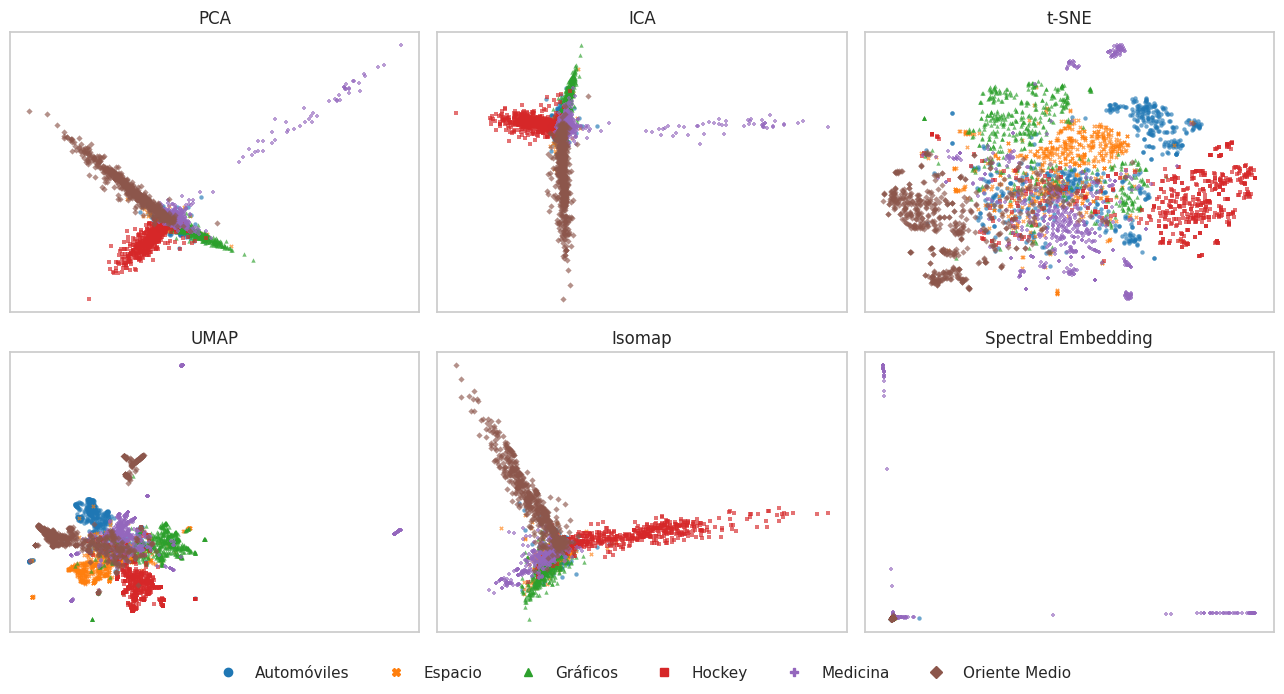

In [45]:
fig,axs=plt.subplots(2,3,figsize=(13,7))
for ax,(m,d) in zip(axs.flat,coords.groupby("metodo",sort=False)):
    dibujar(ax,d,"categoria",True); ax.set_title(m)
fig.legend(handles=[Line2D([0],[0],marker=formas[c],color=colores[c],ls="",label=c) for c in clases],loc="lower center",ncol=6,frameon=False)
fig.tight_layout(rect=[0,.06,1,1]);plt.show()

In [46]:
ts=coords.loc[coords.metodo=="t-SNE"].merge(cut,on="huella",validate="one_to_one").merge(db,on="huella",validate="one_to_one").merge(asig[["huella","grupo_kmeans"]],on="huella",validate="one_to_one")

In [47]:
def vista_tsne(key, titulo):
    fig,ax=plt.subplots(figsize=(9,5))
    dibujar(ax,ts,key)
    ax.set(title=titulo,xlim=(ts.x.min()-2,ts.x.max()+2),ylim=(ts.y.min()-2,ts.y.max()+2))
    leg=leyenda_clases(ax); ax.add_artist(leg)
    handles=[Line2D([0],[0],marker="o",color=pal[g],ls="",label=str(g)) for g in range(10)]
    if key=="grupo_dbscan": handles.append(Line2D([0],[0],marker="o",color="#b0b0b0",ls="",label="Ruido"))
    ax.legend(handles=handles,loc="upper center",bbox_to_anchor=(.5,-.17),ncol=6,frameon=False,title="Grupo (módulo 10)" if key=="grupo_dbscan" else "Grupo")
    fig.subplots_adjust(bottom=.25);plt.show()

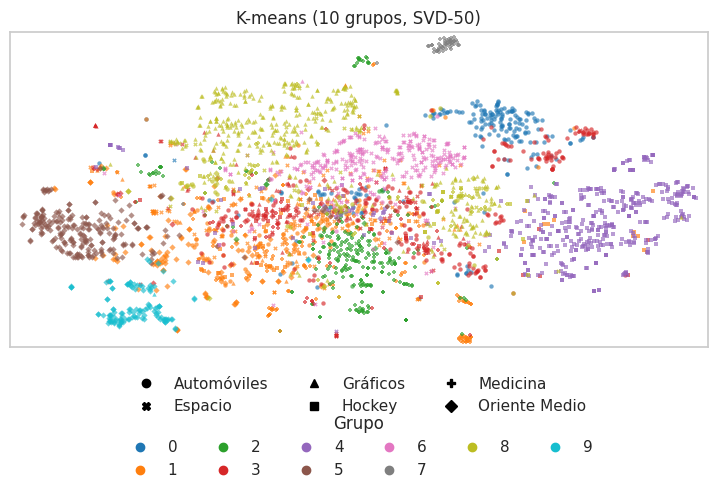

grupo_kmeans,0,1,2,3,4,5,6,7,8,9
categoria,,,,,,,,,,
Automóviles,0.360,0.138,0.011,0.416,0.000,0.004,0.009,0.002,0.058,0.002
Espacio,0.002,0.235,0.002,0.111,0.004,0.004,0.567,0.000,0.076,0.000
Gráficos,0.000,0.071,0.000,0.085,0.002,0.000,0.007,0.000,0.833,0.002
Hockey,0.000,0.091,0.000,0.051,0.825,0.000,0.000,0.000,0.033,0.000
Medicina,0.000,0.242,0.487,0.095,0.002,0.002,0.002,0.091,0.080,0.000
Oriente Medio,0.000,0.251,0.015,0.049,0.004,0.427,0.004,0.000,0.024,0.227


In [48]:
vista_tsne("grupo_kmeans","K-means (10 grupos, SVD-50)")
display(pd.crosstab(asig.categoria, asig.grupo_kmeans, normalize="index").round(3))

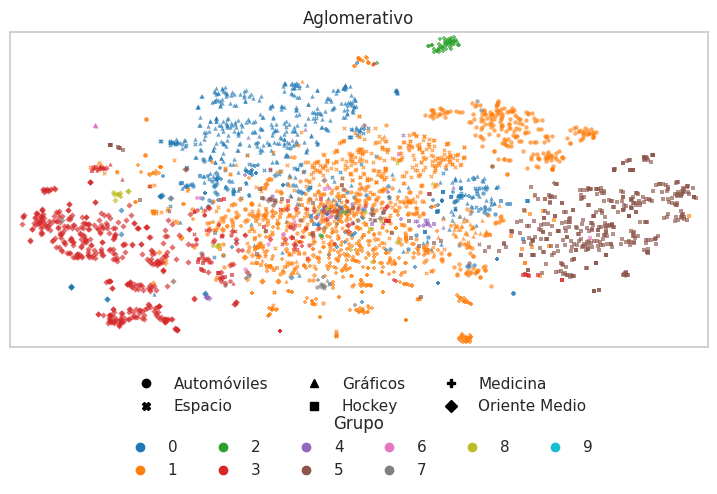

In [49]:
vista_tsne("aglomerativo","Aglomerativo")

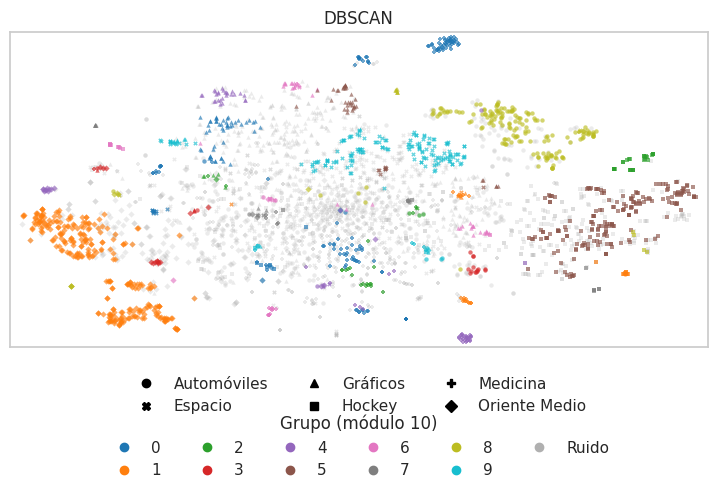

In [50]:
vista_tsne("grupo_dbscan","DBSCAN")

### Dendrograma coloreado
Corte en diez grupos. El color indica la clase mayoritaria de cada subárbol y la opacidad representa la pureza de Gini normalizada.

In [51]:
# Dendrograma: color de clase mayoritaria y opacidad de pureza Gini.
n=len(hojas)
counts=np.zeros((2*n-1,len(clases)),int)
for i,c in enumerate(part.categoria): counts[i,clases.index(c)]=1
for j,(a,b,_,_) in enumerate(L): counts[n+j]=counts[int(a)]+counts[int(b)]
p=counts/counts.sum(axis=1,keepdims=True)
pureza=np.clip(((p**2).sum(axis=1)-1/6)/(1-1/6),0,1)
dd=dendrogram(L,truncate_mode="lastp",p=10,no_plot=True)
pos={node:5+10*i for i,node in enumerate(dd["leaves"])}
height=dict.fromkeys(pos,0.)
etapa_jerarquia="jerarquia"
guardar(cut.rename(columns={"aglomerativo":"grupo_aglomerativo"}),etapa_jerarquia,"aglomerativo_10")
guardar(pd.DataFrame({"nodo":np.arange(2*n-1),"n":counts.sum(axis=1),
    "categoria_dominante":np.array(clases)[counts.argmax(axis=1)],"pureza_gini":pureza}),etapa_jerarquia,"pureza_nodos")

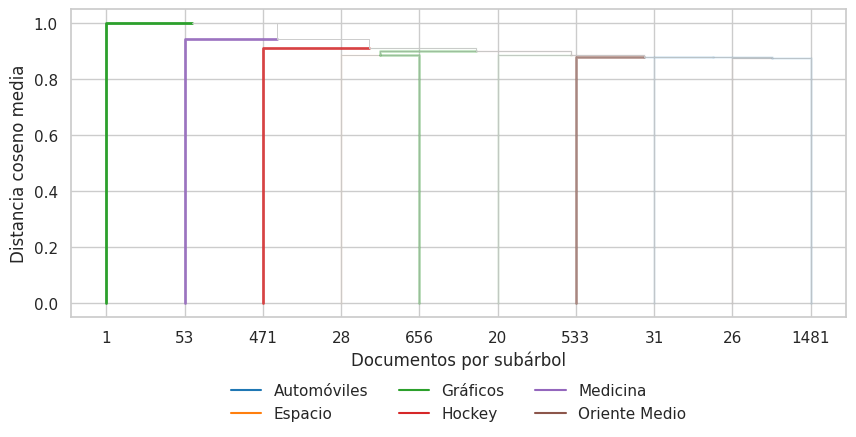

NMI, corte de 10: 0.38597509599710994


In [52]:
fig,ax=plt.subplots(figsize=(10,4))
for j,(a,b,h,_) in enumerate(L):
    a,b=int(a),int(b); node=n+j
    if a not in pos or b not in pos: continue
    x1,x2=pos[a],pos[b]; mid=(x1+x2)/2
    for child,x in [(a,x1),(b,x2)]:
        ax.plot([x,x,mid],[height[child],h,h],color="#cccccc",lw=.7)
        ax.plot([x,x,mid],[height[child],h,h],color=pal[counts[child].argmax()],alpha=pureza[child],lw=2)
    pos[node]=mid;height[node]=h
ax.set(xticks=[5+10*i for i in range(10)],xticklabels=[str(counts[x].sum()) for x in dd["leaves"]],xlabel="Documentos por subárbol",ylabel="Distancia coseno media")
ax.legend(handles=[Line2D([0],[0],color=pal[i],label=c) for i,c in enumerate(clases)],loc="upper center",bbox_to_anchor=(.5,-.17),ncol=3,frameon=False)
plt.show()
print("NMI, corte de 10:",normalized_mutual_info_score(part.categoria,cut.aglomerativo))

### Palabras representativas
Para interpretar los grupos se ordenan los términos por su peso medio TF-IDF.

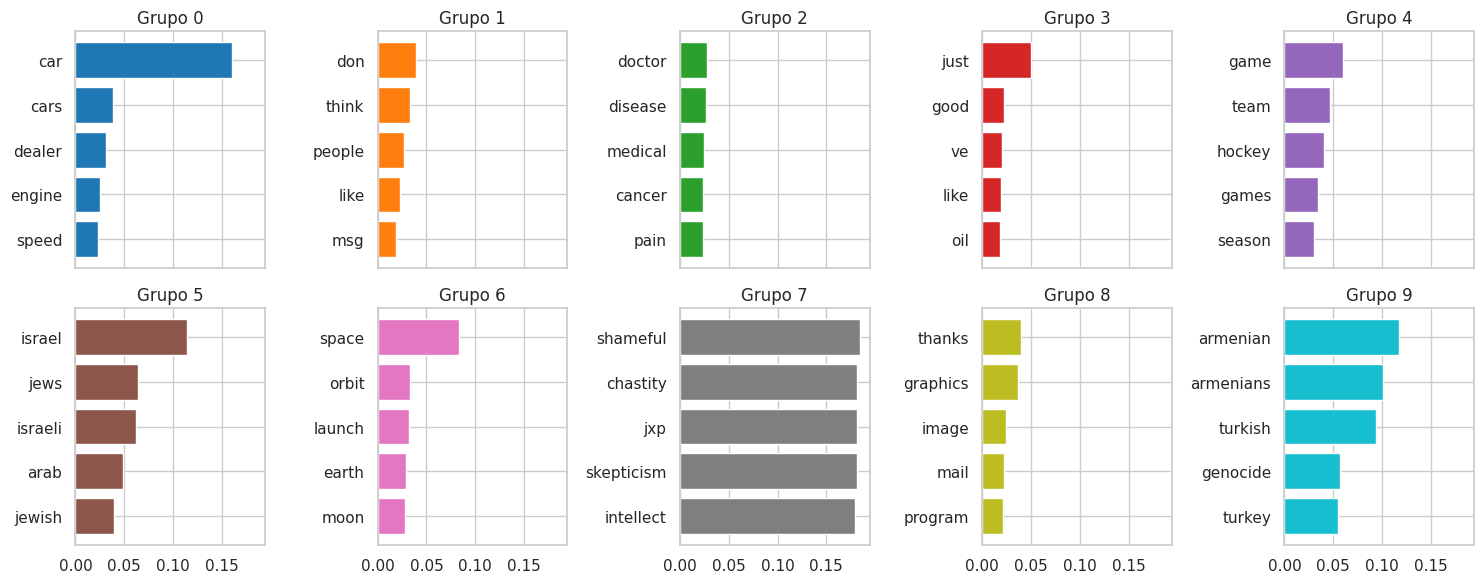

In [53]:
pesos=leer("diagnosticos", "pesos_terminos")
fig,axs=plt.subplots(2,5,figsize=(15,6),sharex=True)
for g,ax in enumerate(axs.flat):
    q=pesos.loc[pesos.grupo.eq(g)].nsmallest(5,"rango")
    ax.barh(q.palabra,q.peso_medio_tfidf,color=pal[g]);ax.invert_yaxis();ax.set_title(f"Grupo {g}")
fig.tight_layout();plt.show()

## 3. Aprendizaje supervisado
Siete clasificadores y tres ensambles. Se seleccionan hiperparámetros por F1 macro con cinco pliegues estratificados; el ajuste del vocabulario se realiza dentro de cada pipeline.

### Indicadores temáticos
Transformaciones inductivas para la extensión con grupos; se ajustan dentro del entrenamiento.

In [54]:
"""Transformación inductiva: etiquetas de grupos ajustadas sin supervisión."""
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import OneHotEncoder, Normalizer, FunctionTransformer

In [55]:
class GrupoOneHot(TransformerMixin, BaseEstimator):
    """Adaptador mínimo de predict a transform; no utiliza y."""
    def __init__(self, estimador, k=10):
        self.estimador = estimador
        self.k = k

    def fit(self, X, y=None):
        self.estimador_ = clone(self.estimador).fit(X)
        self.encoder_ = OneHotEncoder(categories=[np.arange(self.k)],
                                      handle_unknown="error", sparse_output=True)
        self.encoder_.fit(self.estimador_.predict(X).reshape(-1, 1))
        return self

    def transform(self, X):
        return self.encoder_.transform(self.estimador_.predict(X).reshape(-1, 1))

In [56]:
def caracteristicas(reducir=False, k=10, componentes=50):
    """Conservar exactamente la rama léxica y añadir dos bloques one-hot."""
    lexico = TruncatedSVD(componentes, random_state=SEMILLA) if reducir else FunctionTransformer()
    temas = Pipeline([
        ("svd", TruncatedSVD(componentes, random_state=SEMILLA)),
        ("normalizar", Normalizer()),
        ("grupos", FeatureUnion([
            ("kmeans", GrupoOneHot(KMeans(k, n_init=10, random_state=SEMILLA), k)),
            ("gmm", GrupoOneHot(GaussianMixture(k, covariance_type="diag", n_init=2,
                                               random_state=SEMILLA), k)),
        ])),
    ])
    return FeatureUnion([("lexico", lexico), ("temas", temas)])

### Bagging, votación y stacking
El metaclasificador XGBoost aprende sobre predicciones fuera de pliegue.

In [57]:
"""análisis anterior: bagging, votación y stacking sin reutilizar validación externa."""
from sklearn.ensemble import BaggingClassifier, VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier

In [58]:
def construir(bases, pipeline):
    """Bases preespecificadas: no usar hiperparámetros elegidos con toda la muestra.
    El stacking genera predicciones OOF dentro de cada fold externo.
    """
    estimadores = [(f"base{i}", pipeline(modelo, reducir))
                   for i, (modelo, _, reducir) in enumerate(bases.values())]
    bagging = pipeline(BaggingClassifier(
            estimator=LogisticRegression(max_iter=1000, random_state=SEMILLA),
            n_estimators=20, max_samples=1.0, bootstrap=True,
            n_jobs=1, random_state=SEMILLA), False)
    meta = GridSearchCV(
        XGBClassifier(objective="multi:softprob", eval_metric="mlogloss",
                      tree_method="hist", n_jobs=1, random_state=SEMILLA,
                      learning_rate=.1, verbosity=0),
        {"max_depth": [2, 3], "n_estimators": [50, 100]},
        cv=cv(), scoring="f1_macro", n_jobs=1)
    return {
        "Bagging (regresión logística)": bagging,
        "Votación (7 modelos)": VotingClassifier(estimators=estimadores, voting="hard", n_jobs=1),
        "Stacking (XGBoost)": StackingClassifier(
            estimators=estimadores, final_estimator=meta, cv=cv(),
            stack_method="auto", n_jobs=1, passthrough=False),
    }

### Diagnósticos de rendimiento
Tiempos, estabilidad, brecha de generalización y diversidad.

In [59]:
"""Visualizaciones que relacionan precisión, costo, estabilidad y diversidad."""
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import f1_score

In [60]:
def diagnosticos(etapa, ranking, metricas, pliegues, y, predicciones, clases, replicas, mejor):
    orden = ranking.modelo.tolist()
    datos = ranking.merge(metricas, on="modelo")
    fig, axs = plt.subplots(1, 2, figsize=(15, 6))
    sns.barplot(data=datos, y="modelo", x="segundos", order=orden, hue="familia", dodge=False, ax=axs[0])
    sns.barplot(data=datos, y="modelo", x="segundos_prediccion", order=orden, hue="familia", dodge=False, ax=axs[1])
    axs[0].set(title="Búsqueda CV y ajuste final", xlabel="Segundos de pared", ylabel="", xscale="log")
    axs[1].set(title="Predicción de todos los documentos de prueba", xlabel="Segundos de pared", ylabel="", xscale="log")
    figura(etapa, "06_tiempos", fig)
    fig, ax = plt.subplots(figsize=(11, 6))
    sns.boxplot(data=pliegues, y="modelo", x="F1_validacion", order=orden, ax=ax)
    sns.stripplot(data=pliegues, y="modelo", x="F1_validacion", order=orden, color="black", ax=ax)
    ax.set(title="Estabilidad de los modelos en los cinco pliegues", xlabel="F1 macro de validación", ylabel="")
    figura(etapa, "07_estabilidad_cv", fig)
    fig, ax = plt.subplots(figsize=(11, 6))
    promedios = pliegues.groupby("modelo")[["F1_entrenamiento","F1_validacion"]].mean().reset_index()
    sns.barplot(data=promedios.melt("modelo", var_name="particion", value_name="F1"),
                y="modelo", x="F1", hue="particion", order=orden, ax=ax)
    ax.set(title="Brecha entre entrenamiento y validación", ylabel="", xlim=(0,1))
    figura(etapa, "08_brecha_cv", fig)
    fig, ax = plt.subplots(figsize=(11, 6))
    sns.scatterplot(data=datos, x="segundos", y="F1_CV", hue="familia", s=90, ax=ax)
    for fila in datos.itertuples():
        ax.annotate(fila.modelo, (fila.segundos, fila.F1_CV), xytext=(4,4), textcoords="offset points", fontsize=8)
    ax.set(xscale="log", title="Compromiso entre rendimiento y costo", xlabel="Segundos de búsqueda y ajuste (log)", ylabel="F1 macro CV")
    ax.margins(x=.3, y=.15)
    figura(etapa, "09_costo_rendimiento", fig)
    por_clase = pd.DataFrame({n: f1_score(y, pred, labels=clases, average=None, zero_division=0)
                             for n, pred in predicciones.items()}, index=clases).T
    guardar(por_clase.rename_axis("modelo").reset_index(), etapa, "f1_por_clase")
    fig, ax = plt.subplots(figsize=(11, 6))
    sns.heatmap(por_clase.loc[orden], annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
    ax.set(title="¿Qué categorías reconoce cada modelo?", xlabel="Categoría real", ylabel="")
    figura(etapa, "10_f1_por_clase", fig)
    # Diversidad: desacuerdo de predicciones y coincidencia de errores en prueba.
    P = np.column_stack([predicciones[n] for n in orden])
    E = P != np.asarray(y)[:,None]
    desacuerdo = pd.DataFrame((P[:,:,None] != P[:,None,:]).mean(axis=0), index=orden, columns=orden)
    errores = pd.DataFrame(E.astype(float), columns=orden).corr()
    guardar(desacuerdo.rename_axis("modelo").reset_index(), etapa, "desacuerdo")
    guardar(errores.rename_axis("modelo").reset_index(), etapa, "correlacion_errores")
    fig, axs = plt.subplots(1,2,figsize=(18,7))
    sns.heatmap(desacuerdo, annot=True, fmt=".2f", cmap="Blues", ax=axs[0])
    sns.heatmap(errores, annot=True, fmt=".2f", cmap="vlag", center=0, ax=axs[1])
    axs[0].set_title("Proporción de predicciones distintas")
    axs[1].set_title("Correlación de indicadores de error")
    figura(etapa, "11_diversidad", fig)
    fig, ax = plt.subplots(figsize=(10,5))
    sns.boxplot(data=replicas.melt(var_name="modelo", value_name="F1"), y="modelo", x="F1", ax=ax)
    ax.set(title="Distribuciones bootstrap de los tres finalistas", ylabel="", xlabel="F1 macro")
    figura(etapa, "12_bootstrap_distribuciones", fig)
    referencia = ranking.loc[ranking.familia.eq("Individual")].iloc[0].modelo
    base_cv = datos.loc[datos.modelo.eq(referencia), "F1_CV"].iloc[0]
    base_test = datos.loc[datos.modelo.eq(referencia), "F1"].iloc[0]
    comparacion = datos.loc[datos.familia.eq("Ensamble")].copy()
    comparacion["delta_CV"] = comparacion.F1_CV-base_cv
    comparacion["delta_prueba"] = comparacion.F1-base_test
    guardar(comparacion[["modelo","delta_CV","delta_prueba"]], etapa, "mejora_ensambles")
    fig, ax = plt.subplots(figsize=(10,5))
    sns.barplot(data=comparacion.melt("modelo", ["delta_CV","delta_prueba"], var_name="particion", value_name="delta"),
                y="modelo", x="delta", hue="particion", ax=ax)
    ax.axvline(0, color="gray", ls="--")
    ax.set(title=f"Ganancia de los ensambles frente a {referencia}", xlabel="Diferencia en F1 macro", ylabel="")
    figura(etapa, "13_mejora_ensambles", fig)

### Entrenamiento y evaluación
Rejillas originales, búsqueda paralela y bootstrap pareado con corrección de Holm.

In [61]:
"""Selección con CV común, evaluación final y contrastes bootstrap pareados."""
from itertools import combinations
from functools import partial
from time import perf_counter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from joblib import parallel_config
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from statsmodels.stats.multitest import multipletests

In [62]:
def modelos():
    return {
        "Regresión logística": (LogisticRegression(max_iter=1000, random_state=SEMILLA),
                                {"modelo__C": [.1, 1, 10]}, False),
        "SGD": (SGDClassifier(loss="log_loss", random_state=SEMILLA),
                {"modelo__alpha": [1e-5, 1e-4, 1e-3]}, False),
        "Árbol de decisión": (DecisionTreeClassifier(random_state=SEMILLA),
                             {"modelo__max_depth": [15, 30, None]}, False),
        "Random Forest": (RandomForestClassifier(n_estimators=100, n_jobs=1, random_state=SEMILLA),
                          {"modelo__max_depth": [20, None], "modelo__max_features": ["sqrt", .1]}, False),
        "AdaBoost": (AdaBoostClassifier(random_state=SEMILLA),
                     {"modelo__n_estimators": [50, 100], "modelo__learning_rate": [.5, 1.]}, False),
        "Gradient Boosting": (GradientBoostingClassifier(random_state=SEMILLA),
                              {"modelo__n_estimators": [50, 100], "modelo__max_depth": [1, 2]}, True),
        "SVM RBF": (SVC(kernel="rbf", random_state=SEMILLA),
                    {"modelo__C": [1, 10], "modelo__gamma": ["scale", .1]}, False),
    }

In [63]:
def pipeline(modelo, reducir=False, con_grupos=False):
    return Pipeline([("texto", vectorizador()),
                     ("svd", caracteristicas(reducir) if con_grupos else
                      (TruncatedSVD(50, random_state=SEMILLA) if reducir else "passthrough")),
                     ("modelo", modelo)])

In [64]:
def bootstrap(y, predicciones, B=2000):
    """Bootstrap estratificado, mismos índices para todos los modelos.
    p bilateral aproximado con distribución bootstrap centrada bajo H0.
    """
    y = np.asarray(y)
    nombres = list(predicciones)
    grupos = [np.flatnonzero(y == c) for c in np.unique(y)]
    rng = np.random.default_rng(SEMILLA)
    observado = np.array([f1_score(y, predicciones[n], average="macro") for n in nombres])
    replicas = np.empty((B, len(nombres)))
    for b in range(B):
        ind = np.concatenate([rng.choice(g, len(g), replace=True) for g in grupos])
        replicas[b] = [f1_score(y[ind], np.asarray(predicciones[n])[ind], average="macro") for n in nombres]
    filas = []
    for i, j in combinations(range(len(nombres)), 2):
        delta = observado[i] - observado[j]
        dist = replicas[:, i] - replicas[:, j]
        inferior, superior = np.quantile(dist, [.025, .975])
        p = (1 + np.count_nonzero(np.abs(dist-delta) >= abs(delta))) / (B+1)
        filas.append({"modelo_A": nombres[i], "modelo_B": nombres[j], "delta_F1": delta,
                      "IC_inferior": inferior, "IC_superior": superior, "p": p})
    tabla = pd.DataFrame(filas)
    tabla["rechaza_H0"], tabla["p_Holm"], _, _ = multipletests(tabla.p, alpha=.05, method="holm")
    return tabla, pd.DataFrame(replicas, columns=nombres)

In [65]:
def ajustar_modelos(X, y, con_grupos=False):
    """Mismo protocolo y candidatos para las dos representaciones."""
    fabricar = partial(pipeline, con_grupos=con_grupos)
    estimadores, validacion, detalles, pliegues = {}, [], [], []
    for nombre, (modelo, grid, reducir) in modelos().items():
        print(f"Ajustando {nombre}", flush=True)
        inicio = perf_counter()
        busqueda = GridSearchCV(fabricar(modelo, reducir), grid, cv=cv(), scoring="f1_macro",
                                n_jobs=-1, return_train_score=True, error_score="raise")
        with parallel_config(backend="loky", inner_max_num_threads=1):
            busqueda.fit(X, y)
        estimadores[nombre] = busqueda.best_estimator_
        validacion.append({"modelo": nombre, "F1_CV": busqueda.best_score_,
                           "DE_CV": busqueda.cv_results_["std_test_score"][busqueda.best_index_],
                           "parametros": str(busqueda.best_params_), "segundos": perf_counter()-inicio,
                           "segundos_refit": busqueda.refit_time_,
                           "segundos_ajuste_fold": busqueda.cv_results_["mean_fit_time"][busqueda.best_index_],
                           "familia": "Individual"})
        for i in range(5):
            pliegues.append({"modelo": nombre, "pliegue": i+1,
                "F1_validacion": busqueda.cv_results_[f"split{i}_test_score"][busqueda.best_index_],
                "F1_entrenamiento": busqueda.cv_results_[f"split{i}_train_score"][busqueda.best_index_]})
        detalle = pd.DataFrame(busqueda.cv_results_).assign(modelo=nombre)
        detalles.append(detalle)
    # análisis anterior: las bases usan configuraciones preespecificadas, no las ganadoras
    # de una búsqueda que hubiera visto las etiquetas de los pliegues externos.
    for nombre, ensamble in construir(modelos(), fabricar).items():
        print(f"Ajustando {nombre}", flush=True)
        inicio = perf_counter()
        with parallel_config(backend="loky", inner_max_num_threads=1):
            scores = cross_validate(ensamble, X, y, cv=cv(), scoring="f1_macro",
                                    n_jobs=-1, return_train_score=True, error_score="raise")
            t = perf_counter()
            ensamble.fit(X, y)
            refit = perf_counter()-t
        estimadores[nombre] = ensamble
        validacion.append({"modelo": nombre, "F1_CV": scores["test_score"].mean(),
                           "DE_CV": scores["test_score"].std(), "parametros": "Preespecificados; XGBoost CV interna" if "Stacking" in nombre else "Preespecificados",
                           "segundos": perf_counter()-inicio, "segundos_refit": refit,
                           "segundos_ajuste_fold": scores["fit_time"].mean(), "familia": "Ensamble"})
        for i, (v, e) in enumerate(zip(scores["test_score"], scores["train_score"])):
            pliegues.append({"modelo": nombre, "pliegue": i+1, "F1_validacion": v, "F1_entrenamiento": e})
    ranking = pd.DataFrame(validacion).sort_values("F1_CV", ascending=False).reset_index(drop=True)
    return estimadores, ranking, pd.DataFrame(pliegues), pd.concat(detalles, ignore_index=True)

In [66]:
def ejecutar_clasificacion(datos):
    etapa, etapa_ensambles = "clasificacion", "ensambles"
    train, test = entrenamiento(datos), datos.loc[datos.particion.eq("test")]
    estimadores, ranking, pliegues, detalles = ajustar_modelos(train.texto, train.categoria)
    y = train.categoria
    guardar(ranking, etapa, "validacion")
    guardar(pliegues, etapa, "pliegues_cv")
    guardar(ranking.loc[ranking.familia.eq("Ensamble")], etapa_ensambles, "validacion_ensambles")
    guardar(detalles, etapa, "busqueda_cv")
    # Solo ahora se evalúa la prueba; ranking y top 3 congelados por CV.
    predicciones, metricas = evaluar_modelos(estimadores, ranking, test)
    yt = test.categoria.to_numpy()
    clases = sorted(y.unique())
    guardar(metricas, etapa, "metricas_prueba")
    guardar(metricas.loc[metricas.modelo.isin(ranking.loc[ranking.familia.eq("Ensamble"), "modelo"])], etapa_ensambles, "metricas_ensambles")
    guardar(pd.DataFrame({"huella": test.huella.to_numpy(), "real": yt, **predicciones}), etapa, "predicciones")
    mejor = ranking.modelo.iloc[0]
    MODELOS_AJUSTADOS[etapa] = estimadores[mejor]
    json_guardar({"seleccionado": mejor, "top3": ranking.modelo.head(3).tolist()}, etapa, "seleccion")
    graficar_resultados(datos, etapa, ranking, metricas, predicciones, pliegues, mejor)

In [67]:
def evaluar_modelos(estimadores, ranking, test):
    predicciones, filas = {}, []
    yt = test.categoria.to_numpy()
    for nombre in ranking.modelo:
        inicio = perf_counter()
        pred = estimadores[nombre].predict(test.texto)
        segundos_pred = perf_counter()-inicio
        predicciones[nombre] = pred
        filas.append({"modelo": nombre, "Accuracy": accuracy_score(yt, pred),
                      "Precision": precision_score(yt, pred, average="macro", zero_division=0),
                      "Recall": recall_score(yt, pred, average="macro", zero_division=0),
                      "F1": f1_score(yt, pred, average="macro"),
                      "segundos_prediccion": segundos_pred})
    return predicciones, pd.DataFrame(filas)

In [68]:
def graficar_resultados(datos, etapa, ranking, metricas, predicciones, pliegues, mejor):
    test = datos.loc[datos.particion.eq("test")]
    yt = test.categoria.to_numpy()
    clases = sorted(datos.categoria.unique())
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.barplot(data=ranking, y="modelo", x="F1_CV", ax=ax)
    ax.errorbar(ranking.F1_CV, np.arange(len(ranking)), xerr=ranking.DE_CV, fmt="none", color="black", capsize=3)
    ax.set(title="F1 macro en validación cruzada (media ± DE)", xlim=(0, 1), ylabel="")
    figura(etapa, "01_validacion", fig)
    fig, ax = plt.subplots(figsize=(11, 6))
    sns.barplot(data=metricas.melt("modelo", ["Accuracy", "Precision", "Recall", "F1"], var_name="metrica", value_name="valor"),
                y="modelo", x="valor", hue="metrica", ax=ax)
    ax.set(title="Evaluación final en prueba", xlim=(0, 1), ylabel="")
    figura(etapa, "02_metricas", fig)
    fig, axs = plt.subplots(3, 4, figsize=(19, 13))
    for ax, (nombre, pred) in zip(axs.flat, predicciones.items()):
        matriz = confusion_matrix(yt, pred, labels=clases)
        sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False,
                    xticklabels=clases, yticklabels=clases, ax=ax)
        ax.set_title(nombre)
    for ax in list(axs.flat)[len(predicciones):]:
        ax.axis("off")
    figura(etapa, "03_confusiones", fig)
    matriz = confusion_matrix(yt, predicciones[mejor], labels=clases)
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", xticklabels=clases, yticklabels=clases, ax=ax)
    ax.set(title=f"Matriz de confusión: {mejor}", xlabel="Predicción", ylabel="Categoría real")
    figura(etapa, "04_mejor_confusion", fig)
    pares = pd.DataFrame(matriz, index=clases, columns=clases).rename_axis("real").reset_index().melt("real", var_name="predicha", value_name="errores")
    pares = pares.loc[pares.real.ne(pares.predicha)].sort_values("errores", ascending=False)
    guardar(pares, etapa, "errores_por_par")
    incorrectos = test.loc[yt != predicciones[mejor], ["huella", "categoria", "texto"]].copy()
    incorrectos["predicha"] = predicciones[mejor][yt != predicciones[mejor]]
    incorrectos["texto"] = incorrectos.texto.str.split().str[:30].str.join(" ")
    guardar(incorrectos, etapa, "ejemplos_errores")
    top = ranking.modelo.head(3)
    contrastes, replicas = bootstrap(yt, {n: predicciones[n] for n in top})
    guardar(contrastes, etapa, "bootstrap_holm")
    guardar(replicas, etapa, "replicas_bootstrap")
    etiquetas = contrastes.modelo_A + " − " + contrastes.modelo_B
    fig, axs = plt.subplots(1, 2, figsize=(13, 5))
    ax = axs[0]
    pos = np.arange(len(contrastes))
    ax.hlines(pos, contrastes.IC_inferior, contrastes.IC_superior)
    ax.scatter(contrastes.delta_F1, pos)
    ax.axvline(0, ls="--", color="gray")
    ax.set(yticks=pos, yticklabels=etiquetas, xlabel="Diferencia F1 macro (IC 95% marginal)", title="Bootstrap pareado")
    ax = axs[1]
    sns.barplot(x=contrastes.p_Holm, y=etiquetas, ax=ax)
    ax.axvline(.05, ls="--", color="gray")
    ax.set(xlabel="p ajustado", ylabel="", title="Corrección de Holm", xlim=(0, 1))
    figura(etapa, "05_bootstrap_holm", fig)
    diagnosticos(etapa, ranking, metricas, pd.DataFrame(pliegues), yt, predicciones, clases, replicas, mejor)

In [69]:
# Rejillas de búsqueda
for nombre, (_, rejilla, _) in modelos().items():
    print(nombre, rejilla)

Regresión logística {'modelo__C': [0.1, 1, 10]}
SGD {'modelo__alpha': [1e-05, 0.0001, 0.001]}
Árbol de decisión {'modelo__max_depth': [15, 30, None]}
Random Forest {'modelo__max_depth': [20, None], 'modelo__max_features': ['sqrt', 0.1]}
AdaBoost {'modelo__n_estimators': [50, 100], 'modelo__learning_rate': [0.5, 1.0]}
Gradient Boosting {'modelo__n_estimators': [50, 100], 'modelo__max_depth': [1, 2]}
SVM RBF {'modelo__C': [1, 10], 'modelo__gamma': ['scale', 0.1]}


### Ajuste de los modelos
Este cálculo puede tardar: incluye todas las configuraciones y los ensambles.

In [70]:
ejecutar_etapa(ejecutar_clasificacion)

Ajustando Regresión logística
Ajustando SGD
Ajustando Árbol de decisión
Ajustando Random Forest
Ajustando AdaBoost
Ajustando Gradient Boosting
Ajustando SVM RBF
Ajustando Bagging (regresión logística)
Ajustando Votación (7 modelos)
Ajustando Stacking (XGBoost)


,modelo,F1_CV,DE_CV,parametros,segundos,segundos_refit,segundos_ajuste_fold,familia
0,SGD,0.9008,0.0078,{'modelo__alpha': 0.0001},10.4711,0.7614,0.5824,Individual
1,Stacking (XGBoost),0.8988,0.0066,Preespecificados; XGBoost CV interna,1204.0728,290.2800,311.9551,Ensamble
2,Regresión logística,0.8984,0.0070,{'modelo__C': 1},14.4736,0.6118,0.9379,Individual
3,SVM RBF,0.8964,0.0074,"{'modelo__C': 10, 'modelo__gamma': 'scale'}",93.9203,4.5772,5.0326,Individual
4,Bagging (regresión logística),0.8963,0.0105,Preespecificados,38.9470,7.4121,10.6592,Ensamble
5,Votación (7 modelos),0.8923,0.0075,Preespecificados,251.0318,54.7180,59.1971,Ensamble
6,Gradient Boosting,0.8451,0.0105,"{'modelo__max_depth': 2, 'modelo__n_estimators...",231.7066,14.6193,19.6886,Individual
7,Random Forest,0.8322,0.0119,"{'modelo__max_depth': None, 'modelo__max_featu...",71.5099,3.6263,4.2456,Individual
8,Árbol de decisión,0.6994,0.0061,{'modelo__max_depth': None},16.8725,1.2507,1.5586,Individual
9,AdaBoost,0.6563,0.0216,"{'modelo__learning_rate': 1.0, 'modelo__n_esti...",59.4053,4.2125,5.7369,Individual


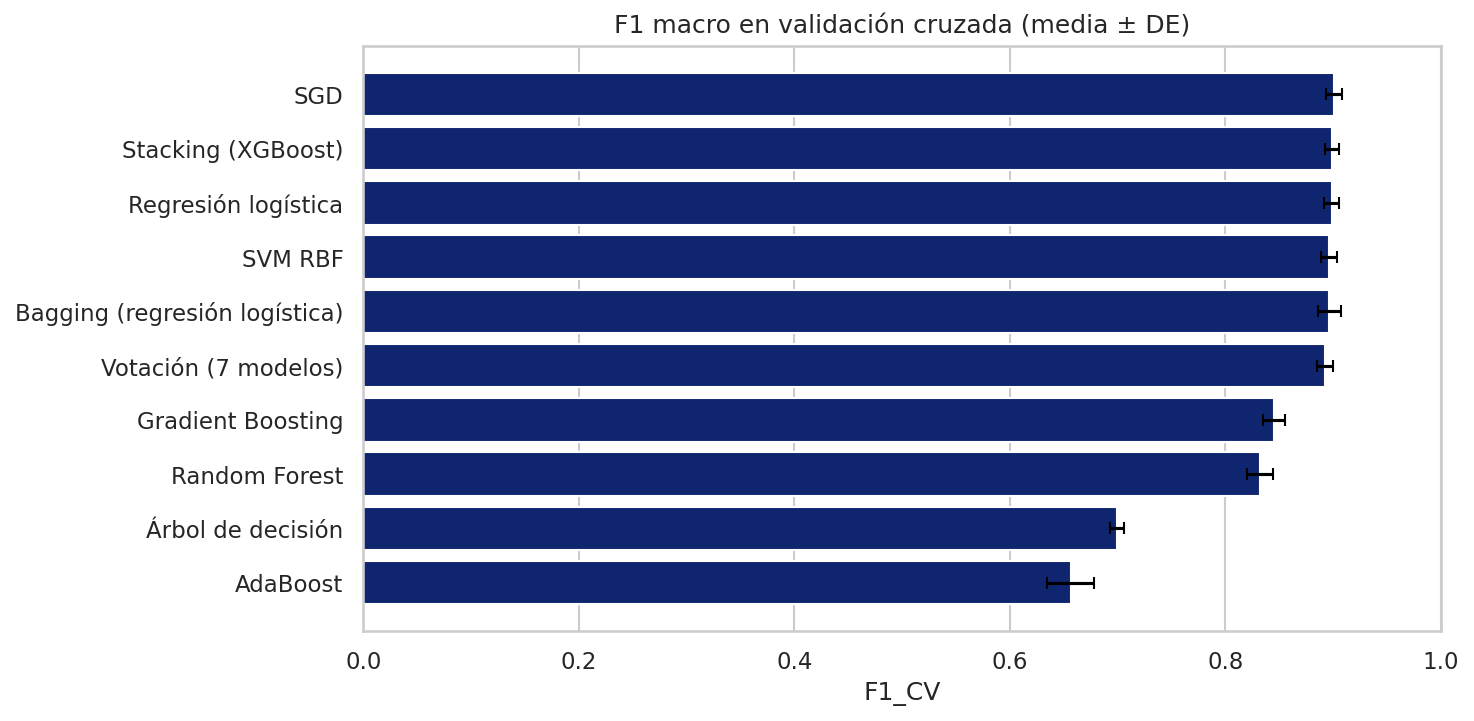

In [71]:
tabla("clasificacion","validacion")
mostrar("clasificacion","01_validacion")

### Evaluación en prueba
Se utiliza el conjunto reservado de 900 documentos.

,modelo,Accuracy,Precision,Recall,F1,segundos_prediccion
0,SGD,0.8989,0.9007,0.8989,0.8991,0.1252
1,Stacking (XGBoost),0.8933,0.8963,0.8933,0.8938,1.9351
2,Regresión logística,0.8956,0.8982,0.8956,0.8959,0.1202
3,SVM RBF,0.8911,0.8967,0.8911,0.8922,1.0772
4,Bagging (regresión logística),0.9000,0.9028,0.9000,0.9003,0.1611
5,Votación (7 modelos),0.8956,0.8993,0.8956,0.8964,1.9442
6,Gradient Boosting,0.8589,0.8588,0.8589,0.8584,0.1215
7,Random Forest,0.8389,0.8455,0.8389,0.8386,0.1751
8,Árbol de decisión,0.6944,0.7065,0.6944,0.6955,0.1162
9,AdaBoost,0.6289,0.8139,0.6289,0.6568,0.2999


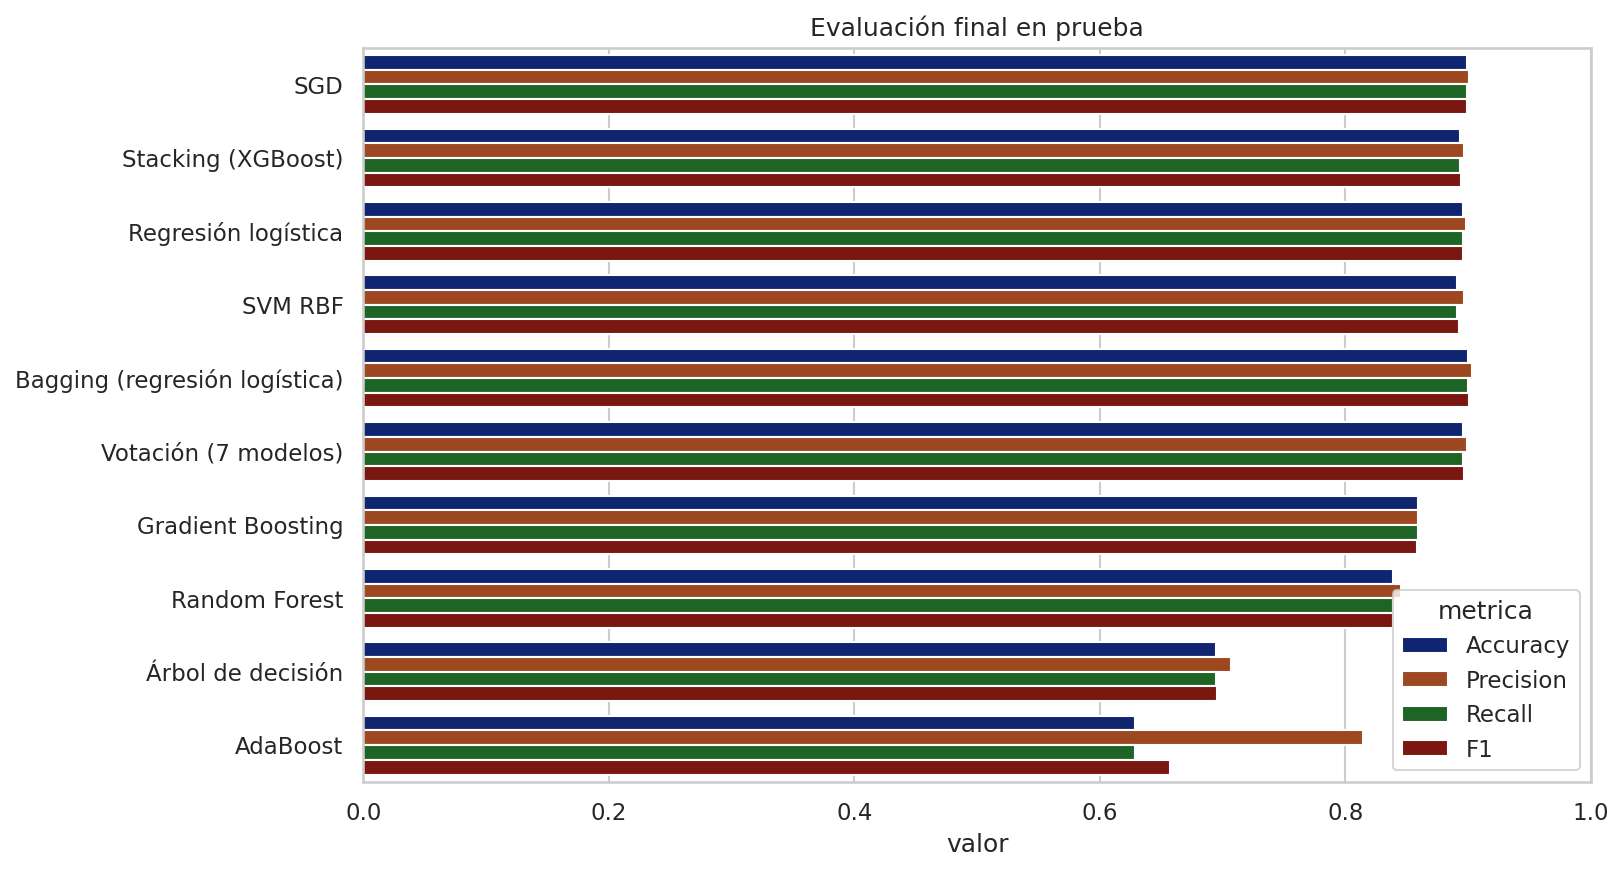

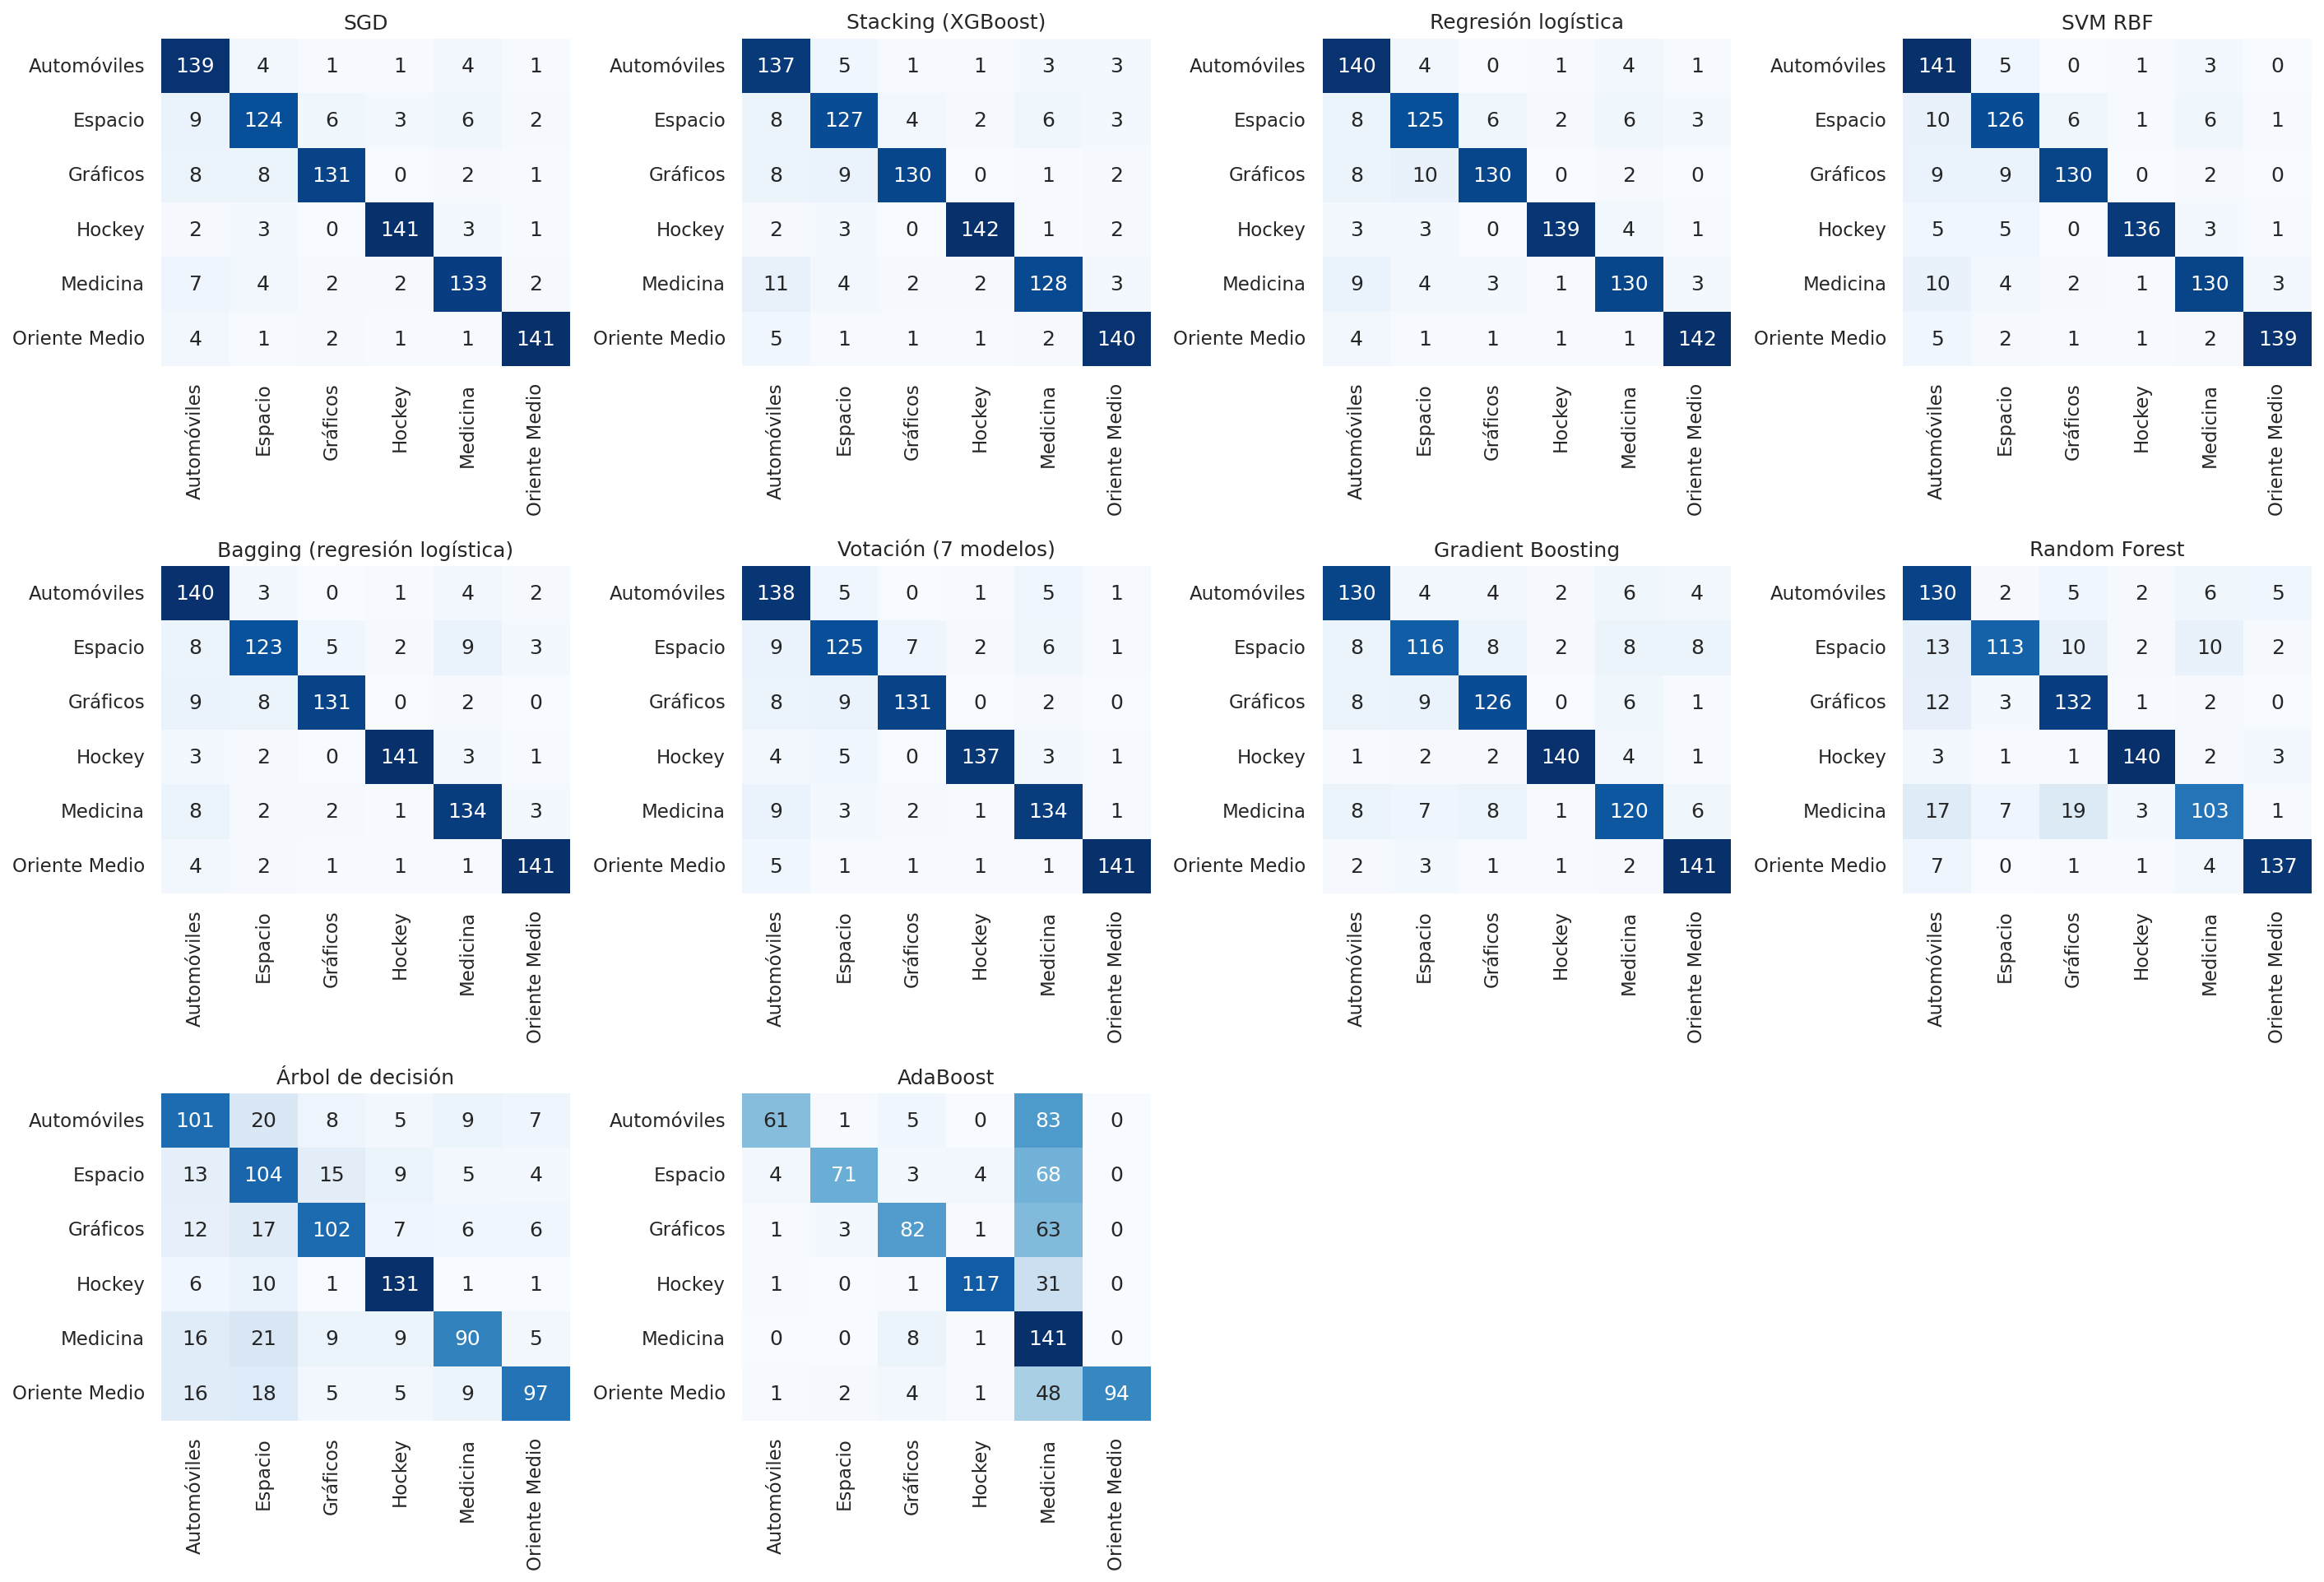

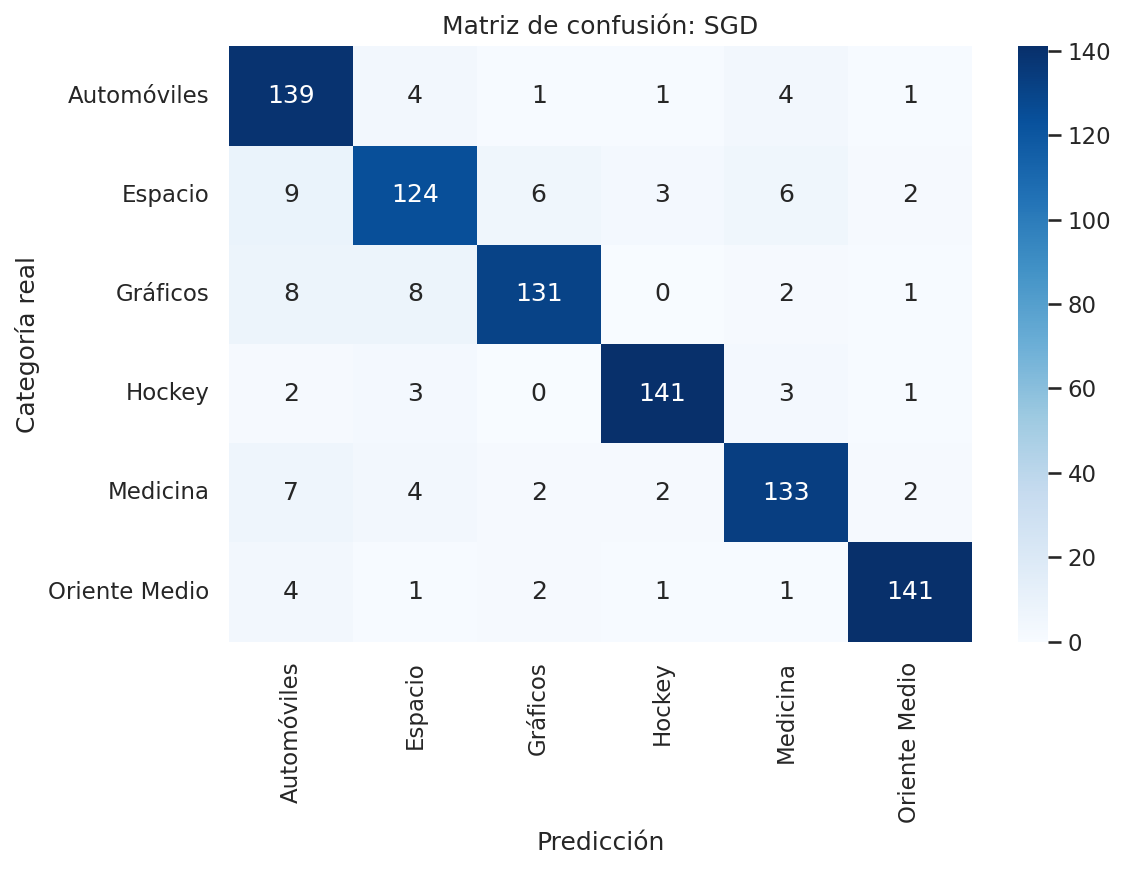

In [72]:
tabla("clasificacion","metricas_prueba")
mostrar("clasificacion","02_metricas","03_confusiones","04_mejor_confusion")

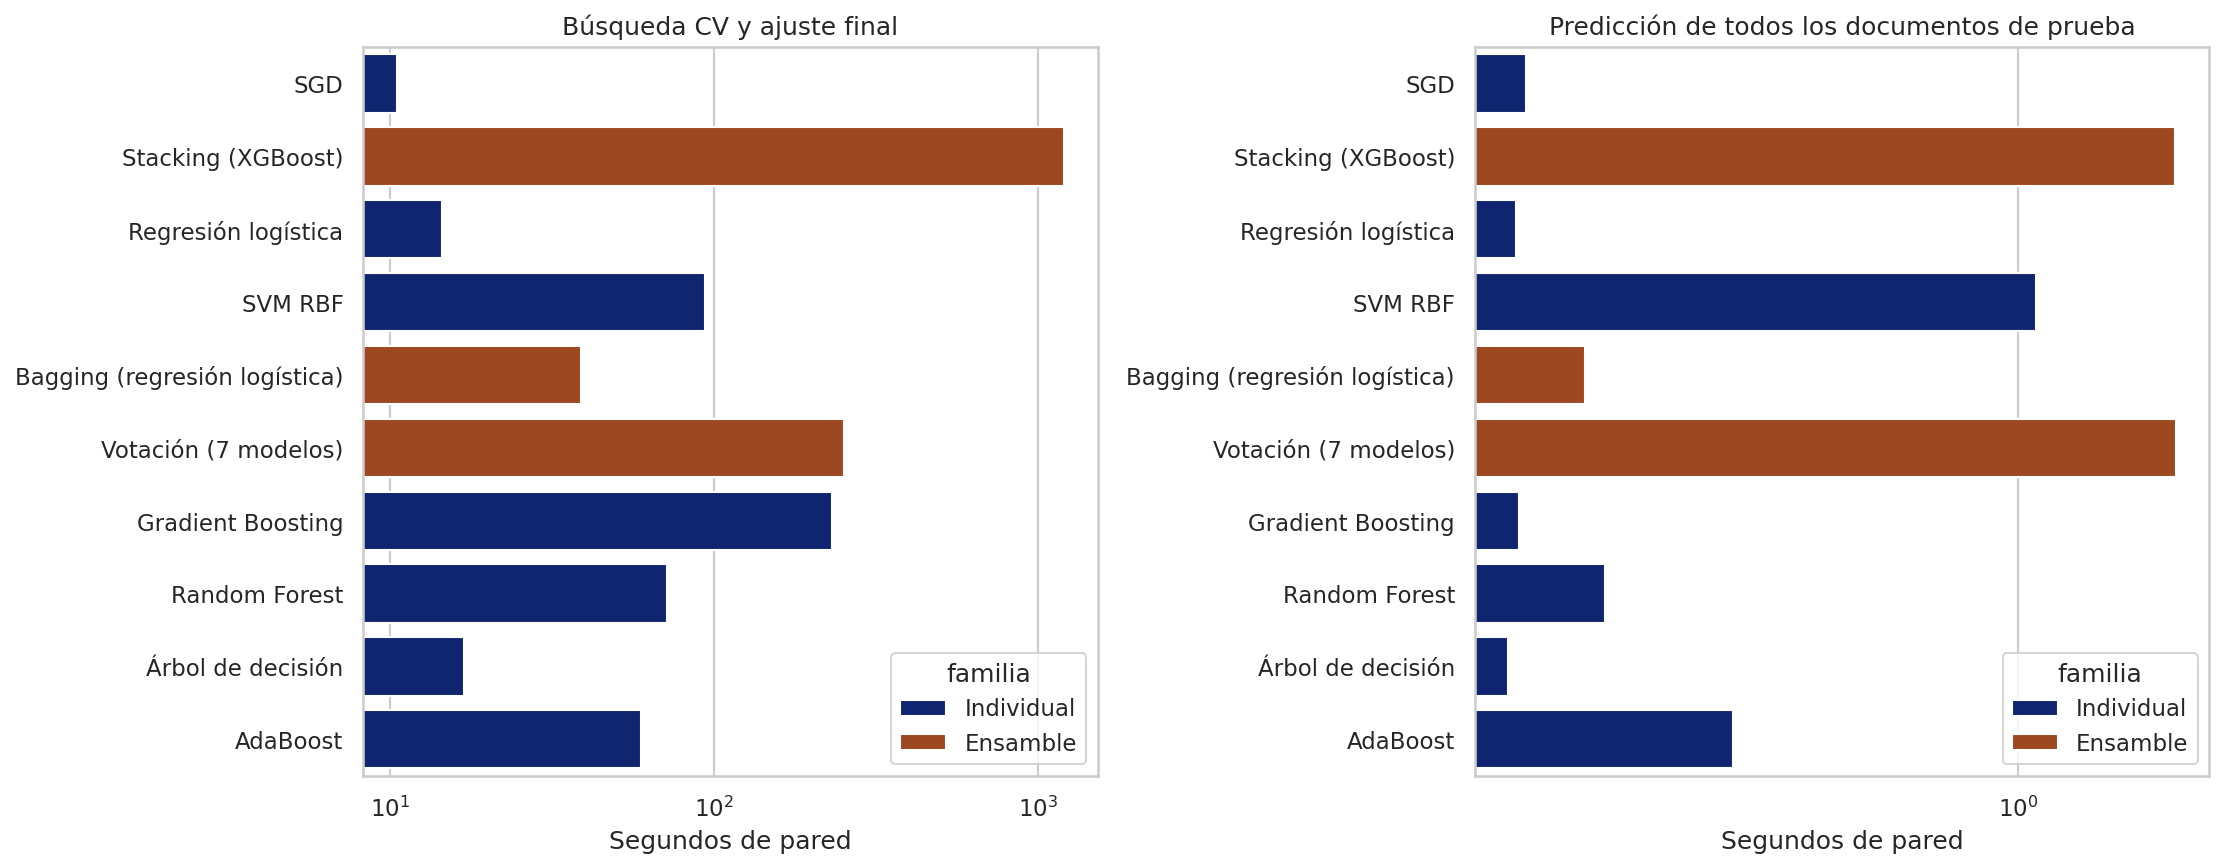

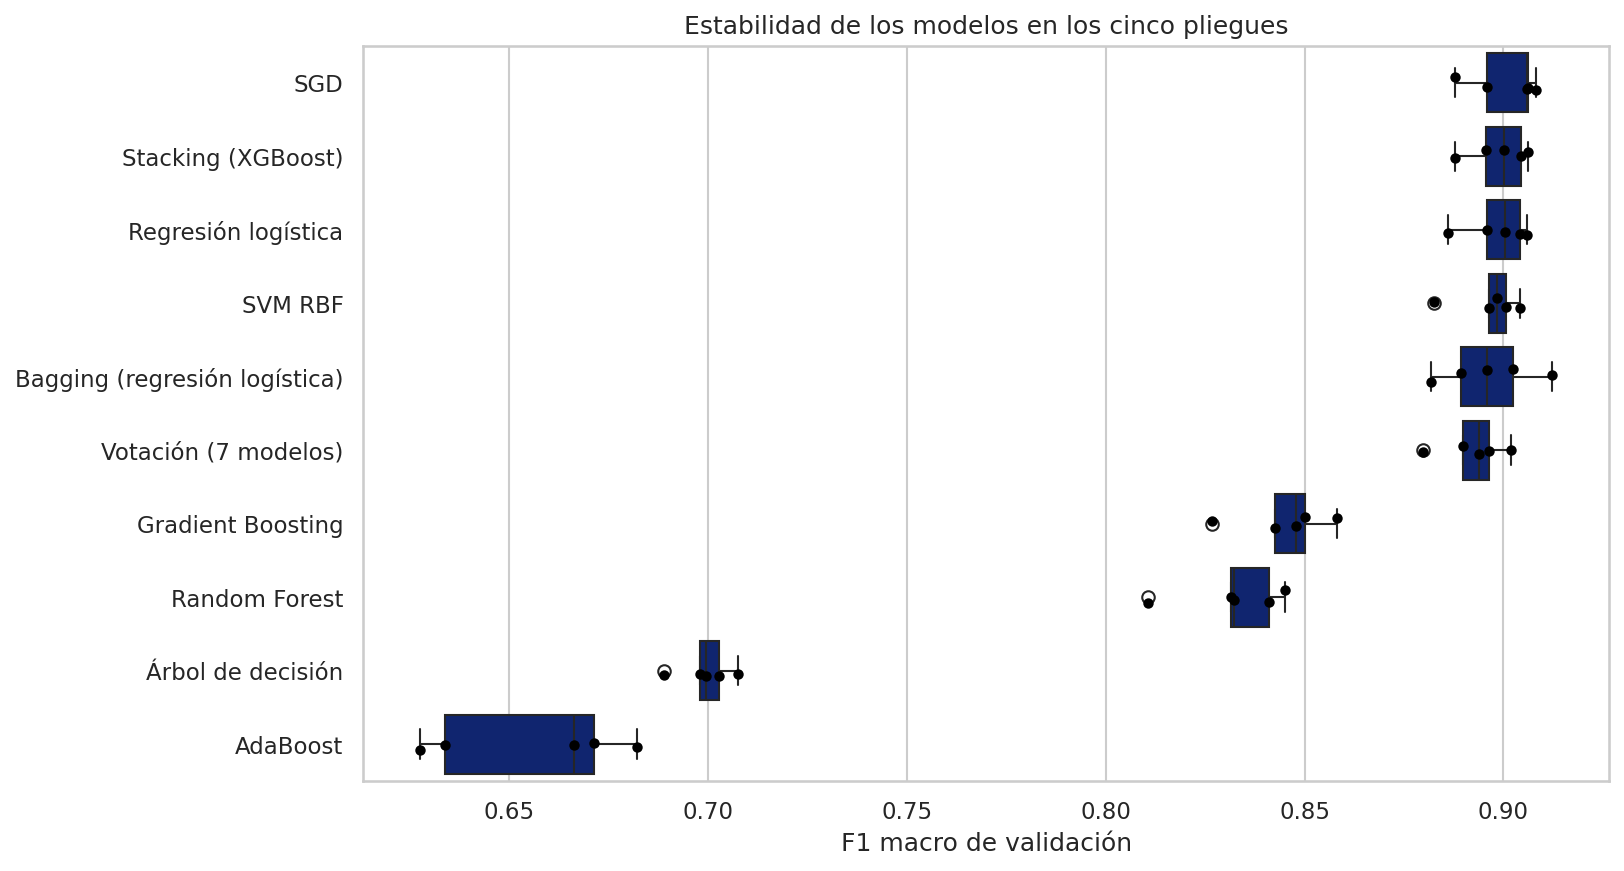

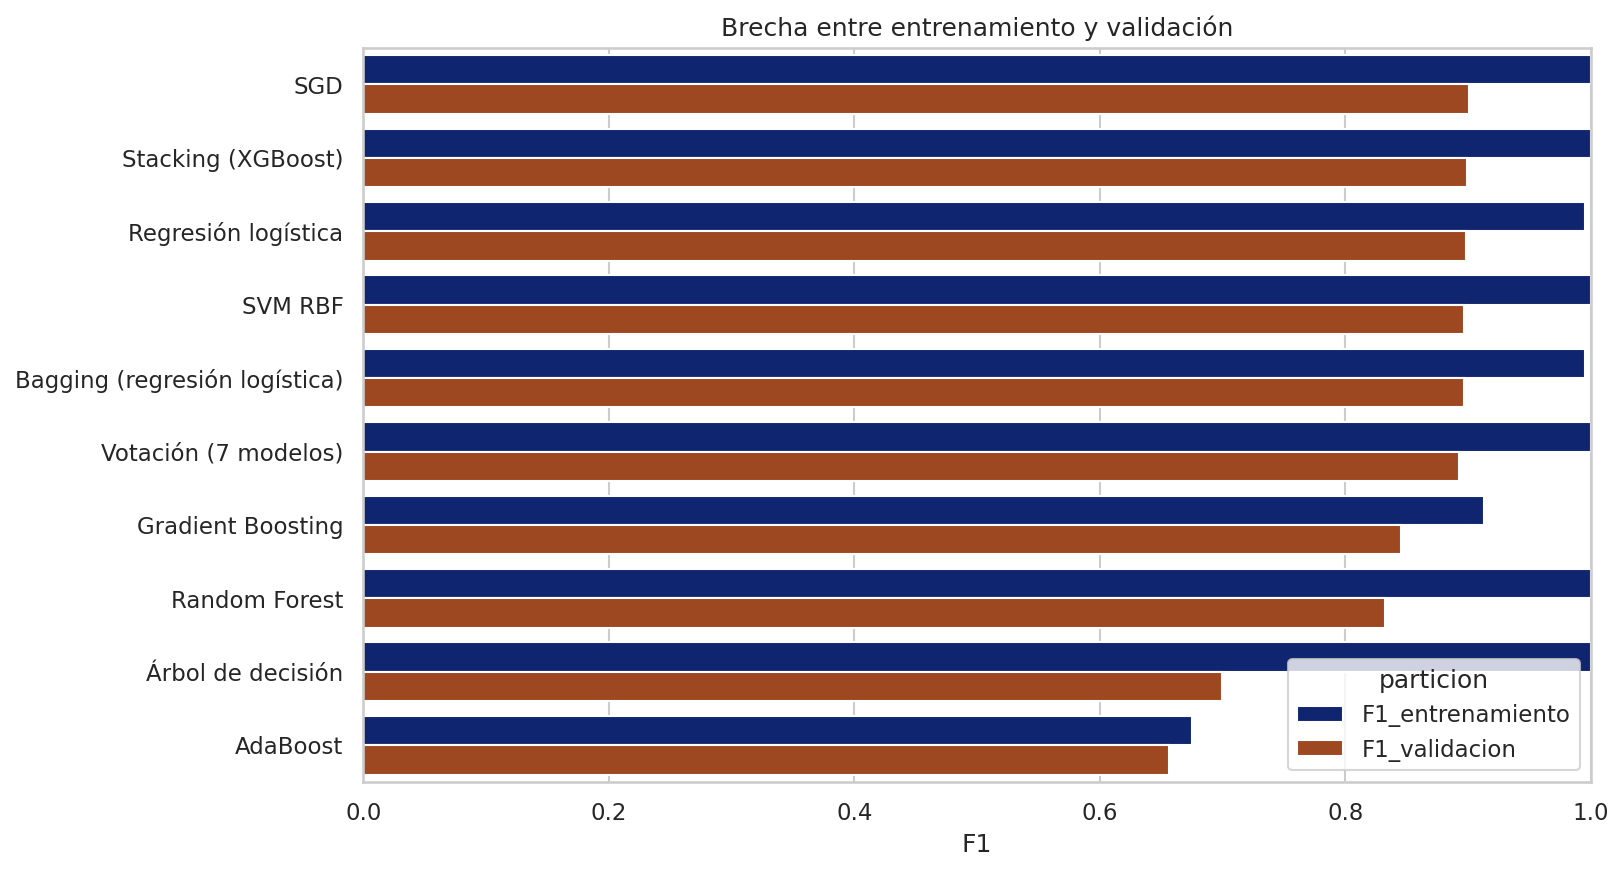

In [73]:
mostrar("clasificacion","06_tiempos","07_estabilidad_cv","08_brecha_cv")

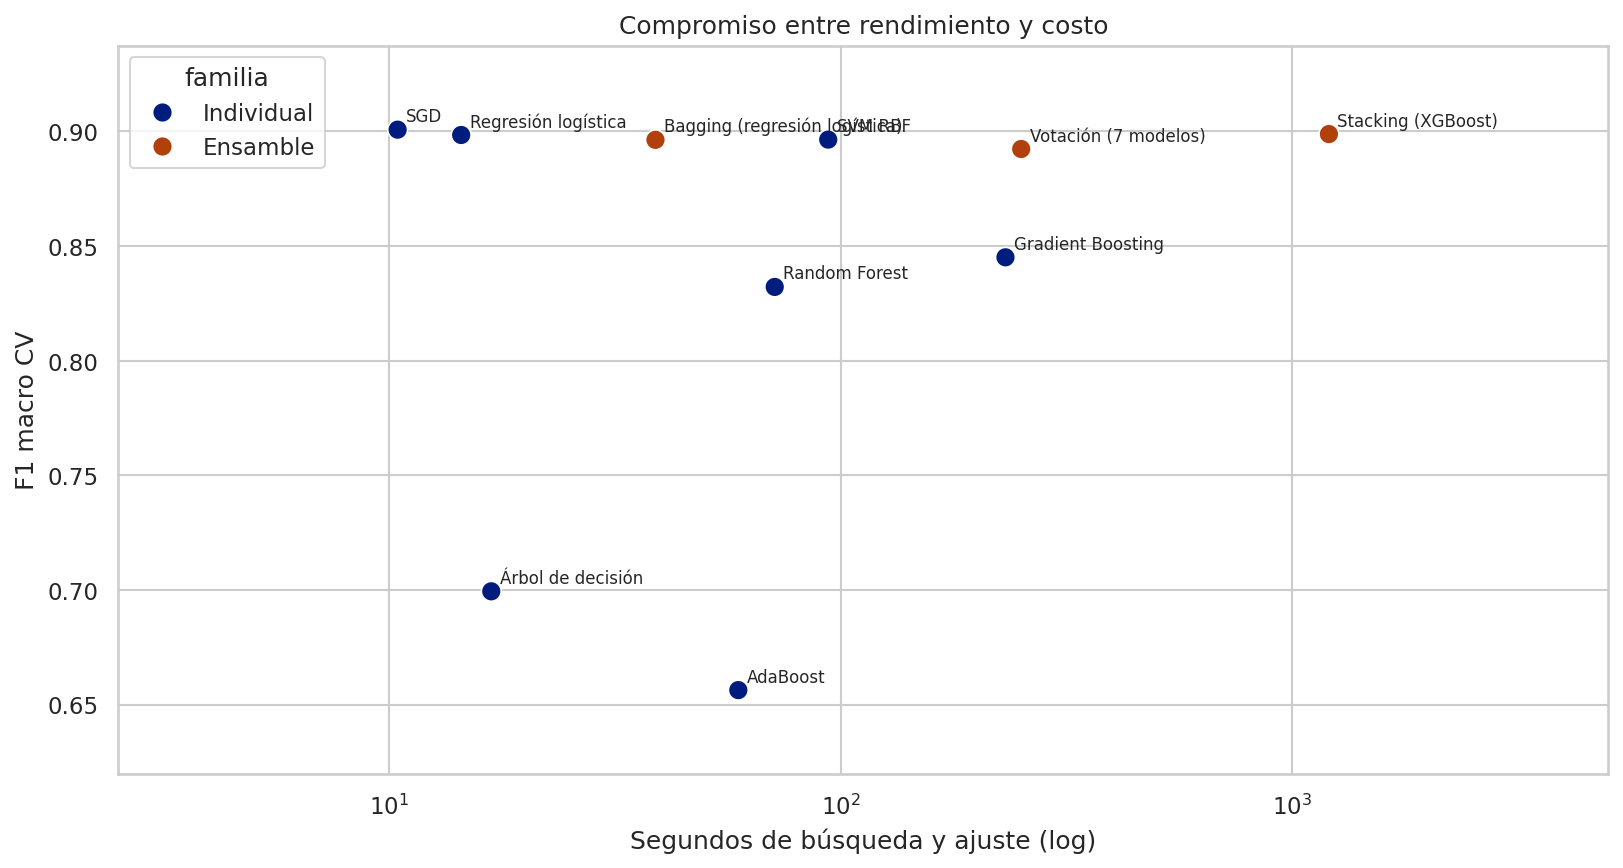

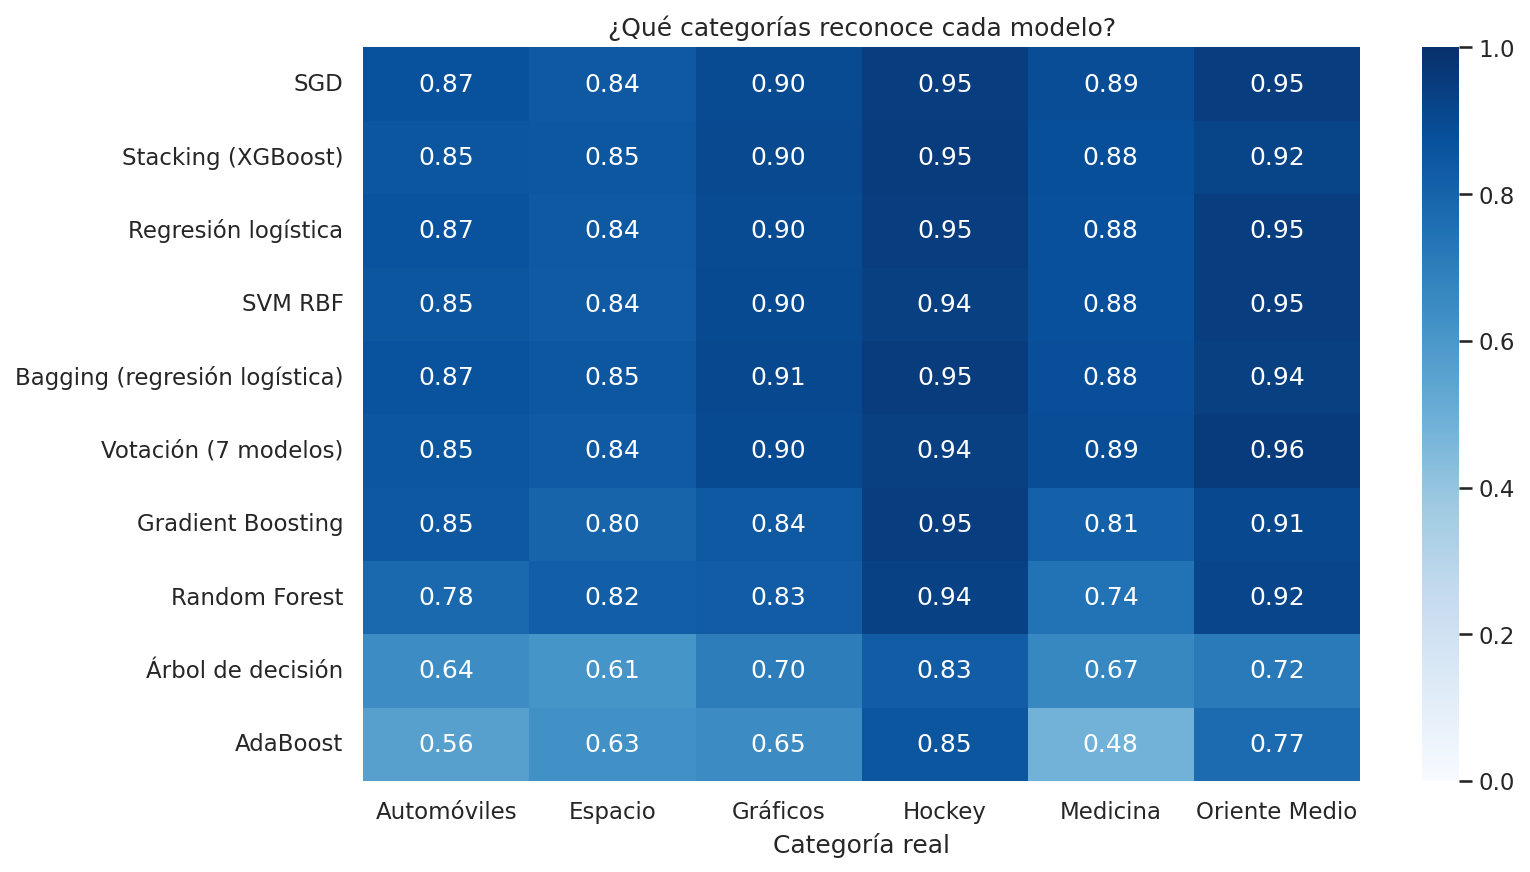

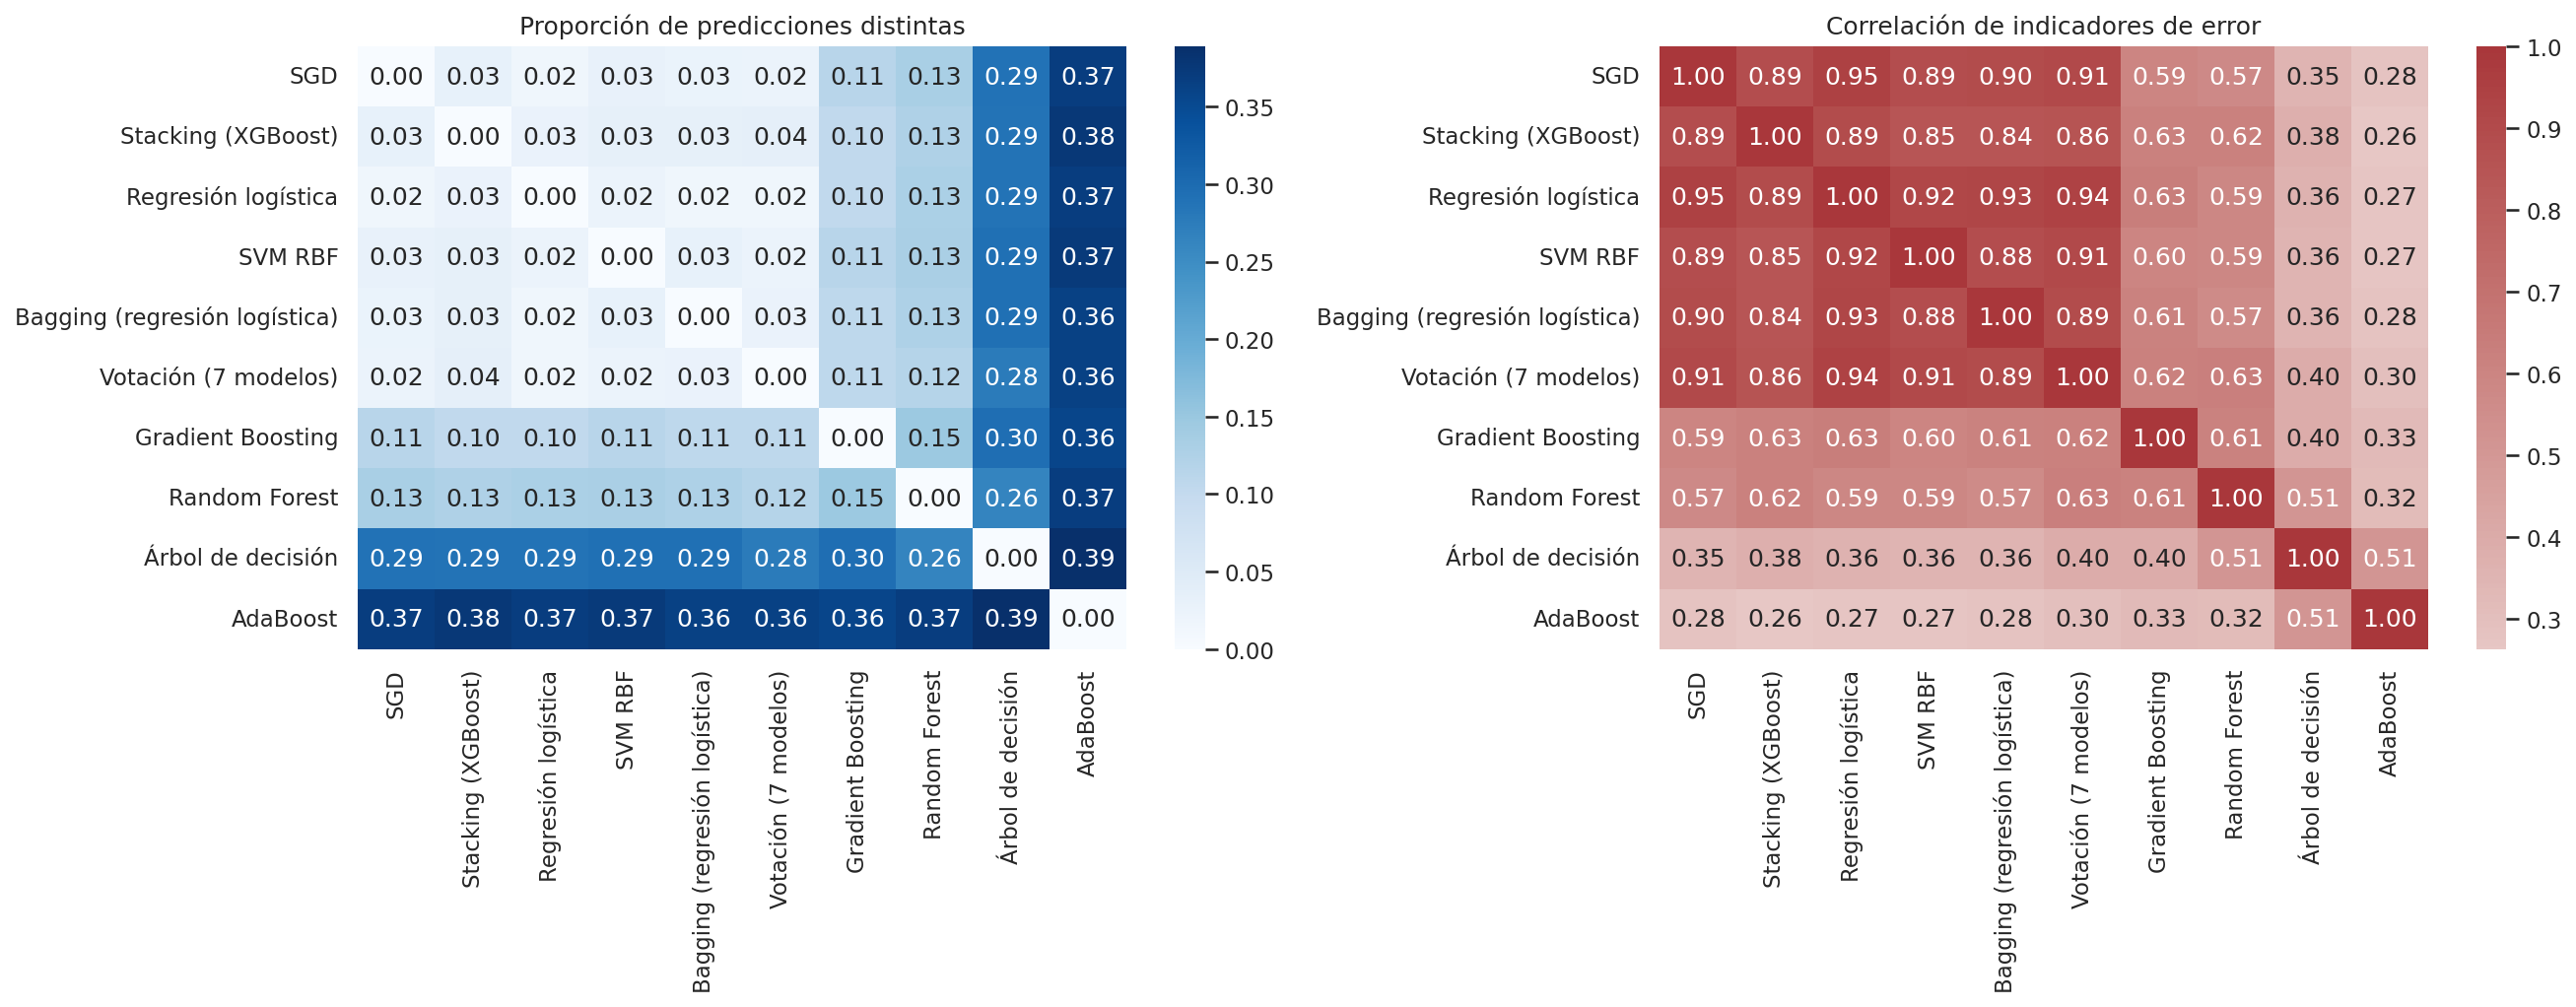

In [74]:
mostrar("clasificacion","09_costo_rendimiento","10_f1_por_clase","11_diversidad")

### Comparación estadística
Bootstrap estratificado y pareado de los tres finalistas por validación; ajuste de Holm.

,modelo_A,modelo_B,delta_F1,IC_inferior,IC_superior,p,rechaza_H0,p_Holm
0,SGD,Stacking (XGBoost),0.0053,-0.0035,0.0148,0.2544,False,0.7631
1,SGD,Regresión logística,0.0032,-0.0033,0.0099,0.3578,False,0.7631
2,Stacking (XGBoost),Regresión logística,-0.0021,-0.0109,0.0068,0.6472,False,0.7631


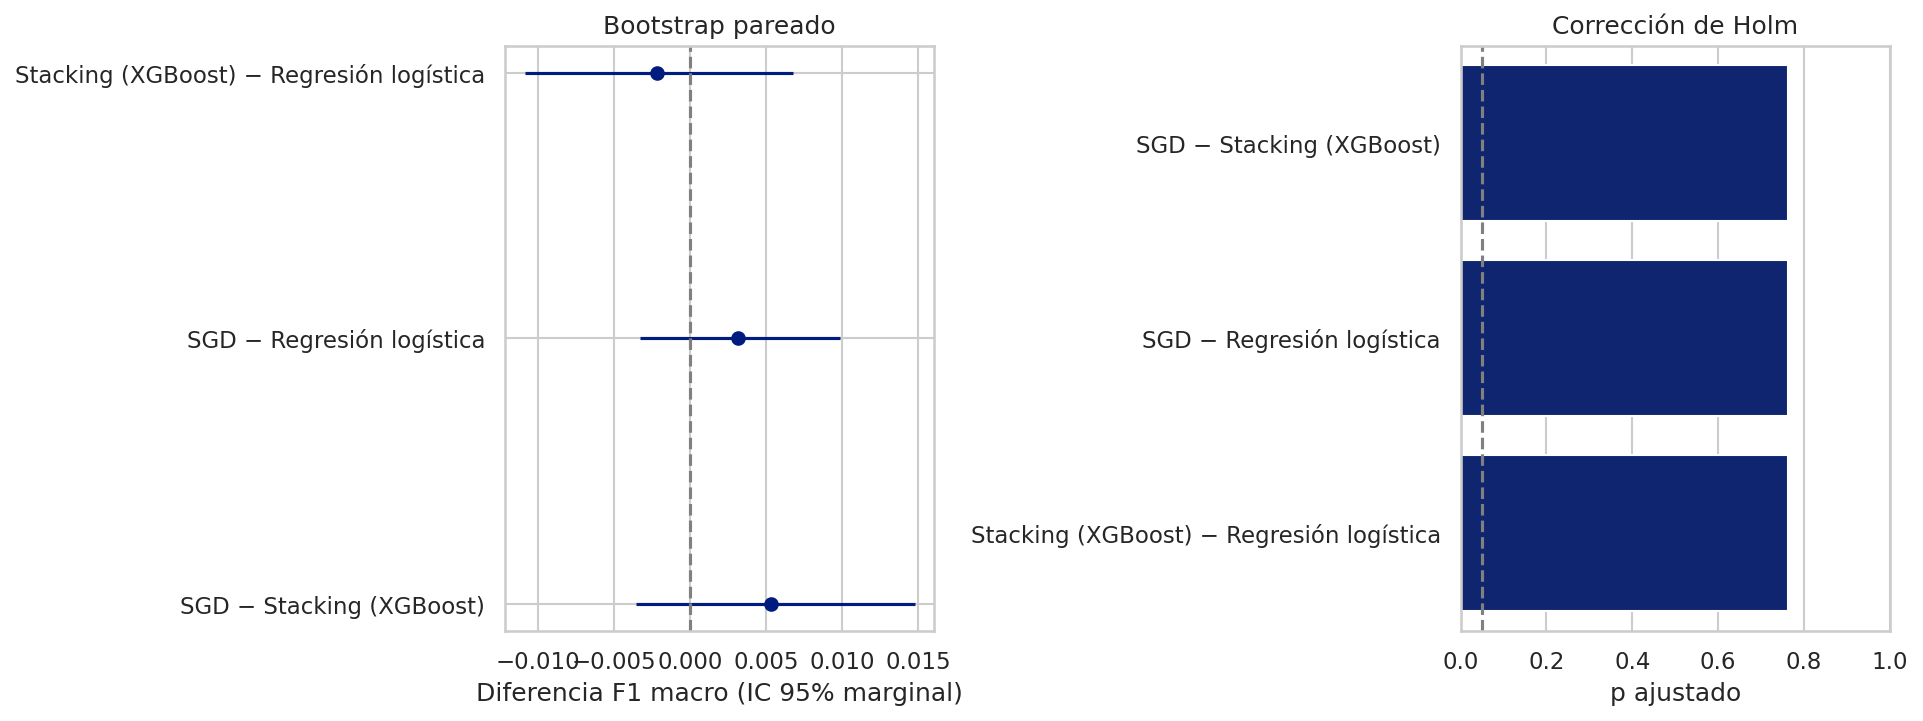

In [75]:
tabla("clasificacion","bootstrap_holm")
mostrar("clasificacion","05_bootstrap_holm")

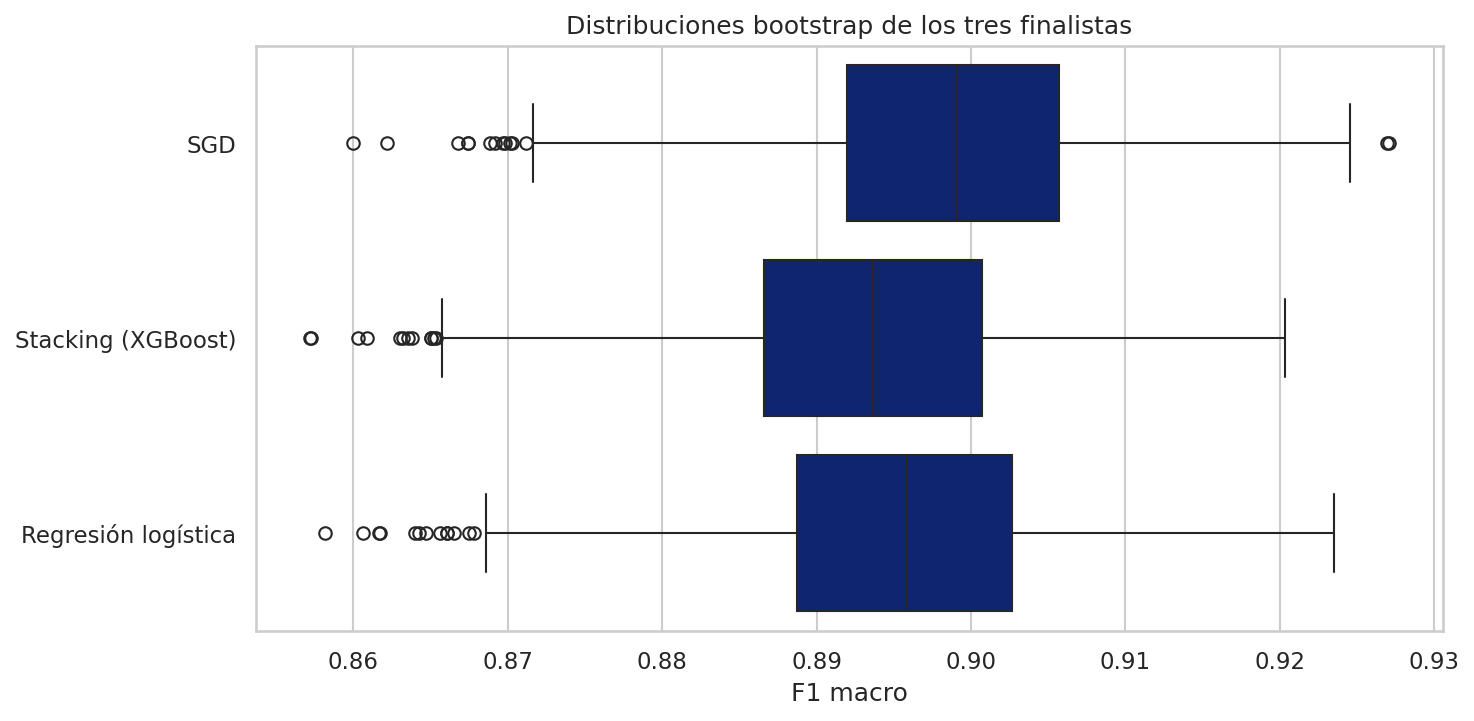

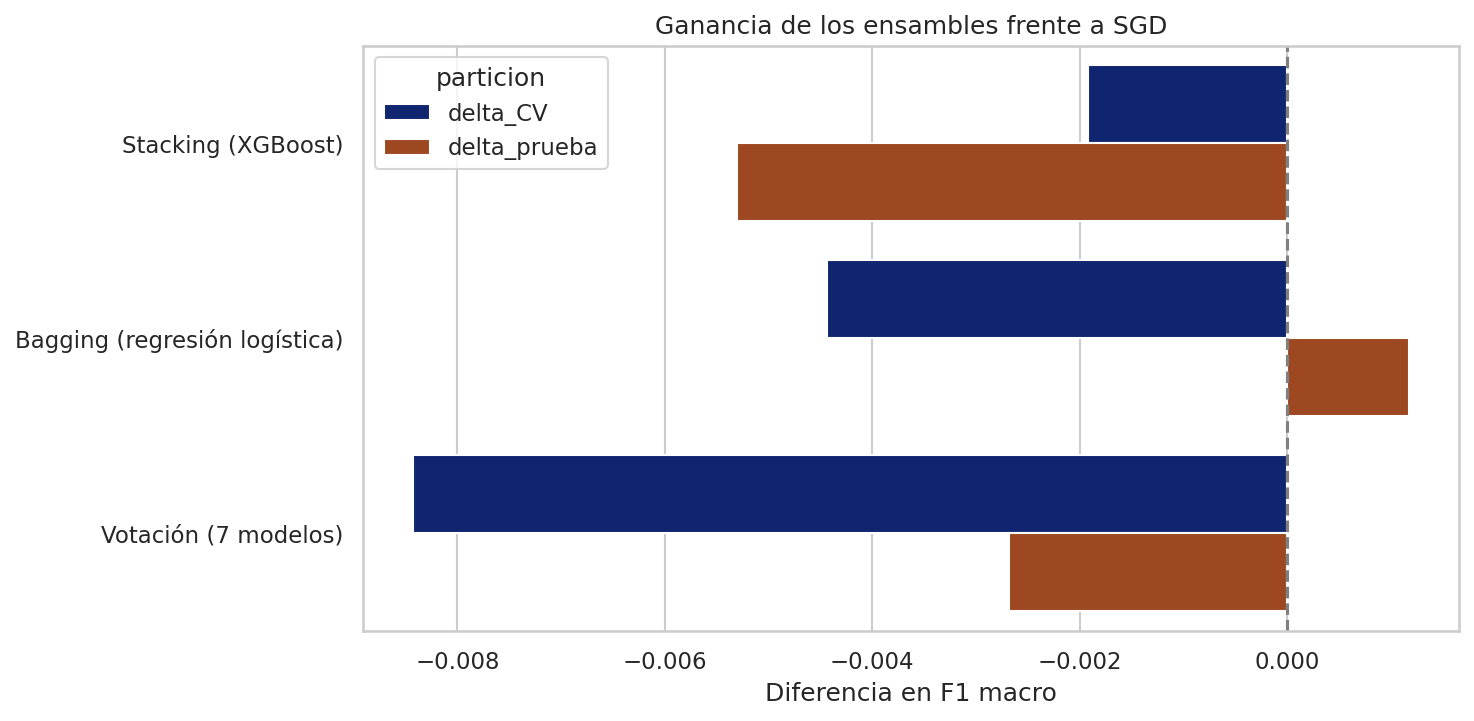

In [76]:
mostrar("clasificacion","12_bootstrap_distribuciones","13_mejora_ensambles")

### Extensión con grupos temáticos
Se repite el mismo protocolo con indicadores adicionales. La prueba ya observada hace que esta comparación sea exploratoria.

In [77]:
"""análisis anterior: ablación apareada de características temáticas."""
from time import perf_counter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import confusion_matrix

In [78]:
def ejecutar_hibrido(datos):
    base, etapa = "clasificacion", "hibrido"
    train, test = entrenamiento(datos), datos.loc[datos.particion.eq("test")]
    # Comprobar que la comparación conserva exactamente documentos y orden.
    anteriores = leer(base, "predicciones").set_index("huella")
    assert anteriores.index.is_unique and set(anteriores.index) == set(test.huella)
    anteriores = anteriores.loc[test.huella]
    yt = test.categoria.to_numpy()
    assert np.array_equal(anteriores.real.to_numpy(), yt)
    vb = leer(base, "validacion")
    mb = leer(base, "metricas_prueba")
    pb = leer(base, "pliegues_cv")
    estimadores, vh, ph, detalles = ajustar_modelos(train.texto, train.categoria, con_grupos=True)
    assert set(vb.modelo) == set(vh.modelo)
    # Selección híbrida congelada antes de evaluar predicciones híbridas.
    guardar(vh, etapa, "validacion_hibrida")
    guardar(ph, etapa, "pliegues_hibridos")
    guardar(detalles, etapa, "busqueda_cv")
    pred, mh = evaluar_modelos(estimadores, vh, test)
    guardar(mh, etapa, "metricas_hibridas")
    guardar(pd.DataFrame({"huella": test.huella.to_numpy(), "real": yt, **pred}), etapa, "predicciones_hibridas")
    MODELOS_AJUSTADOS[etapa] = estimadores[vh.modelo.iloc[0]]
    def unir(b, h):
        return pd.concat([b.assign(representacion="Léxica"), h.assign(representacion="Léxica + grupos")], ignore_index=True)
    val, met, folds = unir(vb,vh), unir(mb,mh), unir(pb,ph)
    ranking = val.merge(met, on=["modelo","representacion"]).sort_values("F1_CV", ascending=False).reset_index(drop=True)
    guardar(ranking, etapa, "ranking_global")
    guardar(folds, etapa, "pliegues_comparados")
    pares = ranking.pivot(index="modelo",columns="representacion",values=["F1_CV","F1","segundos"])
    comparacion = pd.DataFrame({
        "modelo": pares.index,
        "F1_CV_base": pares["F1_CV"]["Léxica"].to_numpy(),
        "F1_CV_hibrido": pares["F1_CV"]["Léxica + grupos"].to_numpy(),
        "F1_prueba_base": pares["F1"]["Léxica"].to_numpy(),
        "F1_prueba_hibrido": pares["F1"]["Léxica + grupos"].to_numpy(),
        "segundos_base": pares["segundos"]["Léxica"].to_numpy(),
        "segundos_hibrido": pares["segundos"]["Léxica + grupos"].to_numpy(),
    })
    comparacion["delta_CV"] = comparacion.F1_CV_hibrido-comparacion.F1_CV_base
    comparacion["delta_prueba"] = comparacion.F1_prueba_hibrido-comparacion.F1_prueba_base
    comparacion["factor_tiempo"] = comparacion.segundos_hibrido/comparacion.segundos_base
    comparacion = comparacion.sort_values("delta_CV", ascending=False)
    guardar(comparacion, etapa, "comparacion")
    # Diez contrastes predefinidos: cada algoritmo contra su propia referencia.
    # Mismas semillas y mismos índices estratificados para todas las parejas.
    filas = []
    for nombre in vh.modelo:
        tabla, _ = bootstrap(yt, {"Híbrido": pred[nombre], "Base": anteriores[nombre].to_numpy()})
        filas.append(tabla.assign(modelo=nombre).drop(columns=["modelo_A","modelo_B","p_Holm","rechaza_H0"]))
    contrastes = pd.concat(filas, ignore_index=True)
    contrastes["rechaza_H0"], contrastes["p_Holm"], _, _ = multipletests(contrastes.p, alpha=.05, method="holm")
    contrastes = contrastes.sort_values("delta_F1", ascending=False)
    guardar(contrastes, etapa, "bootstrap_holm")
    # Ranking global y sus tres finalistas (familia inferencial separada, exploratoria).
    def etiqueta(fila):
        return fila.modelo + (" + grupos" if fila.representacion != "Léxica" else "")
    top = ranking.head(3)
    finalistas = {etiqueta(f): (pred[f.modelo] if f.representacion != "Léxica"
                              else anteriores[f.modelo].to_numpy()) for f in top.itertuples()}
    global_holm, replicas = bootstrap(yt, finalistas)
    guardar(global_holm, etapa, "bootstrap_finalistas")
    guardar(replicas, etapa, "replicas_finalistas")
    json_guardar({"modelo": ranking.iloc[0].modelo, "representacion": ranking.iloc[0].representacion,
                  "top3": list(finalistas), "evaluacion": "exploratoria; prueba observada antes de análisis anterior"},
                 etapa, "seleccion_global")
    orden = vb.modelo.tolist()
    fig, axs = plt.subplots(1,2,figsize=(15,6))
    for ax, tabla, metrica, titulo in [(axs[0],val,"F1_CV","Validación cruzada"),(axs[1],met,"F1","Prueba histórica")]:
        sns.barplot(data=tabla,y="modelo",x=metrica,hue="representacion",order=orden,ax=ax)
        ax.set(title=titulo,xlabel="F1 macro",ylabel="",xlim=(0,1))
    figura(etapa,"01_comparacion_pareada",fig)
    fig, ax = plt.subplots(figsize=(11,6))
    sns.barplot(data=comparacion.melt("modelo",["delta_CV","delta_prueba"],var_name="particion",value_name="delta"),
                y="modelo",x="delta",hue="particion",ax=ax)
    ax.axvline(0,ls="--",color="gray")
    ax.set(title="Ganancia atribuible a las características temáticas",xlabel="Diferencia F1 (híbrido − base)",ylabel="")
    figura(etapa,"02_ganancia",fig)
    dif = folds.pivot(index=["modelo","pliegue"],columns="representacion",values="F1_validacion").reset_index()
    dif["delta"] = dif["Léxica + grupos"]-dif["Léxica"]
    guardar(dif,etapa,"ganancia_pliegues")
    fig,ax=plt.subplots(figsize=(10,6))
    sns.boxplot(data=dif,y="modelo",x="delta",order=orden,ax=ax)
    sns.stripplot(data=dif,y="modelo",x="delta",order=orden,color="black",ax=ax)
    ax.axvline(0,ls="--",color="gray")
    ax.set(title="Estabilidad de la ganancia en los mismos cinco pliegues",xlabel="Diferencia de F1",ylabel="")
    figura(etapa,"03_estabilidad_ganancia",fig)
    fig,axs=plt.subplots(1,2,figsize=(15,6))
    pos=np.arange(len(contrastes))
    axs[0].hlines(pos,contrastes.IC_inferior,contrastes.IC_superior)
    axs[0].scatter(contrastes.delta_F1,pos)
    axs[0].axvline(0,ls="--",color="gray")
    axs[0].set(yticks=pos,yticklabels=contrastes.modelo,title="Bootstrap pareado (IC marginal 95%)",xlabel="F1 híbrido − base")
    sns.barplot(data=contrastes,y="modelo",x="p_Holm",order=contrastes.modelo,ax=axs[1])
    axs[1].axvline(.05,ls="--",color="gray")
    axs[1].set(title="Holm: diez comparaciones",xlabel="p ajustado",ylabel="",xlim=(0,1))
    figura(etapa,"04_bootstrap_holm",fig)
    fig,axs=plt.subplots(1,2,figsize=(15,6))
    sns.barplot(data=val,y="modelo",x="segundos",hue="representacion",order=orden,ax=axs[0])
    axs[0].set(xscale="log",title="Costo de entrenamiento y búsqueda",xlabel="Segundos (log)",ylabel="")
    sns.scatterplot(data=comparacion,x="factor_tiempo",y="delta_CV",s=80,ax=axs[1])
    for fila in comparacion.itertuples():
        axs[1].annotate(fila.modelo,(fila.factor_tiempo,fila.delta_CV),xytext=(4,4),textcoords="offset points",fontsize=8)
    axs[1].axhline(0,ls="--",color="gray")
    axs[1].axvline(1,ls="--",color="gray")
    axs[1].set(xscale="log",title="¿Compensa el costo adicional?",xlabel="Tiempo híbrido / base",ylabel="Ganancia F1 CV")
    axs[1].margins(x=.3,y=.15)
    figura(etapa,"05_costo_ganancia",fig)
    fig,ax=plt.subplots(figsize=(10,9))
    plot=ranking.assign(candidato=[etiqueta(f) for f in ranking.itertuples()])
    sns.barplot(data=plot,y="candidato",x="F1_CV",hue="representacion",dodge=False,ax=ax)
    ax.set(title="Ranking global: veinte candidatos",xlabel="F1 macro CV",ylabel="",xlim=(0,1))
    figura(etapa,"06_ranking_global",fig)
    # Diagnóstico de los mejores híbrido y referencia, elegidos por CV.
    clases=sorted(np.unique(yt))
    fig,axs=plt.subplots(1,2,figsize=(13,5))
    for ax,nombre,prediccion in [(axs[0],vb.modelo.iloc[0],anteriores[vb.modelo.iloc[0]]),
                                (axs[1],vh.modelo.iloc[0]+" + grupos",pred[vh.modelo.iloc[0]])]:
        sns.heatmap(confusion_matrix(yt,prediccion,labels=clases),annot=True,fmt="d",cmap="Blues",cbar=False,
                    xticklabels=clases,yticklabels=clases,ax=ax)
        ax.set(title=nombre,xlabel="Predicción",ylabel="Real")
    figura(etapa,"07_confusiones_finalistas",fig)

In [79]:
ejecutar_etapa(ejecutar_hibrido)

Ajustando Regresión logística
Ajustando SGD
Ajustando Árbol de decisión
Ajustando Random Forest
Ajustando AdaBoost
Ajustando Gradient Boosting
Ajustando SVM RBF
Ajustando Bagging (regresión logística)
Ajustando Votación (7 modelos)
Ajustando Stacking (XGBoost)


,modelo,F1_CV_base,F1_CV_hibrido,F1_prueba_base,F1_prueba_hibrido,segundos_base,segundos_hibrido,delta_CV,delta_prueba,factor_tiempo
0,AdaBoost,0.6563,0.7842,0.6568,0.8014,59.4053,69.7012,0.1279,0.1446,1.1733
9,Árbol de decisión,0.6994,0.7777,0.6955,0.7760,16.8725,22.4396,0.0783,0.0806,1.3300
2,Gradient Boosting,0.8451,0.8509,0.8584,0.8758,231.7066,249.8247,0.0058,0.0174,1.0782
3,Random Forest,0.8322,0.8338,0.8386,0.8281,71.5099,77.2916,0.0016,-0.0105,1.0809
5,SGD,0.9008,0.8711,0.8991,0.8656,10.4711,20.3133,-0.0297,-0.0335,1.9399
7,Stacking (XGBoost),0.8988,0.8660,0.8938,0.8659,1204.0728,1330.6603,-0.0328,-0.0279,1.1051
4,Regresión logística,0.8984,0.8609,0.8959,0.8415,14.4736,28.9590,-0.0376,-0.0545,2.0008
6,SVM RBF,0.8964,0.8491,0.8922,0.8379,93.9203,73.5477,-0.0473,-0.0543,0.7831
8,Votación (7 modelos),0.8923,0.8341,0.8964,0.8256,251.0318,266.7361,-0.0582,-0.0708,1.0626
1,Bagging (regresión logística),0.8963,0.8240,0.9003,0.8123,38.9470,58.1523,-0.0724,-0.0879,1.4931


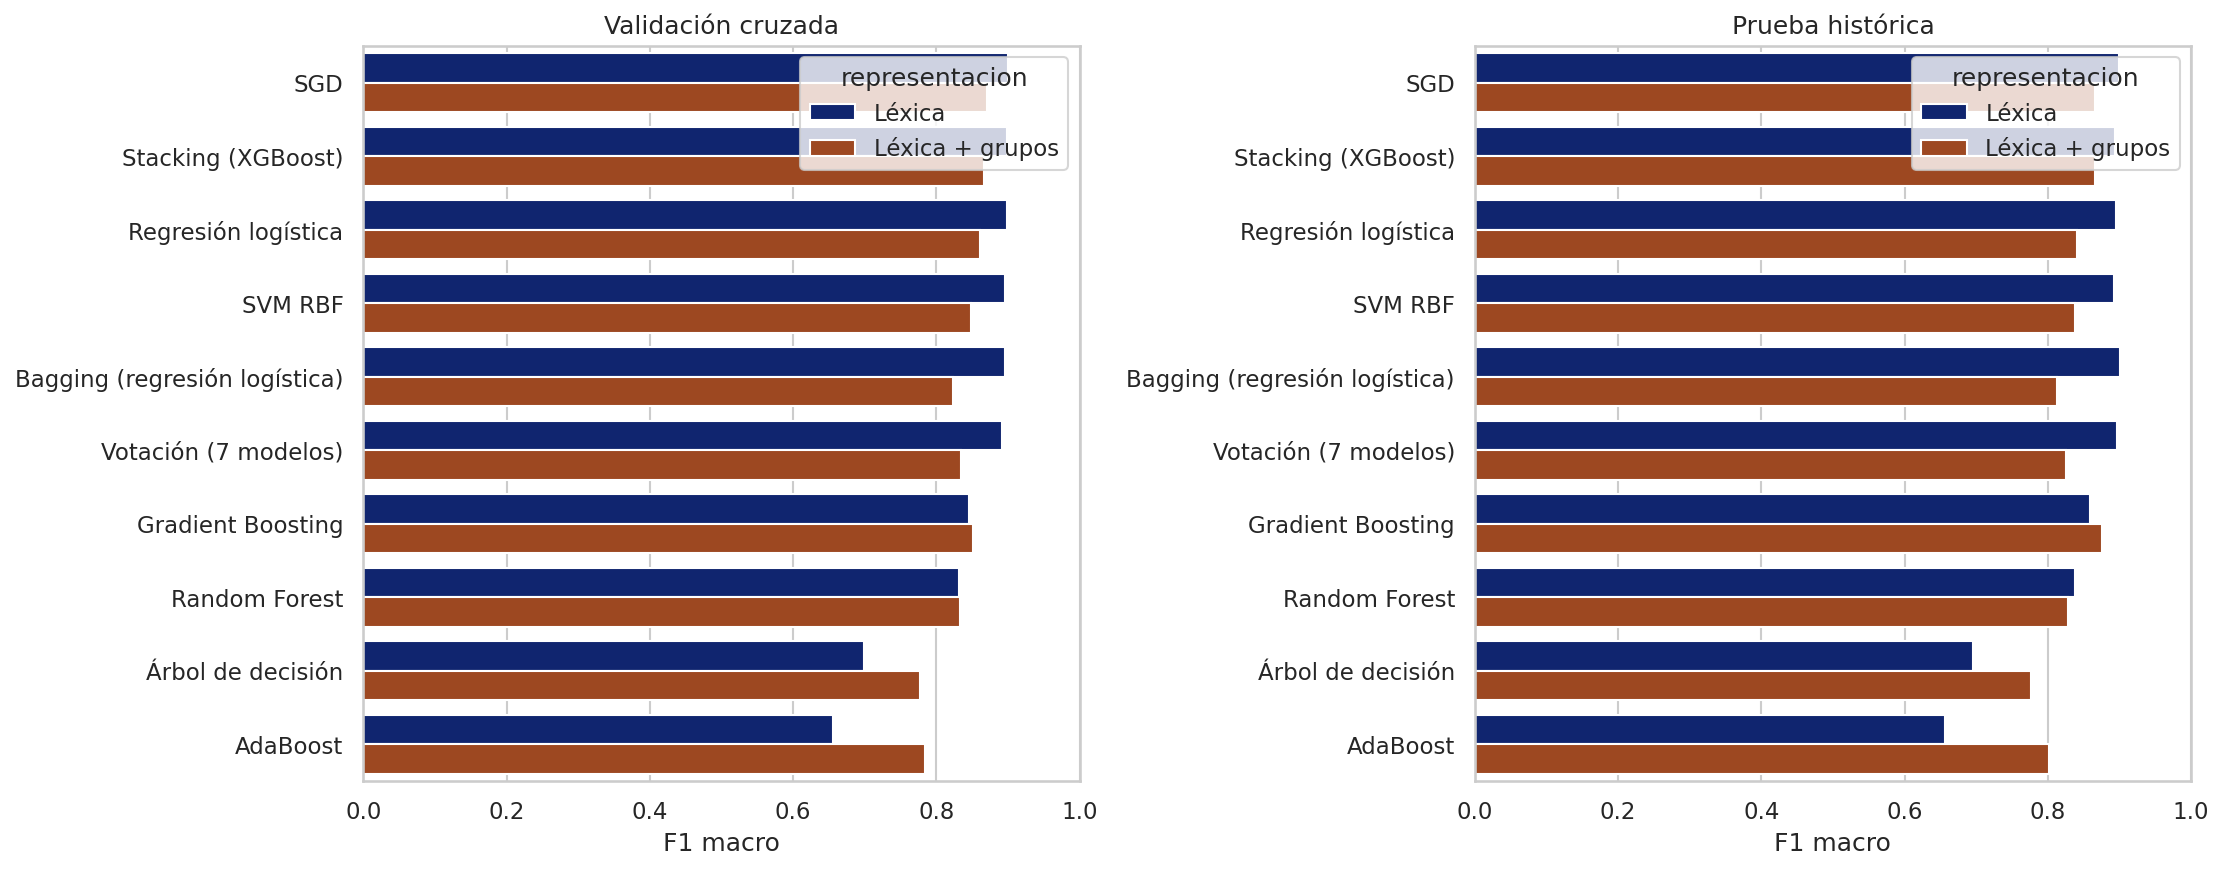

In [80]:
tabla("hibrido","comparacion")
mostrar("hibrido","01_comparacion_pareada")

,delta_F1,IC_inferior,IC_superior,p,modelo,rechaza_H0,p_Holm
8,0.1446,0.1148,0.1755,0.0005,AdaBoost,True,0.0050
9,0.0806,0.0494,0.1144,0.0005,Árbol de decisión,True,0.0050
3,0.0174,0.0032,0.0321,0.0155,Gradient Boosting,True,0.0310
6,-0.0105,-0.0306,0.0107,0.3333,Random Forest,False,0.3333
1,-0.0279,-0.0451,-0.0103,0.0040,Stacking (XGBoost),True,0.0120
0,-0.0335,-0.0508,-0.0168,0.0005,SGD,True,0.0050
4,-0.0543,-0.0740,-0.0354,0.0005,SVM RBF,True,0.0050
2,-0.0545,-0.0727,-0.0374,0.0005,Regresión logística,True,0.0050
5,-0.0708,-0.0921,-0.0507,0.0005,Votación (7 modelos),True,0.0050
7,-0.0879,-0.1098,-0.0682,0.0005,Bagging (regresión logística),True,0.0050


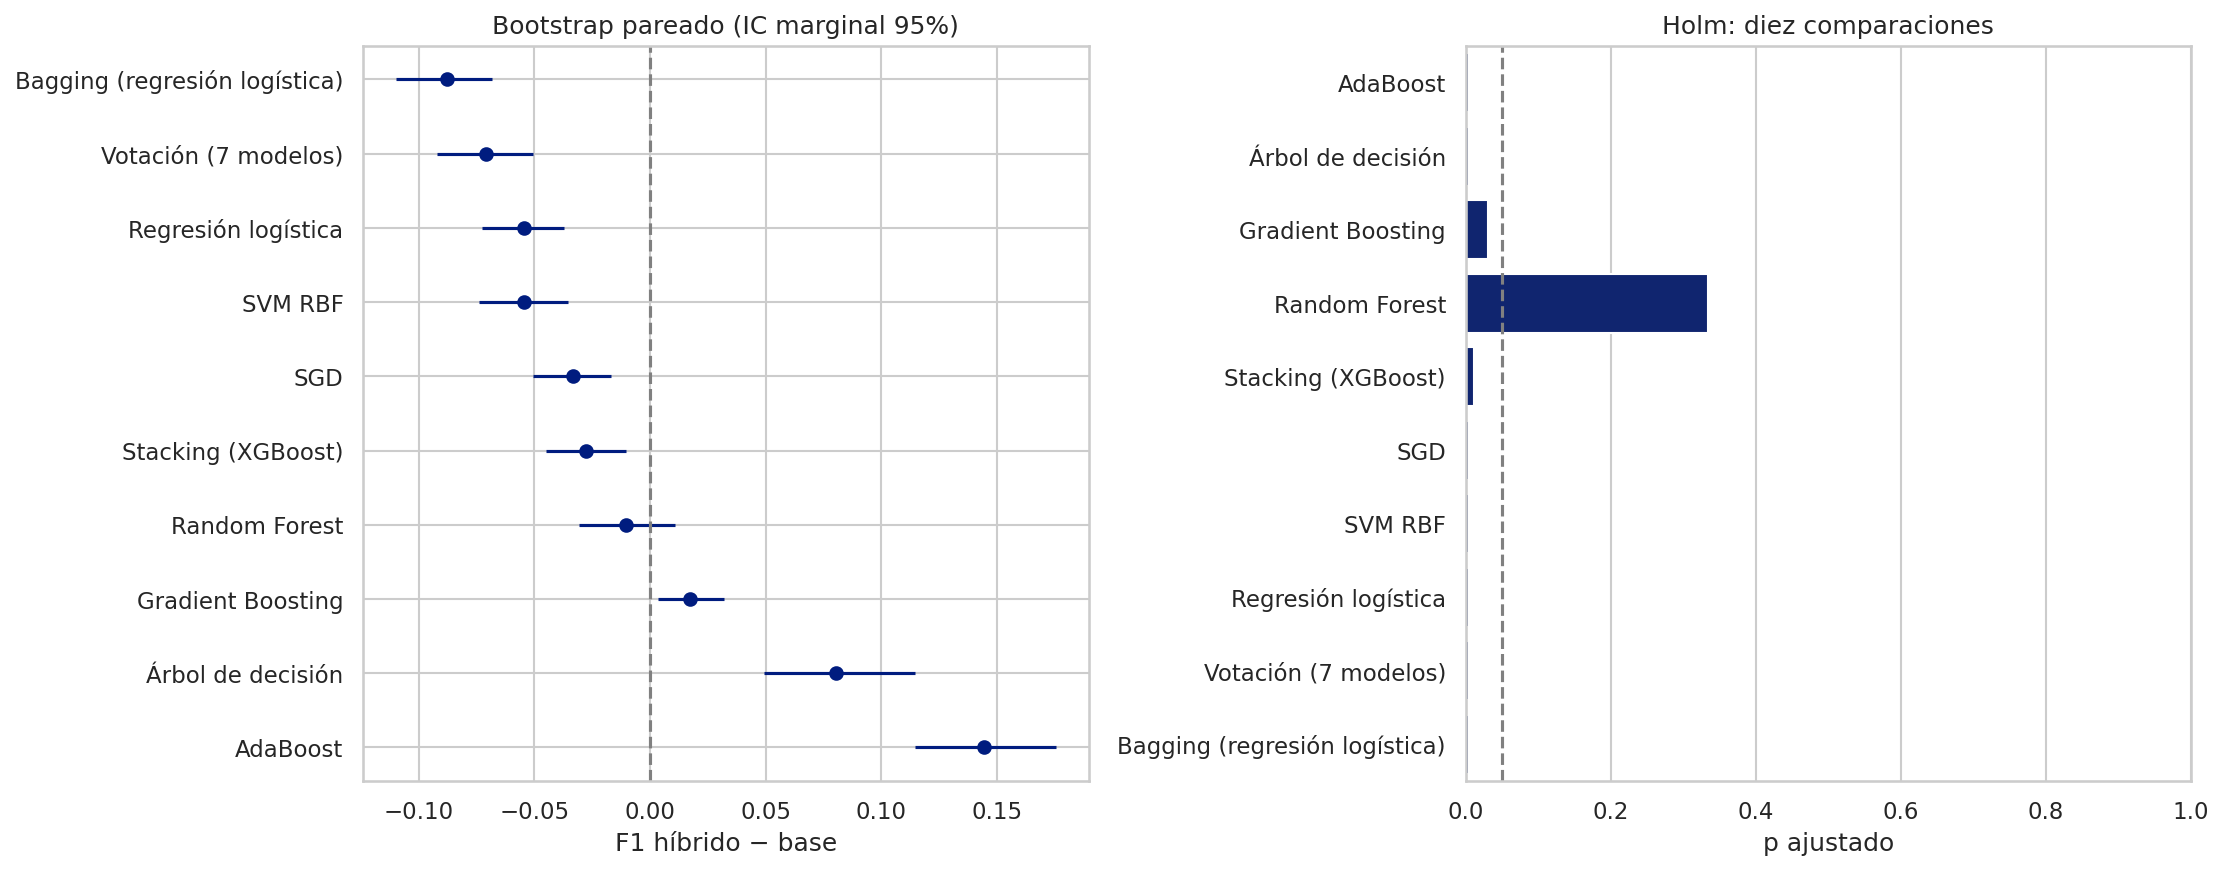

In [81]:
tabla("hibrido","bootstrap_holm")
mostrar("hibrido","04_bootstrap_holm")

,modelo,representacion,F1_CV,F1,segundos
0,SGD,Léxica,0.9008,0.8991,10.4711
1,Stacking (XGBoost),Léxica,0.8988,0.8938,1204.0728
2,Regresión logística,Léxica,0.8984,0.8959,14.4736
3,SVM RBF,Léxica,0.8964,0.8922,93.9203
4,Bagging (regresión logística),Léxica,0.8963,0.9003,38.9470
5,Votación (7 modelos),Léxica,0.8923,0.8964,251.0318
6,SGD,Léxica + grupos,0.8711,0.8656,20.3133
7,Stacking (XGBoost),Léxica + grupos,0.8660,0.8659,1330.6603
8,Regresión logística,Léxica + grupos,0.8609,0.8415,28.9590
9,Gradient Boosting,Léxica + grupos,0.8509,0.8758,249.8247


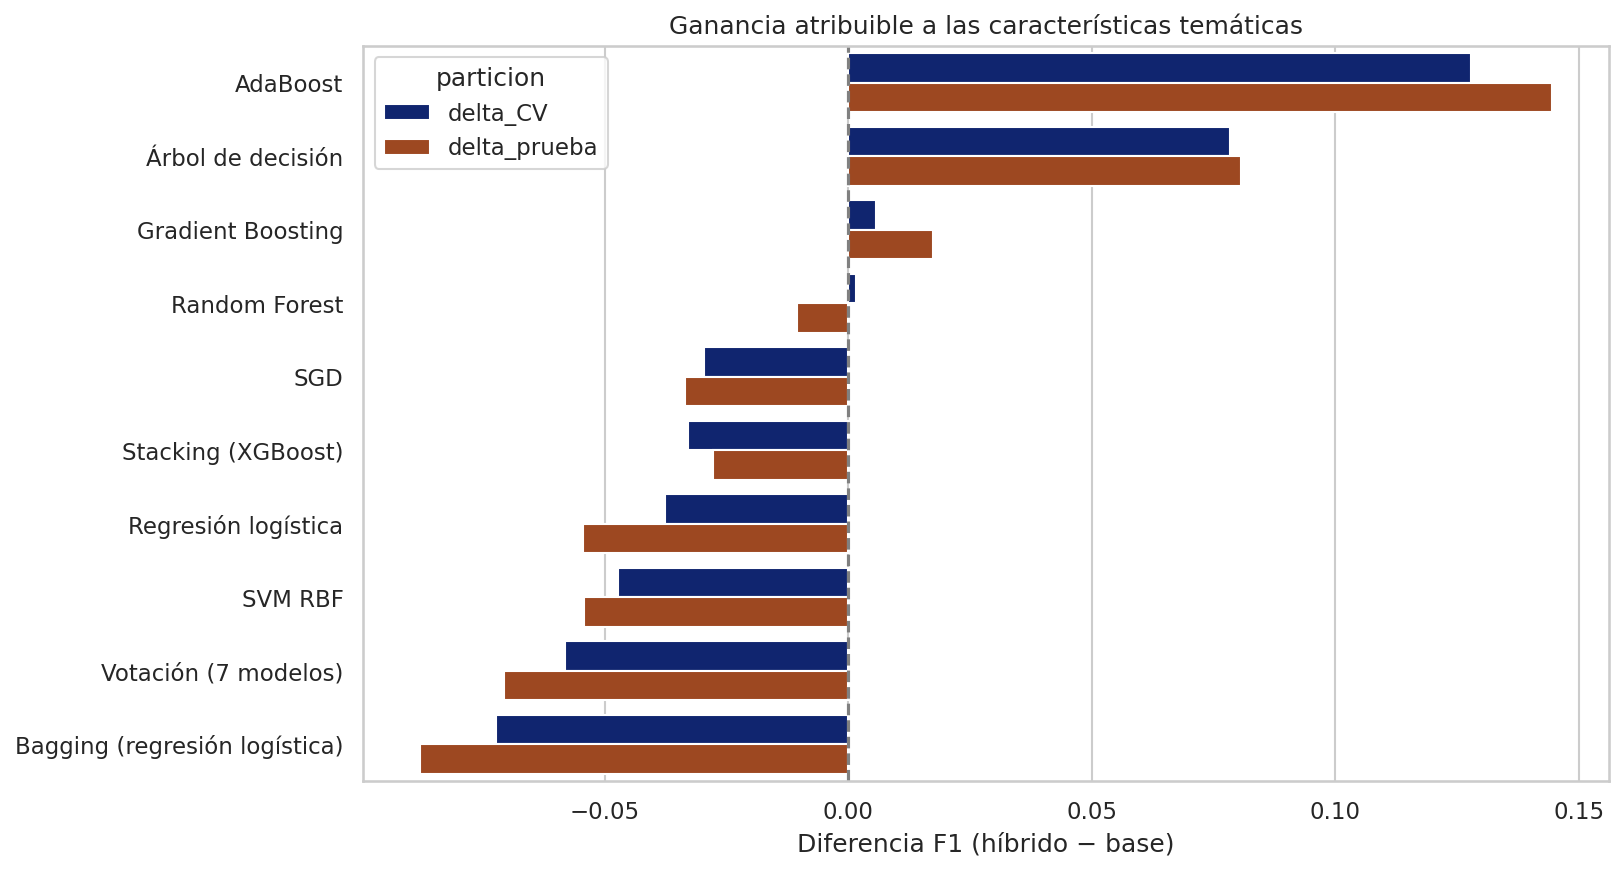

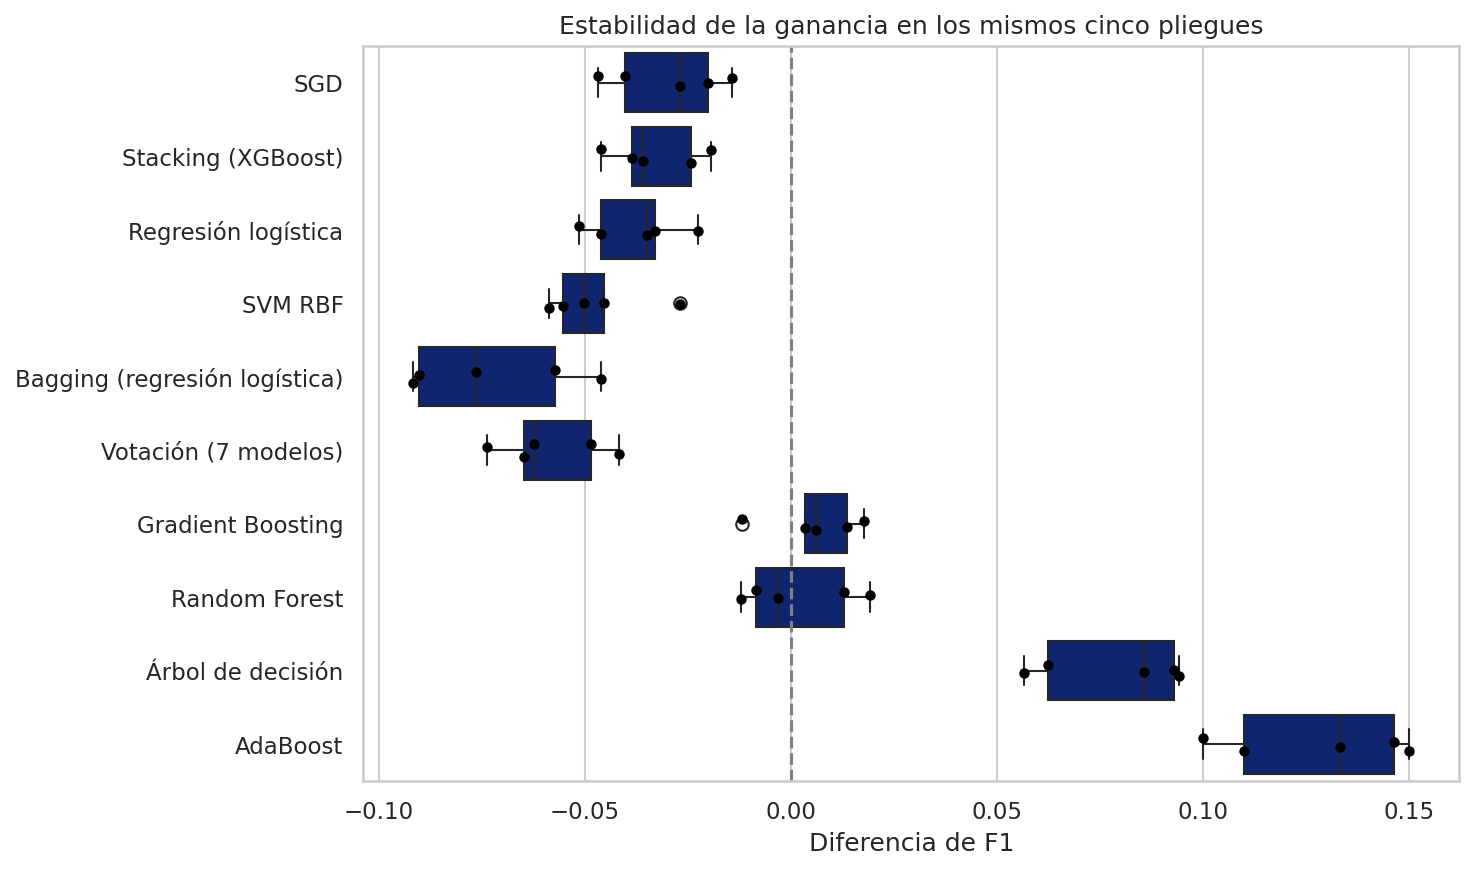

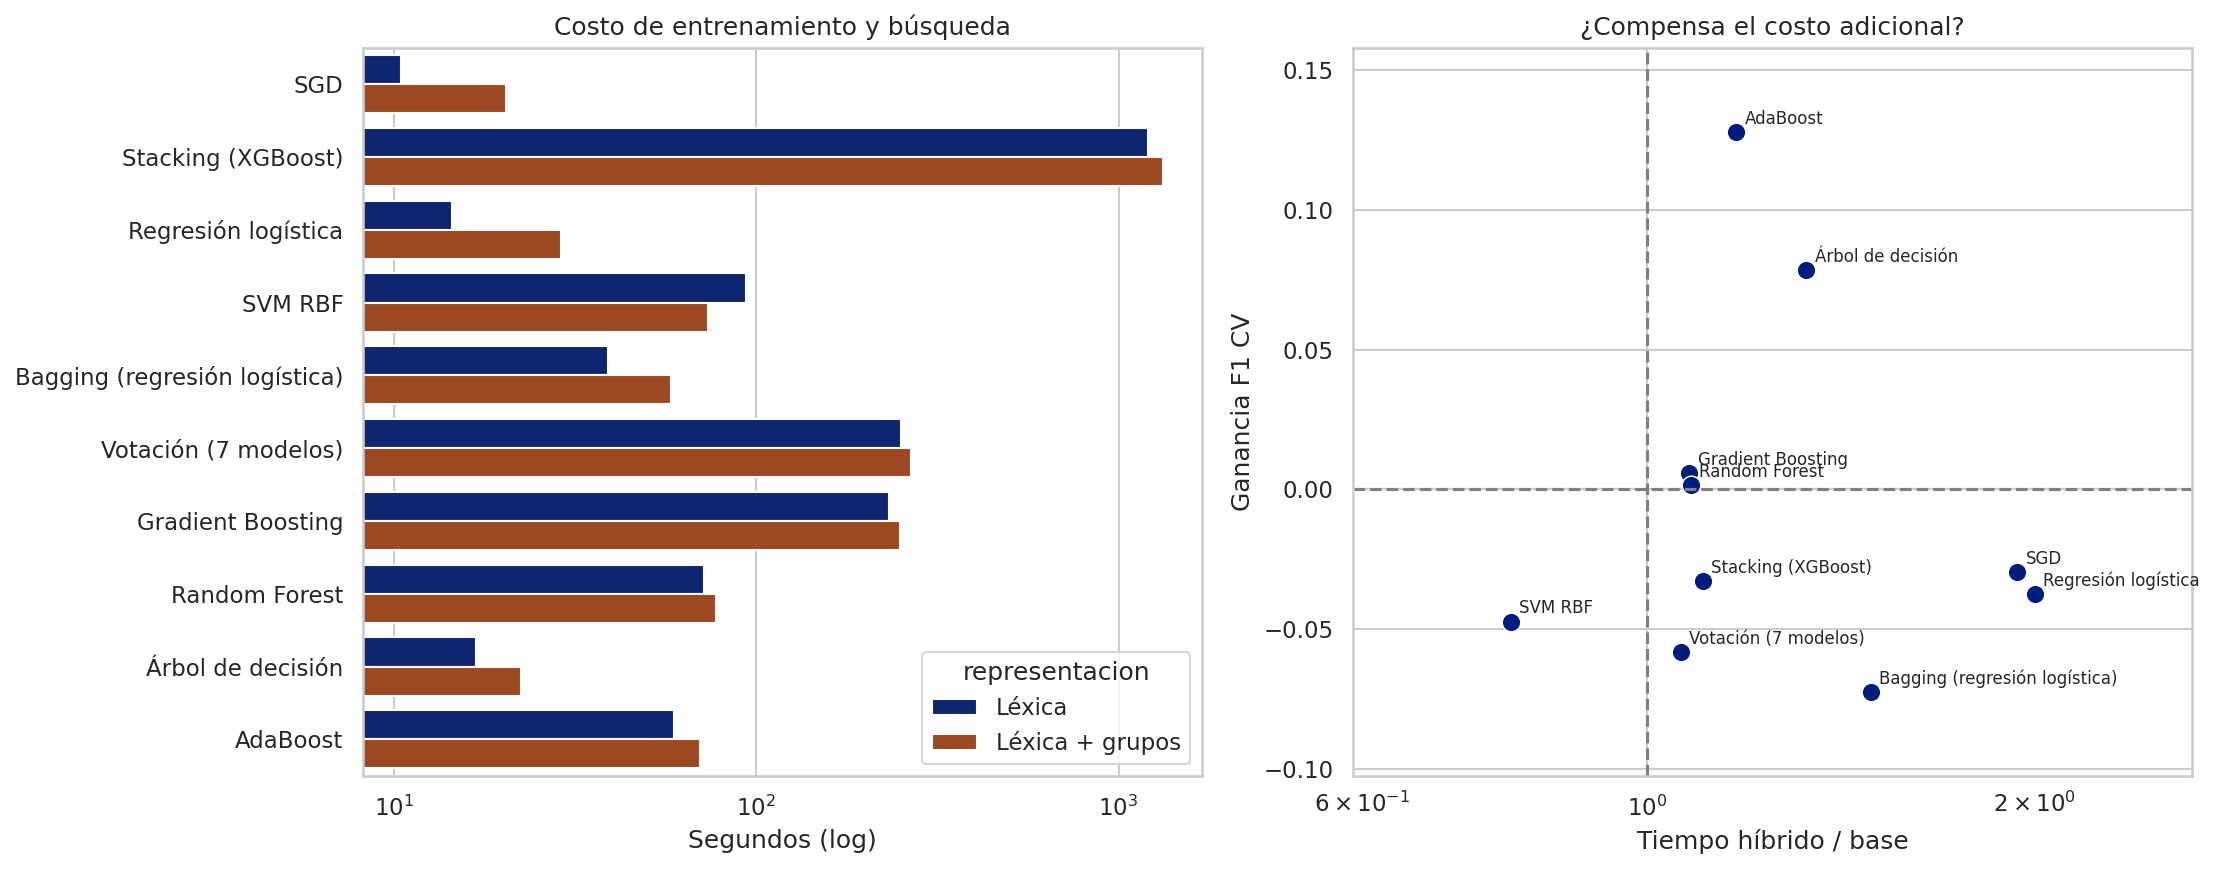

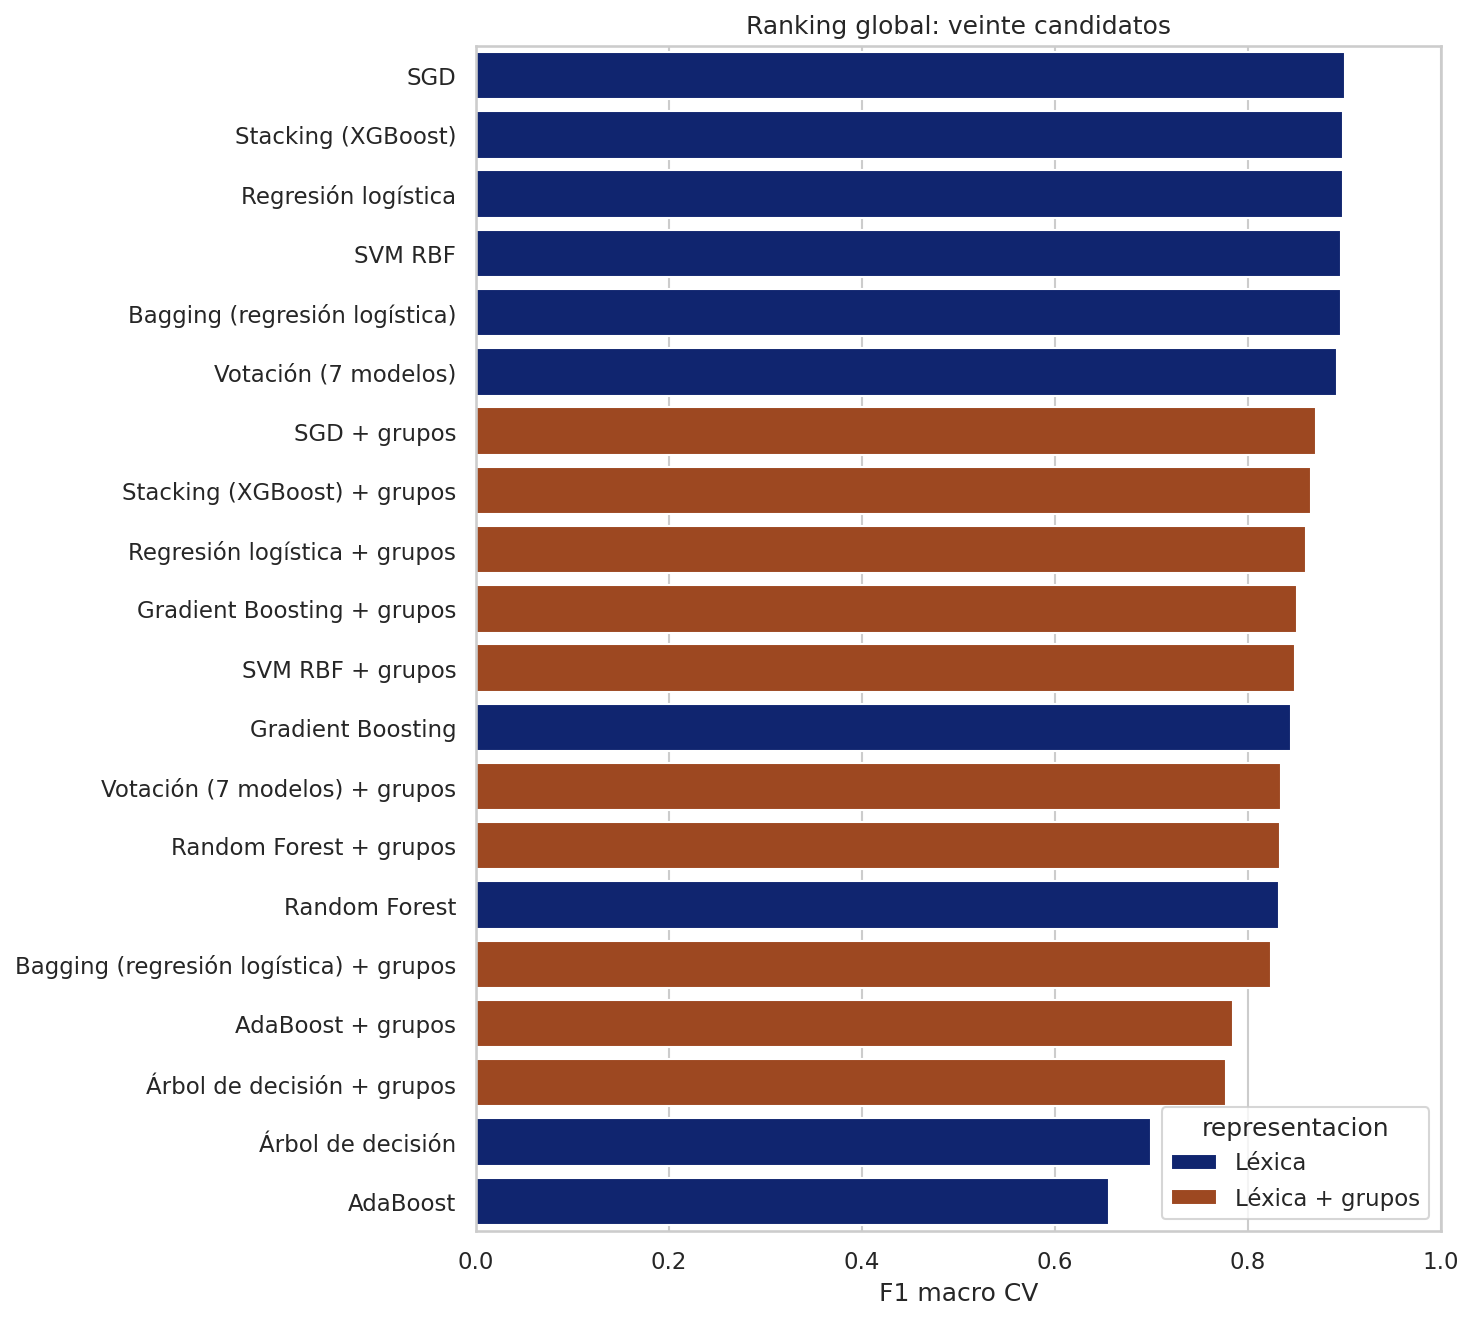

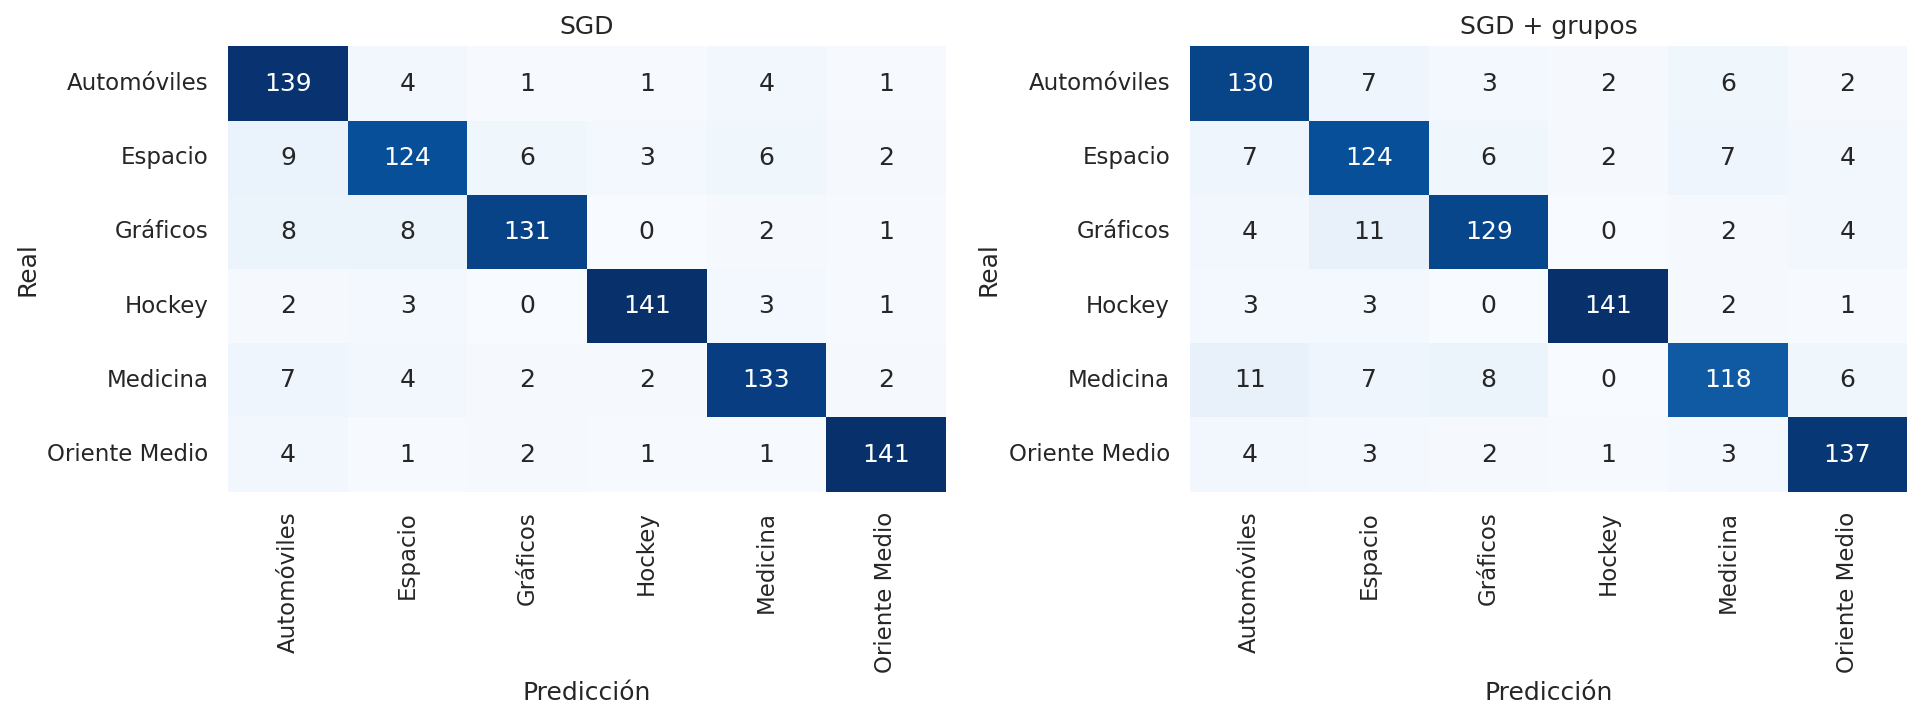

In [82]:
tabla("hibrido","ranking_global",["modelo","representacion","F1_CV","F1","segundos"])
mostrar("hibrido","02_ganancia","03_estabilidad_ganancia","05_costo_ganancia","06_ranking_global","07_confusiones_finalistas")

## 4. Generalización y complejidad
Se mantiene la regresión logística como referencia y se modifica un factor a la vez.

In [83]:
ejecutar_etapa(ejecutar_generalizacion)

### Representación

,representacion,mean_train_score,mean_test_score
0,BoW,0.9999,0.8524
1,TF-IDF,0.9954,0.8984


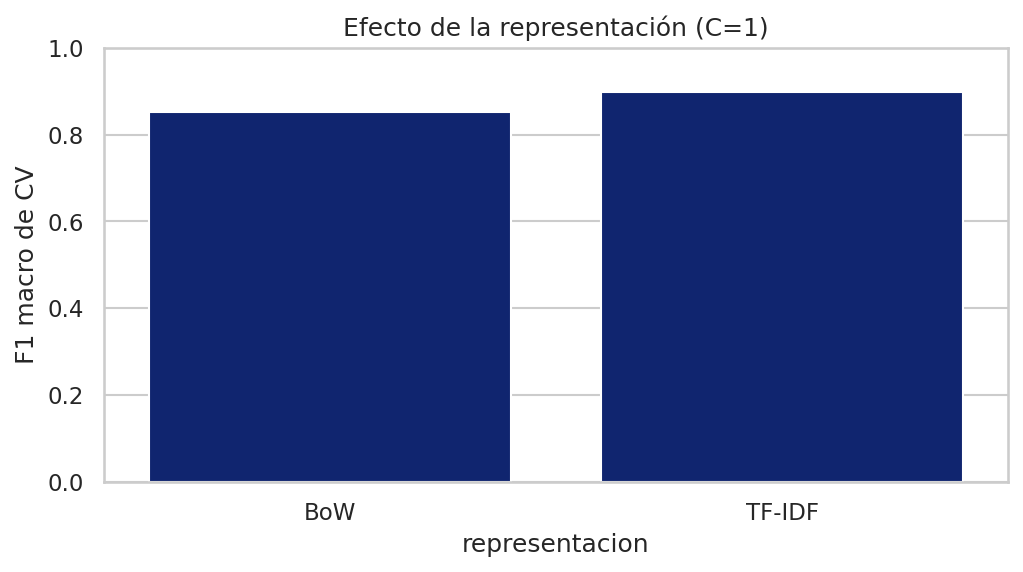

In [84]:
tabla("generalizacion","representacion",["representacion","mean_train_score","mean_test_score"])
mostrar("generalizacion","01_representacion")

### Dimensionalidad

,caracteristicas_max,mean_test_score
0,1000,0.8284
1,3000,0.8751
2,10000,0.8984
3,20000,0.8989


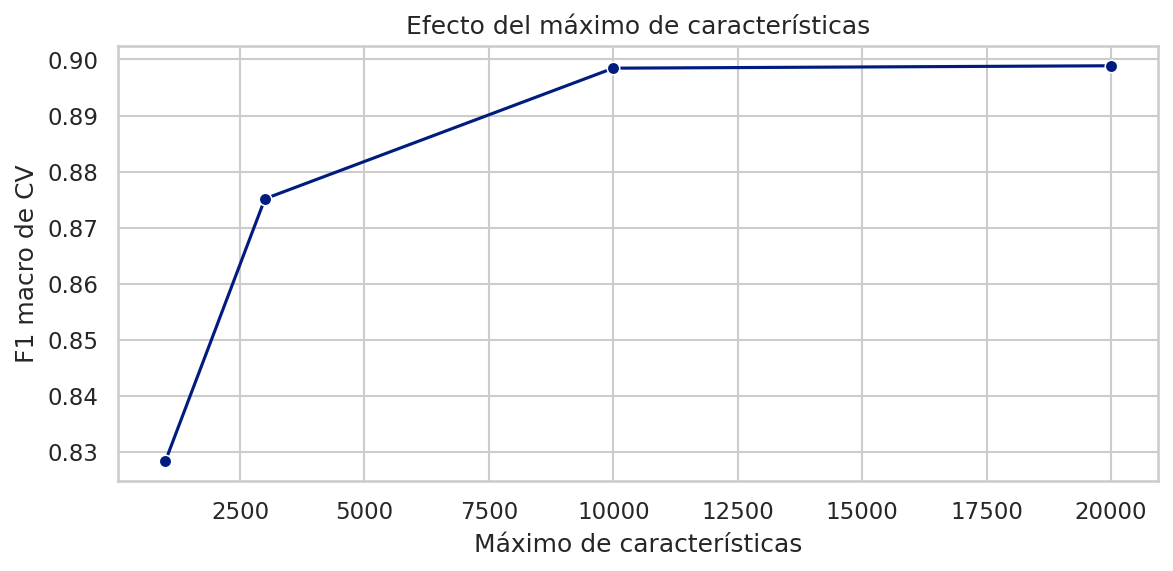

In [85]:
tabla("generalizacion","dimensionalidad",["caracteristicas_max","mean_test_score"])
mostrar("generalizacion","02_dimensionalidad")

,componentes,mean_test_score
0,25,0.8681
1,50,0.8735
2,100,0.8809
3,200,0.8864
4,300,0.8909
5,400,0.8936
6,500,0.8957
7,750,0.8961
8,1000,0.8965


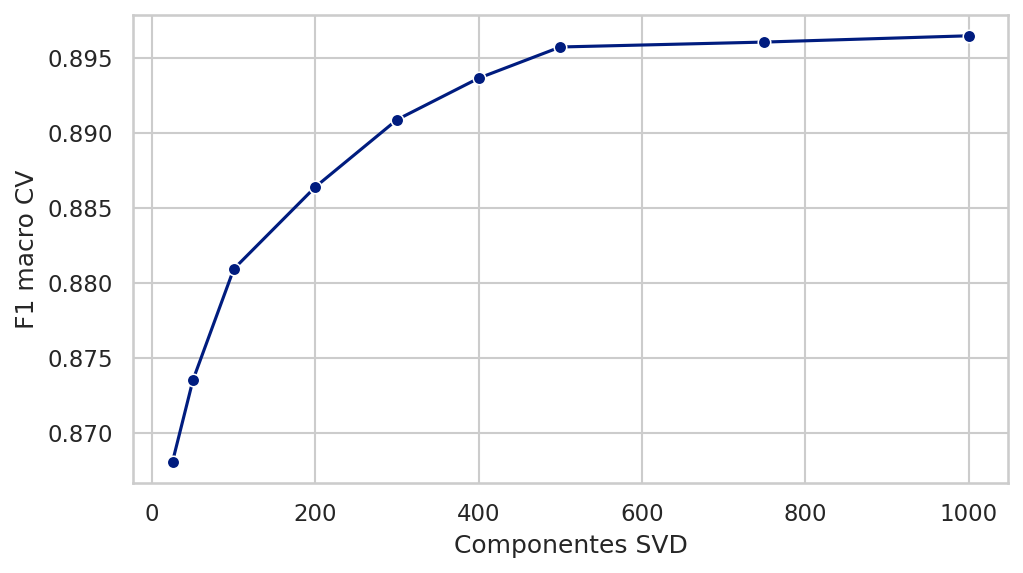

In [86]:
tabla("diagnosticos","componentes_svd",["componentes","mean_test_score"])
mostrar("diagnosticos","03_svd")

### Regularización

,C,error_entrenamiento,error_validacion
0,0.001,0.0329,0.1147
1,0.010,0.0315,0.1119
2,0.100,0.0255,0.1097
3,1.000,0.0046,0.1016
4,10.000,0.0000,0.1041
5,100.000,0.0000,0.1030
6,1000.000,0.0000,0.1084


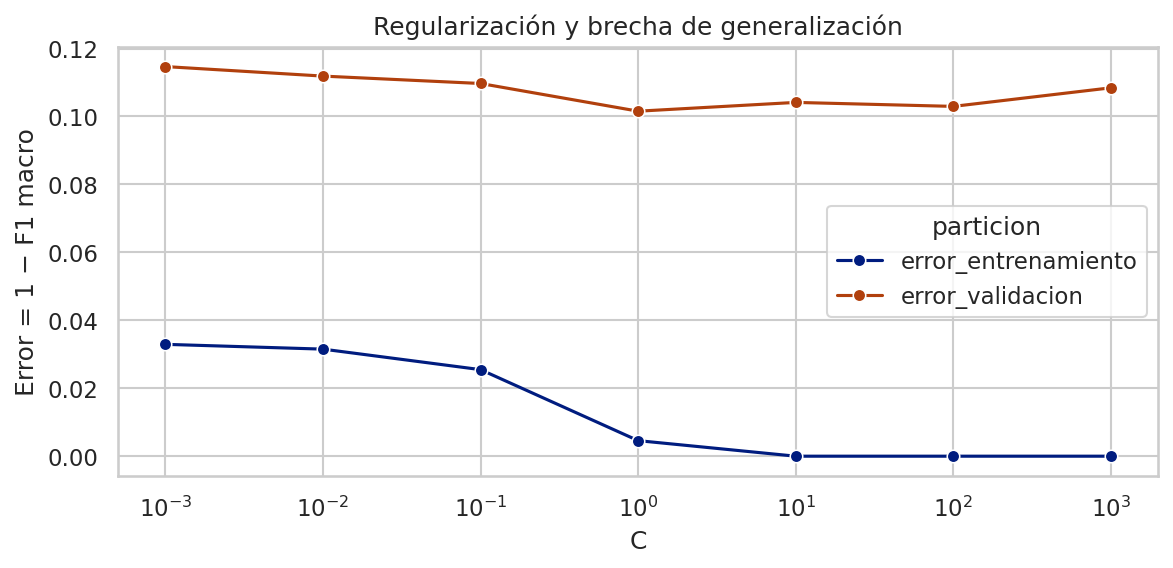

In [87]:
tabla("generalizacion","complejidad",["C","error_entrenamiento","error_validacion"])
mostrar("generalizacion","04_complejidad")

,componentes,mean_test_score
0,25,0.8681
1,50,0.8735
2,100,0.8809
3,200,0.8864


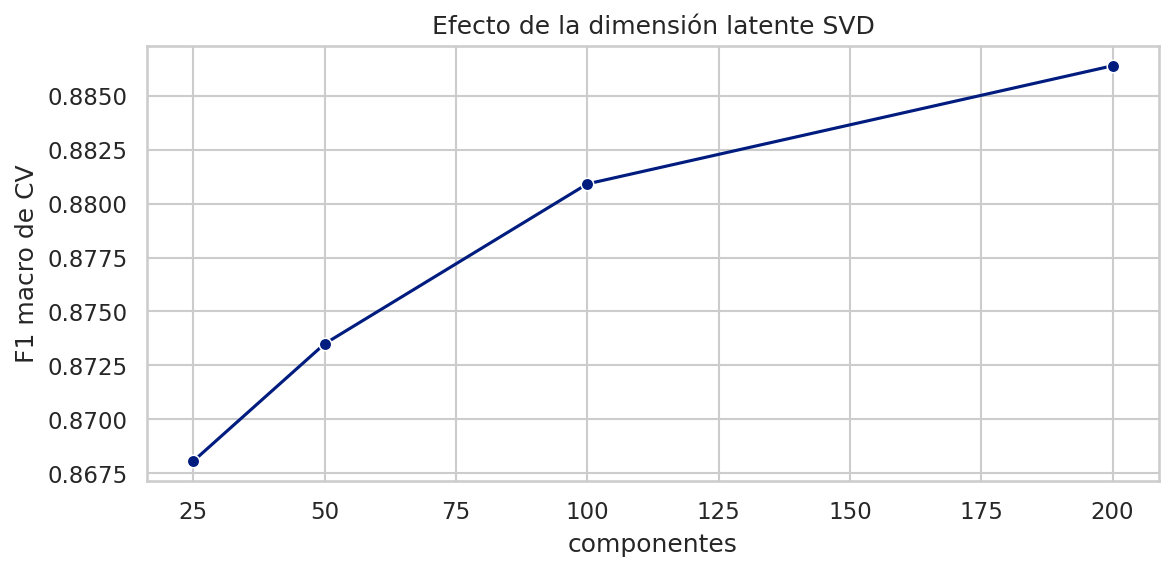

In [88]:
tabla("generalizacion","componentes_svd",["componentes","mean_test_score"])
mostrar("generalizacion","03_componentes_svd")

## 5. Discusión y conclusiones
El ranking y la comparación de costos permiten elegir un modelo sin volver a ajustar a partir de la prueba.

In [89]:
v=leer("clasificacion", "validacion")
m=leer("clasificacion", "metricas_prueba")
print("Seleccionado por CV:",v.iloc[0].modelo)
display(v.merge(m,on="modelo")[["modelo","F1_CV","F1","segundos"]].round(4))

globales=leer("hibrido", "ranking_global")
print("Mejor candidato global por CV:")
display(globales.head(1)[["modelo","representacion","F1_CV","F1"]])
print("La comparación ampliada es exploratoria; no se selecciona por el F1 de prueba.")

Seleccionado por CV: SGD


,modelo,F1_CV,F1,segundos
0,SGD,0.9008,0.8991,10.4711
1,Stacking (XGBoost),0.8988,0.8938,1204.0728
2,Regresión logística,0.8984,0.8959,14.4736
3,SVM RBF,0.8964,0.8922,93.9203
4,Bagging (regresión logística),0.8963,0.9003,38.9470
5,Votación (7 modelos),0.8923,0.8964,251.0318
6,Gradient Boosting,0.8451,0.8584,231.7066
7,Random Forest,0.8322,0.8386,71.5099
8,Árbol de decisión,0.6994,0.6955,16.8725
9,AdaBoost,0.6563,0.6568,59.4053


Mejor candidato global por CV:


,modelo,representacion,F1_CV,F1
0,SGD,Léxica,0.900763,0.899087


La comparación ampliada es exploratoria; no se selecciona por el F1 de prueba.


### Clasificar un texto nuevo

In [90]:
mejor = MODELOS_AJUSTADOS["clasificacion"]
print(mejor.predict([limpiar("The spacecraft entered orbit around Mars.")])[0])

Espacio


### Comprobación de la ejecución completa
Las comprobaciones verifican la cobertura de los experimentos y las predicciones calculadas en esta sesión. No se comparan con cifras históricas.

In [91]:
from sklearn.metrics import f1_score
for etapa, archivo, metrica in [
    ("clasificacion", "predicciones", "metricas_prueba"),
    ("hibrido", "predicciones_hibridas", "metricas_hibridas")
]:
    pred = leer(etapa, archivo)
    assert len(pred)==900 and pred.huella.is_unique and len(pred.columns)==12
    for fila in leer(etapa, metrica).itertuples():
        assert np.isclose(f1_score(pred.real,pred[fila.modelo],average="macro"),fila.F1)
assert len(globales)==20
assert len(leer("hibrido","bootstrap_holm"))==10
assert len(leer("proyecciones","proyecciones_2d"))==19800
assert len(leer("jerarquia","pureza_nodos"))==6599
print("Verificación completa: 20 candidatos, 900 predicciones por modelo, seis proyecciones y diagnósticos.")

Verificación completa: 20 candidatos, 900 predicciones por modelo, seis proyecciones y diagnósticos.


### Exportación opcional
Todo el análisis anterior se ejecuta en memoria. Si deseas conservar tablas, figuras y metadatos, activa la opción de esta última celda. No es necesaria para ejecutar la notebook.

In [92]:
EXPORTAR = False
if EXPORTAR:
    import zipfile
    with zipfile.ZipFile("resultados.zip", "w", compression=zipfile.ZIP_DEFLATED) as archivo:
        for (etapa, nombre), datos_tabla in TABLAS.items():
            archivo.writestr(f"{etapa}_{nombre}.csv", datos_tabla.to_csv(index=False))
        for (etapa, nombre), png in FIGURAS.items():
            archivo.writestr(f"{etapa}_{nombre}.png", png)
        for (etapa, nombre), meta in METADATOS.items():
            archivo.writestr(f"{etapa}_{nombre}.json", json.dumps(meta, ensure_ascii=False, indent=2, default=str))
    if COLAB:
        from google.colab import files
        files.download("resultados.zip")
    else:
        print("Archivo generado: resultados.zip")